# 07 — Por qué EP2 usa `sin_camara` como target

**Qué hacemos acá.** Justificamos con datos por qué en EP2 predecimos `sin_camara` (peatones y ciclistas dentro de la
zona de cámaras) y no el `tiene_camara` de EP1. El notebook se lee de arriba hacia abajo como un argumento: el problema,
la evidencia, las candidatas, el descarte de cada una, la decisión, el problema de negocio que se resuelve, el valor
práctico y las limitaciones.

**Plan de notebooks, uno por número.** El 07 (este) justifica por qué se eligió el target y lo compara con las otras opciones; el 08 analiza los datos del target elegido;
el 09 entrena los modelos supervisados; el 10 evalúa en el test y cierra.

**Reglas que seguimos.**

- Solo usamos segmentos de **train** y los folds de `train.parquet`. El test no se carga en ninguna celda de análisis
  (la única excepción es una verificación de conteos en la Sección 11, sin evaluar modelos).
- Todas las cifras se calculan en el notebook. Los textos de conclusión se generan con f-strings a partir de los resultados.
- Los umbrales de la Sección 3 no se modifican después de ver resultados. Las correcciones metodológicas se reportan
  aparte como "revisión posterior" y decimos si cambian o no la conclusión.

**Honestidad sobre los criterios.** Los criterios se fijaron **antes de correr este notebook, pero después de la
exploración del notebook 06** (ahí ya sabíamos que `tiene_camara` es 0 en vehículos y señales). Este es además el
**segundo intento** del notebook: la versión anterior (`07_decision_target_ep2_v1.ipynb`) se ejecutó una vez con
exactamente los mismos umbrales; esta versión los conserva sin cambios y reorganiza la narrativa y agrega pruebas.

**Entradas:** `train.parquet`, `config_features.json`, `split_segmentos.csv`, `waymo_con_target` (catálogo Kedro, filtrado a
segmentos de train), `docs/seleccion_segmentos/*.csv` y, si existe, `data/01_raw/waymo/vehicle_pose/`.
**Salidas:** `images/07_*.png`, `data/08_reporting/decision_target_ep2.csv`, `docs/decision_target_ep2.md`.

<a id="seccion-0"></a>
## 0. Resumen ejecutivo

*(Texto generado por la celda "Resumen ejecutivo generado" en la última ejecución; se copia acá para leerlo arriba. Si se vuelve a ejecutar el notebook, hay que volver a copiarlo.)*

**Decisión.** Target elegido para EP2: B.

**Razones**

1. `tiene_camara` en todos los objetos queda dominado por la clase: vehículos y señales tienen 0 positivos en 265.377 filas, y una regla de una línea da AUC 0,975 (el modelo, 0,992).
2. `sin_camara` en peatones y ciclistas dentro de la zona de cámaras es la clase rara (23,2 %) y se predice con AUC 0,854 (IC 95 % 0,810–0,897), con AUC mínimo por fold 0,824 y brechas Day/Night de 0,000.
3. El desplazamiento a 2 s (C) no mejora la velocidad constante: error 0,28 m contra 0,29 m del modelo (-2,4 %); peatón vs ciclista (D) y conflicto (E) también se descartan (D: 2.105 filas de ciclistas en 12 segmentos y bajo valor de negocio; E: 68 casos de conflicto en 5 objetos).
4. Valor práctico (versión previa, población de 120°): para encontrar el 80 % de las cajas 3D etiquetadas sin par 2D hay que revisar el 39,1 % de los frames con el modelo, el 50,5 % con la regla simple de menos puntos LiDAR primero y el 80,0 % al azar (modelo menos regla: -11.4 puntos, IC 95 % -19.0 a -6.1). En el tope de la lista (Captura@20 %) la ventaja sobre la regla es pequeña (+3.5 puntos): el modelo aporta más en alta cobertura. **Actualización:** la población principal pasa a |azimut| ≤ 100° y, frente a la regla geométrica, la diferencia del HGB en la población de 120° es +4.8 puntos en Fracción para 80 % (IC -1.3 a +9.1); la ventaja de la versión previa no se sostiene. Recomendación del 09: Regla: menos puntos top.

**Limitaciones**

- Los puntos LiDAR sostienen el modelo (sin ellos AUC 0,654): modela cobertura de etiquetado y calidad de observación, no visibilidad física de la cámara, y no sirve como alerta dentro del auto.
- Pocos ciclistas, muestra con etiquetado denso, folds estratificados por `tiene_camara`, y un test de 8 segmentos con etiquetado muy desigual (`sin_camara` de 1,5 % a 33,6 % por segmento).
- El movimiento del auto para C se estimó con señales de tránsito porque no había vehicle_pose.

Detalle del problema de negocio en la [Sección 8](#seccion-8).

---

### Actualización posterior al 08 y 09

**La población principal pasa de 120° a |azimut| ≤ 100° por el hallazgo de la franja** (notebook 08, A.6 y A.7: la tasa de `sin_camara` sube a 62,2 % en 100–120°). El target (`sin_camara`), el split y el veredicto no cambian.

**Cifras de este notebook que eran para la población de 120° y quedan como versión previa:**

- Sección 5 (B): AUC 0,854, PR-AUC 0,747, AUC mínimo por fold 0,824, brecha Day/Night 0,000
- Sección 7: los criterios de B de la tabla de decisión se evaluaron en la población de 120°
- Sección 8.4 y 9: Fracción para 80 % de 39,1 % (modelo) y 50,5 % (regla de puntos), diferencia de -11.4 puntos
- Sección 11.1: los conteos del test de 17.297 filas de B y 4.378 positivos son de la población de 120° (para la principal, ver el párrafo de conteos de esa sección)

Las secciones 4 (A), 6 (C, D, E) y 10 no dependen del límite de azimut de B (usan todos los objetos o todos los peatones y ciclistas) y no cambian.

**Actualización posterior al 08 y 09 (las cifras de arriba son de la versión previa, población de 120°).** La población principal pasó de 120° a |azimut| ≤ 100° porque en 100–120° la ausencia de par 2D es en buena parte geométrica (08). En la población principal (64.509 filas) el mejor baseline simple es Regla: menos puntos top (AUC 0,862, Fracción para 80 % 37,8 %) y la recomendación del 09 es **Regla: menos puntos top**. En la población de 120°, con los modelos reentrenados en el 09, el HGB menos la regla de puntos da -9.0 puntos en Fracción para 80 % (IC -20.0 a -2.0) y menos la regla geométrica +4.8 puntos (IC -1.3 a +9.1): la ventaja de -11.4 puntos frente a la regla de puntos de la versión previa **no se sostiene** al compararla con un baseline geométrico.

## Configuración y carga

Mismas rutas y funciones `cargar` / `guardar_fig` que el notebook 06.

In [1]:
from pathlib import Path
import json
import shutil
import subprocess
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEMILLA = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

# Raiz del proyecto: con Kedro viene en `context`; si no, se busca hacia arriba.
try:
    RAIZ = Path(context.project_path)
except NameError:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists())

RUTA_IMAGENES = RAIZ / "images"
RUTA_MODEL_INPUT = RAIZ / "data" / "05_model_input"
RUTA_REPORTING = RAIZ / "data" / "08_reporting"
RUTA_DOCS = RAIZ / "docs"
RUTA_POSE = RAIZ / "data" / "01_raw" / "waymo" / "vehicle_pose"
RUTA_IMAGENES.mkdir(exist_ok=True)
RUTA_REPORTING.mkdir(parents=True, exist_ok=True)


def cargar(nombre, ruta_relativa):
    # Carga desde el catalogo de Kedro; si no hay catalogo, lee el archivo directo.
    try:
        return catalog.load(nombre)
    except NameError:
        ruta = RAIZ / ruta_relativa
        return pd.read_csv(ruta) if ruta.suffix == ".csv" else pd.read_parquet(ruta)


def guardar_fig(fig, nombre):
    fig.savefig(RUTA_IMAGENES / f"{nombre}.png", dpi=150, bbox_inches="tight")


AZUL, NARANJA, GRIS, VERDE = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e"
VRU = ["PEDESTRIAN", "CYCLIST"]
AZ_MAX = 100          # limite de la poblacion principal (definido despues del hallazgo de A.6 del 08; el target y el split no cambian)
ZONA_CAMARAS_DEG = 120      # |azimut| <= 120: zona que las camaras alcanzan a cubrir
RES = {}                    # resultados que alimentan la tabla de decision (Seccion 7)
print(f"Raiz del proyecto: {RAIZ}")

Raiz del proyecto: C:\Users\maico\waymo-evaluacion


In [2]:
def pct(x, d=1):
    return f"{x * 100:.{d}f} %".replace(".", ",")


def n2(x, d=2):
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    return f"{int(x):,}".replace(",", ".")


from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, f1_score, precision_recall_curve)


GEOMETRIA = ["box_center_x", "box_center_y", "azimut_abs_deg", "distancia_m"]


def md_tabla(df, indice=True):
    # Tabla Markdown sin depender de tabulate.
    d = df.reset_index() if indice else df
    cab = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
    return cab + "\n".join("| " + " | ".join(str(v) for v in fila) + " |" for fila in d.values)

In [3]:
config = json.loads((RUTA_MODEL_INPUT / "config_features.json").read_text(encoding="utf-8"))
FEATURES_NUM, FEATURES_CAT = config["features_num"], config["features_cat"]
TARGET, GRUPO = config["target"], config["grupo"]
SEGS_TEST = set(config["segmentos_test"])

train = pd.read_parquet(RUTA_MODEL_INPUT / "train.parquet")
SEGS_TRAIN = sorted(train[GRUPO].unique())
assert SEGS_TEST.isdisjoint(SEGS_TRAIN), "Hay segmentos de test en train"
assert (train.groupby(GRUPO)["fold"].nunique() == 1).all(), "Un segmento aparece en dos folds"
FOLD_SEG = train.groupby(GRUPO)["fold"].first()
FOLDS = [int(k) for k in sorted(train["fold"].unique())]
print(f"train.parquet: {len(train):,} filas | {len(SEGS_TRAIN)} segmentos | folds {FOLDS} | segmentos de test excluidos: {len(SEGS_TEST)}")

# split_segmentos.csv (ahora conserva segment_id): se contrasta con train.parquet
split = pd.read_csv(RUTA_MODEL_INPUT / "split_segmentos.csv")
print("Columnas de split_segmentos.csv:", list(split.columns))
tr_csv = split[split["conjunto"] == "train"].set_index("segment_id")
print(f"Segmentos train en el CSV: {len(tr_csv)} | mismos segmentos que train.parquet: {set(tr_csv.index) == set(SEGS_TRAIN)} | "
      f"mismos folds: {bool((tr_csv['fold'].astype(int) == FOLD_SEG.reindex(tr_csv.index)).all())} | "
      f"segmentos test del CSV == config: {set(split.loc[split['conjunto'] == 'test', 'segment_id']) == SEGS_TEST}")

train.parquet: 366,314 filas | 33 segmentos | folds [0, 1, 2, 3, 4] | segmentos de test excluidos: 8
Columnas de split_segmentos.csv: ['segment_id', 'location', 'time_of_day', 'filas', 'positivos', 'ciclistas', 'conjunto', 'fold']
Segmentos train en el CSV: 33 | mismos segmentos que train.parquet: True | mismos folds: True | segmentos test del CSV == config: True


In [4]:
def preparar_columnas(d):
    # Misma funcion del notebook 06: variables geometricas derivadas. Ninguna usa la camara.
    d = d.copy()
    d["azimut_deg"] = np.degrees(np.arctan2(d["box_center_y"], d["box_center_x"]))   # 0 = frente del auto
    d["azimut_abs_deg"] = d["azimut_deg"].abs()
    d["heading_sin"] = np.sin(d["[LiDARBoxComponent].box.heading"])
    d["heading_cos"] = np.cos(d["[LiDARBoxComponent].box.heading"])
    d["num_top_lidar_points"] = d["[LiDARBoxComponent].num_top_lidar_points_in_box"]
    return d


# waymo_con_target: todos los frames de los segmentos (se necesitan frames consecutivos para el movimiento).
completo = cargar("waymo_con_target", "data/02_intermediate/waymo_con_target.parquet")
completo = completo[completo["segment_id"].isin(SEGS_TRAIN)]
completo = preparar_columnas(completo).reset_index(drop=True)
assert SEGS_TEST.isdisjoint(completo["segment_id"].unique())
print(f"waymo_con_target restringido a train: {len(completo):,} filas | {completo['segment_id'].nunique()} segmentos | "
      f"frames etiquetados: {int(completo['frame_etiquetado'].sum()):,}")

[10/18/26 13:10:08] INFO     Loading data from waymo_con_target (ParquetDataset)...            ]8;id=15257331;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=15257332;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

waymo_con_target restringido a train: 393,698 filas | 33 segmentos | frames etiquetados: 366,314


<a id="seccion-1"></a>
# 1. Por qué tuvimos que redirigir el target

**Por qué importa.** Un target sirve si lo que predice no se puede obtener gratis. Si la respuesta ya la da el tipo de
objeto, el modelo parece bueno sin haber aprendido nada sobre las cámaras. Acá medimos cuánto de `tiene_camara` es solo clase.

## 1.1 `object_type` × `tiene_camara` (train)

In [5]:
ct = pd.crosstab(train["object_type"], train[TARGET], margins=True)
ct["pct_positivo"] = (ct[1] / ct["All"] * 100).round(1)
print(ct)
no_vru = train[~train["object_type"].isin(VRU)]
print(f"\nPositivos entre VEHICLE + SIGN: {int(no_vru[TARGET].sum())} de {len(no_vru):,} filas.")
print(f"Positivos entre peatones/ciclistas: {int(train.loc[train['object_type'].isin(VRU), TARGET].sum()):,}")

tiene_camara       0      1     All  pct_positivo
object_type                                      
CYCLIST          723   1382    2105          65.7
PEDESTRIAN     47543  51289   98832          51.9
SIGN           99618      0   99618           0.0
VEHICLE       165759      0  165759           0.0
All           313643  52671  366314          14.4

Positivos entre VEHICLE + SIGN: 0 de 265,377 filas.
Positivos entre peatones/ciclistas: 52,671


In [6]:
t_vru = train["object_type"].isin(VRU)
p_ped = train.loc[train["object_type"] == "PEDESTRIAN", TARGET].mean()
p_cic = train.loc[train["object_type"] == "CYCLIST", TARGET].mean()
display(Markdown(
    f"**Lectura.** De {miles(len(train))} filas de train, {miles(len(no_vru))} son `VEHICLE` o `SIGN` y **ninguna** tiene confirmación de cámara "
    f"({int(no_vru[TARGET].sum())} positivos). Solo `PEDESTRIAN` ({pct(p_ped)} positivos) y `CYCLIST` ({pct(p_cic)}) tienen confirmación; "
    f"entre los dos suman {miles(t_vru.sum())} filas, el {pct(t_vru.mean())} de train. Los datos son consistentes con que la asociación cámara-LiDAR de Waymo v2 "
    f"solo existe para peatones y ciclistas.\n\n"
    f"**Consecuencia.** En EP1 el target mezclaba dos preguntas distintas: \"¿qué clase de objeto es?\" y \"¿lo confirma una cámara?\". "
    f"Para el {pct(1 - t_vru.mean())} de las filas la respuesta es 0 solo por ser vehículo o señal, de modo que un modelo obtiene gran parte de su métrica "
    f"de la clase del objeto y no de la cobertura de las cámaras."))

**Lectura.** De 366.314 filas de train, 265.377 son `VEHICLE` o `SIGN` y **ninguna** tiene confirmación de cámara (0 positivos). Solo `PEDESTRIAN` (51,9 % positivos) y `CYCLIST` (65,7 %) tienen confirmación; entre los dos suman 100.937 filas, el 27,6 % de train. Los datos son consistentes con que la asociación cámara-LiDAR de Waymo v2 solo existe para peatones y ciclistas.

**Consecuencia.** En EP1 el target mezclaba dos preguntas distintas: "¿qué clase de objeto es?" y "¿lo confirma una cámara?". Para el 72,4 % de las filas la respuesta es 0 solo por ser vehículo o señal, de modo que un modelo obtiene gran parte de su métrica de la clase del objeto y no de la cobertura de las cámaras.

## 1.2 Tasa de positivos entre peatones y ciclistas

In [7]:
pc = train[train["object_type"].isin(VRU)]
print(f"Peatones + ciclistas: {len(pc):,} filas ({len(pc) / len(train):.1%}) | positivos {int(pc[TARGET].sum()):,} ({pc[TARGET].mean():.1%})")
print("\nTasa (%) entre peatones/ciclistas, por ubicacion x momento del dia:")
print((pc.groupby(["location", "time_of_day"])[TARGET].mean().unstack() * 100).round(1))
print("\nFilas de peatones/ciclistas por ubicacion x momento del dia:")
print(pc.groupby(["location", "time_of_day"]).size().unstack())
print("\nTasa (%) entre peatones/ciclistas por segmento (distribucion):")
print((pc.groupby(GRUPO)[TARGET].mean() * 100).describe().round(1).to_string())

Peatones + ciclistas: 100,937 filas (27.6%) | positivos 52,671 (52.2%)

Tasa (%) entre peatones/ciclistas, por ubicacion x momento del dia:
time_of_day     Dawn/Dusk   Day  Night
location                              
location_other       59.3  73.2   71.4
location_phx         72.2  70.2   62.1
location_sf          62.3  53.8   34.2

Filas de peatones/ciclistas por ubicacion x momento del dia:
time_of_day     Dawn/Dusk    Day  Night
location                               
location_other       2817   1785   1094
location_phx         1883   4779   7304
location_sf         14233  40072  26970

Tasa (%) entre peatones/ciclistas por segmento (distribucion):
count    33.0
mean     63.7
std      17.3
min      27.7
25%      53.1
50%      62.0
75%      71.4
max      98.7


## 1.3 Contexto de la selección de segmentos

In [8]:
docs = RAIZ / "docs" / "seleccion_segmentos"
inv = pd.read_csv(docs / "inventario_segmentos.csv").set_index("segment_id")
inv["ped_cyc"] = inv["PEDESTRIAN"] + inv["CYCLIST"]
reg = pd.read_csv(docs / "registro_verificacion_ep2.csv").merge(inv[["ped_cyc"]], left_on="segment_id", right_index=True)
motivo = reg["motivo"].fillna("")
reg["grupo"] = np.select([reg["resultado"].eq("seleccionado"), motivo.str.contains("vacia"), motivo.str.contains("ralo")],
                         ["seleccionado", "asociacion vacia", "etiquetado ralo"], default="otro")
reg["positivos_sobre_ped_cyc"] = reg["positivos"] / reg["ped_cyc"].where(reg["ped_cyc"] > 0)
resumen_sel = reg.groupby("grupo").agg(
    segmentos=("segment_id", "size"), sin_peatones_ni_ciclistas=("ped_cyc", lambda s: int((s == 0).sum())),
    mediana_ped_cyc=("ped_cyc", "median"), mediana_positivos_sobre_ped_cyc=("positivos_sobre_ped_cyc", "median")).round(2)
print("Segmentos evaluados en la seleccion de EP2:")
print(resumen_sel.to_string())
n_sel = int(resumen_sel.loc["seleccionado", "segmentos"])
n_vacia = int(resumen_sel.loc["asociacion vacia", "segmentos"]) if "asociacion vacia" in resumen_sel.index else 0
n_ralo = int(resumen_sel.loc["etiquetado ralo", "segmentos"]) if "etiquetado ralo" in resumen_sel.index else 0
display(Markdown(f"De {len(reg)} segmentos evaluados, {n_sel} se seleccionaron; {n_vacia} se descartaron por asociación cámara-LiDAR vacía "
                 f"y {n_ralo} por etiquetado ralo. La muestra está **condicionada a segmentos con etiquetado de cámara denso** (ver limitaciones)."))

Segmentos evaluados en la seleccion de EP2:
                  segmentos  sin_peatones_ni_ciclistas  mediana_ped_cyc  mediana_positivos_sobre_ped_cyc
grupo                                                                                                   
asociacion vacia         27                         22              0.0                             0.00
etiquetado ralo          21                          0            336.0                             0.41
otro                      2                          0            134.0                             0.00
seleccionado             41                          0           1382.0                             0.58


De 91 segmentos evaluados, 41 se seleccionaron; 27 se descartaron por asociación cámara-LiDAR vacía y 21 por etiquetado ralo. La muestra está **condicionada a segmentos con etiquetado de cámara denso** (ver limitaciones).

<a id="seccion-2"></a>
# 2. Candidatas

**Por qué importa.** Antes de descartar, ponemos todas las opciones sobre la mesa con la pregunta de negocio que
contesta cada una. Una candidata solo vale si responde algo que alguien necesita saber.

| | Target | Tipo | Población | Pregunta de negocio |
|---|---|---|---|---|
| **A** | `tiene_camara` (EP1) | clasificación | todos los objetos | ¿Esta caja 3D etiquetada tiene su par 2D de cámara? |
| **B** | `sin_camara` = 1 − `tiene_camara` | clasificación | peatones y ciclistas con \|azimut\| ≤ 120 | ¿Qué cajas 3D etiquetadas de usuarios vulnerables dentro de la zona de cámaras no tienen su par 2D y conviene revisar primero? |
| **C** | desplazamiento a 2 s (residuo sobre velocidad constante) | regresión | peatones y ciclistas | ¿Hacia dónde se moverá este usuario vulnerable en 2 s? |
| **D** | peatón vs ciclista | clasificación de clase | peatones y ciclistas | ¿Qué tipo de usuario vulnerable es? |
| **E** | conflicto con el corredor del auto a 2 s | clasificación | peatones y ciclistas | ¿Entrará este usuario al corredor frente al auto en 2 s? |

<a id="seccion-3"></a>
# 3. Criterios a priori

**Por qué importa.** Si los umbrales se eligen después de ver los resultados, cualquier candidata se puede declarar
ganadora. Por eso se escribieron antes de correr este notebook y no se tocan.

**Honestidad.** Los criterios se fijaron antes de correr este notebook, **pero después de la exploración del notebook 06**,
y la versión anterior de este notebook ya se ejecutó una vez con ellos. Los valores de la celda siguiente son idénticos a los de esa versión.

- **A** pasa si el modelo supera a la mejor regla trivial por ≥ 0,05 de AUC-ROC y ≥ 0,05 de PR-AUC, y la supera en ≥ 4 de 5 folds.
- **B** pasa si con todas las variables: AUC ≥ 0,70; AUC por fold ≥ 0,60 en todos; PR-AUC supera a la prevalencia por ≥ 0,10; brecha de AUC
  Day vs Night ≤ 0,10 y entre ubicaciones ≤ 0,10 (grupos con ≥ 200 filas por clase); prevalencia entre 5 % y 50 %.
- **C** pasa si el mejor modelo reduce el error medio de posición a 2 s ≥ 10 % frente a la mejor línea base de velocidad constante,
  con IC 95 % (bootstrap por segmento) con límite inferior > 0; sin `speed_mps` ≥ 5 % con IC inferior > 0; mejora en ≥ 4 de 5 folds;
  desplazamiento mediano ≥ 0,5 m; y ≥ 60 % de las filas con historia y futuro utilizables.
- **Apoyo no supervisado** (no decide solo): silhouette ≥ 0,25, estabilidad por segmento (ARI) ≥ 0,80 y cociente de error entre clusters ≥ 1,5.
- **Desempate** si pasa más de una: B > C > A.

**Nota sobre el criterio de A.** Exige +0,05 de AUC sobre una regla que ya alcanza un valor cercano a 0,975 (se calcula en la Sección 4);
el techo de mejora es entonces `1 − AUC de la regla`, cercano a 0,025, menor que lo exigido. Dejamos el criterio tal como estaba
(no se cambia después de ver resultados), pero **interpretamos A también con PR-AUC y F1** y la conclusión que sacamos es
"A está dominado por la clase del objeto y la zona de cámaras", no "A es inútil".

In [9]:
CRITERIOS = {
    "A": {"delta_auc_min": 0.05, "delta_prauc_min": 0.05, "folds_mejora_min": 4},
    "B": {"auc_min": 0.70, "auc_fold_min": 0.60, "delta_prauc_min": 0.10,
          "brecha_dia_noche_max": 0.10, "brecha_ubicacion_max": 0.10,
          "prevalencia_rango": (0.05, 0.50), "min_filas_por_clase_grupo": 200,
          "aporte_no_geometrico_info": 0.02},
    "C": {"mejora_rel_min": 0.10, "mejora_rel_sin_speed_min": 0.05, "ic_inferior_min": 0.0,
          "folds_mejora_min": 4, "desplazamiento_mediano_min_m": 0.5, "cobertura_min": 0.60},
    "apoyo": {"silhouette_min": 0.25, "ari_min": 0.80, "razon_error_clusters_min": 1.5},
    "desempate": ["B", "C", "A"],
}
print(CRITERIOS)

{'A': {'delta_auc_min': 0.05, 'delta_prauc_min': 0.05, 'folds_mejora_min': 4}, 'B': {'auc_min': 0.7, 'auc_fold_min': 0.6, 'delta_prauc_min': 0.1, 'brecha_dia_noche_max': 0.1, 'brecha_ubicacion_max': 0.1, 'prevalencia_rango': (0.05, 0.5), 'min_filas_por_clase_grupo': 200, 'aporte_no_geometrico_info': 0.02}, 'C': {'mejora_rel_min': 0.1, 'mejora_rel_sin_speed_min': 0.05, 'ic_inferior_min': 0.0, 'folds_mejora_min': 4, 'desplazamiento_mediano_min_m': 0.5, 'cobertura_min': 0.6}, 'apoyo': {'silhouette_min': 0.25, 'ari_min': 0.8, 'razon_error_clusters_min': 1.5}, 'desempate': ['B', 'C', 'A']}


<a id="seccion-4"></a>
# 4. Descarte de A: `tiene_camara` en todos los objetos

**Por qué importa.** Si una regla sin aprendizaje ya consigue casi todo el rendimiento, el modelo no está aportando
conocimiento sobre las cámaras. Comparamos el modelo con dos reglas: **R1** "es peatón/ciclista" y **R2** "es peatón/ciclista
y |azimut| ≤ 120". Todo es *out-of-fold* con los folds de `train.parquet`.

Prevalencia de positivos (train): 0.144
                                          AUC  PR-AUC  Recall@0.5  F1@0.5  AUC min fold
metodo                                                                                 
Modelo HGB                              0.992   0.931       0.933   0.909         0.991
R1: es peaton/ciclista                  0.923   0.522       1.000   0.686         0.889
R2: es peaton/ciclista y |azimut|<=120  0.975   0.768       1.000   0.869         0.968

Mejor regla trivial: R2: es peaton/ciclista y |azimut|<=120
Modelo - mejor regla: AUC +0.018 | PR-AUC +0.163 | folds donde el modelo gana en AUC: 5 de 5

AUC por fold:
        Modelo HGB  R1: es peaton/ciclista  R2: es peaton/ciclista y |azimut|<=120
fold 0       0.997                   0.946                                   0.984
fold 1       0.992                   0.943                                   0.974
fold 2       0.992                   0.889                                   0.968
fold 3       0.992 

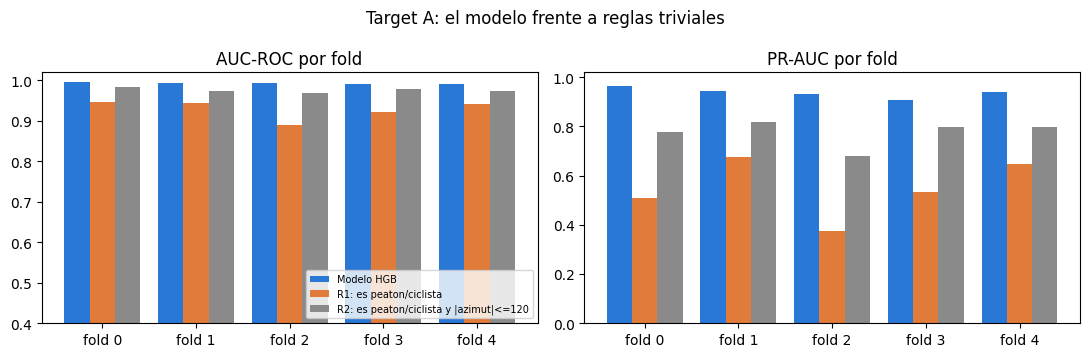

In [10]:
def oof_clasificador(X, y, folds, **kw):
    # Predicciones fuera de fold con los folds ya definidos (agrupados por segmento).
    oof = np.zeros(len(X))
    for k in sorted(np.unique(folds)):
        tr, va = folds != k, folds == k
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA, **kw)
        m.fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])[:, 1]
    return oof


def auc_pr(y, s):
    if len(np.unique(y)) < 2:
        return np.nan, np.nan
    return roc_auc_score(y, s), average_precision_score(y, s)


def por_fold(y, s, folds):
    return np.array([auc_pr(y[folds == k], s[folds == k]) for k in sorted(np.unique(folds))])   # (folds, 2)


XA = pd.concat([train[FEATURES_NUM], pd.get_dummies(train["object_type"], prefix="tipo", dtype=int)], axis=1).values
yA, fA = train[TARGET].values, train["fold"].values
es_vru = train["object_type"].isin(VRU).values
reglas = {"R1: es peaton/ciclista": es_vru.astype(float),
          "R2: es peaton/ciclista y |azimut|<=120": (es_vru & (train["azimut_abs_deg"].values <= ZONA_CAMARAS_DEG)).astype(float)}
scoreA = {"Modelo HGB": oof_clasificador(XA, yA, fA), **reglas}

filas, pf = [], {}
for nombre, s in scoreA.items():
    auc, pr = auc_pr(yA, s)
    pred = s >= 0.5
    pf[nombre] = por_fold(yA, s, fA)
    filas.append({"metodo": nombre, "AUC": auc, "PR-AUC": pr, "Recall@0.5": recall_score(yA, pred),
                  "F1@0.5": f1_score(yA, pred), "AUC min fold": np.nanmin(pf[nombre][:, 0])})
tablaA = pd.DataFrame(filas).set_index("metodo")
print(f"Prevalencia de positivos (train): {yA.mean():.3f}")
print(tablaA.round(3).to_string())

mejor_regla = max(reglas, key=lambda n: tablaA.loc[n, "AUC"])
d_auc = tablaA.loc["Modelo HGB", "AUC"] - tablaA.loc[mejor_regla, "AUC"]
d_pr = tablaA.loc["Modelo HGB", "PR-AUC"] - tablaA.loc[mejor_regla, "PR-AUC"]
folds_mejora = int((pf["Modelo HGB"][:, 0] > pf[mejor_regla][:, 0]).sum())
print(f"\nMejor regla trivial: {mejor_regla}")
print(f"Modelo - mejor regla: AUC {d_auc:+.3f} | PR-AUC {d_pr:+.3f} | folds donde el modelo gana en AUC: {folds_mejora} de {len(FOLDS)}")
print("\nAUC por fold:")
print(pd.DataFrame({n: v[:, 0] for n, v in pf.items()}, index=[f"fold {k}" for k in FOLDS]).round(3))
RES["A"] = {"mejor_regla": mejor_regla, "auc_modelo": tablaA.loc["Modelo HGB", "AUC"], "auc_regla": tablaA.loc[mejor_regla, "AUC"],
            "prauc_modelo": tablaA.loc["Modelo HGB", "PR-AUC"], "prauc_regla": tablaA.loc[mejor_regla, "PR-AUC"],
            "delta_auc": d_auc, "delta_prauc": d_pr, "folds_mejora": folds_mejora}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cols = [AZUL, NARANJA, GRIS]
for ax, j, tit in zip(axes, [0, 1], ["AUC-ROC por fold", "PR-AUC por fold"]):
    w = 0.27
    for i, (n, v) in enumerate(pf.items()):
        ax.bar(np.arange(len(FOLDS)) + (i - 1) * w, v[:, j], width=w, color=cols[i], label=n)
    ax.set_xticks(range(len(FOLDS)), [f"fold {k}" for k in FOLDS])
    ax.set_title(tit)
    ax.set_ylim(0.4 if j == 0 else 0, 1.02)
axes[0].legend(fontsize=7, loc="lower right")
fig.suptitle("Target A: el modelo frente a reglas triviales")
fig.tight_layout()
guardar_fig(fig, "07_A_modelo_vs_reglas")
plt.show()

In [11]:
techo_auc = 1 - RES["A"]["auc_regla"]
frac_techo = RES["A"]["delta_auc"] / techo_auc
f1_modelo, f1_regla = tablaA.loc["Modelo HGB", "F1@0.5"], tablaA.loc[RES["A"]["mejor_regla"], "F1@0.5"]
rec_modelo, rec_regla = tablaA.loc["Modelo HGB", "Recall@0.5"], tablaA.loc[RES["A"]["mejor_regla"], "Recall@0.5"]
RES["A"].update({"techo_auc": techo_auc, "frac_techo": frac_techo, "f1_modelo": f1_modelo, "f1_regla": f1_regla})
print(f"Techo de mejora de AUC sobre la mejor regla: {techo_auc:.3f} | el modelo recupera {frac_techo:.0%} de ese techo")
a = RES["A"]
pasa_auc = a["delta_auc"] >= CRITERIOS["A"]["delta_auc_min"]
display(Markdown(
    f"**Conclusión (generada).** La mejor regla trivial ({a['mejor_regla']}) ya logra AUC {n2(a['auc_regla'], 3)}, PR-AUC {n2(a['prauc_regla'], 3)} y F1 {n2(f1_regla, 3)} "
    f"sin aprender nada. El modelo llega a AUC {n2(a['auc_modelo'], 3)}, PR-AUC {n2(a['prauc_modelo'], 3)} y F1 {n2(f1_modelo, 3)}: "
    f"+{n2(a['delta_auc'], 3)} de AUC (el techo era {n2(techo_auc, 3)}, recupera {pct(frac_techo, 0)}), +{n2(a['delta_prauc'], 3)} de PR-AUC y +{n2(f1_modelo - f1_regla, 3)} de F1, "
    f"y gana en {a['folds_mejora']} de {len(FOLDS)} folds. "
    + ("El criterio de AUC se cumple." if pasa_auc else f"El criterio de AUC (+{CRITERIOS['A']['delta_auc_min']}) **no se cumple**, aunque su techo ({n2(techo_auc, 3)}) era menor que lo exigido; "
       "el de PR-AUC " + ("sí se cumple." if a["delta_prauc"] >= CRITERIOS["A"]["delta_prauc_min"] else "tampoco se cumple.")) +
    " Leemos el resultado así: **A está dominado por la clase del objeto y la zona de cámaras**. El modelo agrega algo (sobre todo en PR-AUC y F1), "
    "pero casi toda la señal ya está en dos reglas de una línea; el aporte que queda es pequeño y se concentra en peatones y ciclistas, "
    "que es justamente la población de B."))

Techo de mejora de AUC sobre la mejor regla: 0.025 | el modelo recupera 70% de ese techo


**Conclusión (generada).** La mejor regla trivial (R2: es peaton/ciclista y |azimut|<=120) ya logra AUC 0,975, PR-AUC 0,768 y F1 0,869 sin aprender nada. El modelo llega a AUC 0,992, PR-AUC 0,931 y F1 0,909: +0,018 de AUC (el techo era 0,025, recupera 70 %), +0,163 de PR-AUC y +0,040 de F1, y gana en 5 de 5 folds. El criterio de AUC (+0.05) **no se cumple**, aunque su techo (0,025) era menor que lo exigido; el de PR-AUC sí se cumple. Leemos el resultado así: **A está dominado por la clase del objeto y la zona de cámaras**. El modelo agrega algo (sobre todo en PR-AUC y F1), pero casi toda la señal ya está en dos reglas de una línea; el aporte que queda es pequeño y se concentra en peatones y ciclistas, que es justamente la población de B.

<a id="seccion-5"></a>
# 5. Comparación explícita y baselines de B

**Por qué importa.** Dentro de peatones y ciclistas en zona de cámaras, predecir "tiene cámara" o "no tiene cámara" es el mismo
problema visto desde dos lados. Pero las métricas se comportan distinto según cuál sea la clase positiva, y eso decide qué
conclusión podemos sacar de un número.

## 5.1 `sin_camara` vs `tiene_camara` en la misma población

Mismos datos y mismo modelo (HistGradientBoosting con todas las variables). Solo cambia la clase positiva: para `tiene_camara`
usamos el complemento de la probabilidad del mismo modelo, por eso el AUC es idéntico.

In [12]:
bz = train[train["object_type"].isin(VRU) & (train["azimut_abs_deg"] <= ZONA_CAMARAS_DEG)].reset_index(drop=True)
bz["es_ciclista"] = (bz["object_type"] == "CYCLIST").astype(int)
yB, fB = (1 - bz[TARGET]).values, bz["fold"].values
prevalencia_B = yB.mean()
print(f"Poblacion B: {len(bz):,} filas ({len(bz) / train['object_type'].isin(VRU).sum():.1%} de los peatones/ciclistas) en {bz[GRUPO].nunique()} segmentos")
print(f"Prevalencia de sin_camara: {prevalencia_B:.3f} | por fold: {pd.Series(yB).groupby(fB).mean().round(3).to_dict()}")

GEOM_B = GEOMETRIA + ["es_ciclista"]
TODAS_B = FEATURES_NUM + ["es_ciclista"]
scoreB = {"solo clase": oof_clasificador(bz[["es_ciclista"]].values, yB, fB),
          "geometria": oof_clasificador(bz[GEOM_B].values, yB, fB),
          "todas las variables": oof_clasificador(bz[TODAS_B].values, yB, fB)}
pfB = {n: por_fold(yB, s, fB) for n, s in scoreB.items()}

filas = []
for n, s in scoreB.items():
    auc, pr = auc_pr(yB, s)
    filas.append({"variables": n, "AUC": auc, "PR-AUC": pr, "PR-AUC - prevalencia": pr - prevalencia_B,
                  "AUC min fold": pfB[n][:, 0].min(), "AUC max fold": pfB[n][:, 0].max()})
tablaB = pd.DataFrame(filas).set_index("variables")
print(tablaB.round(3).to_string())
print("\nPor fold (AUC / PR-AUC / prevalencia):")
print(pd.DataFrame({**{f"AUC {n}": v[:, 0] for n, v in pfB.items() if n != "solo clase"},
                    **{f"PR {n}": v[:, 1] for n, v in pfB.items() if n != "solo clase"},
                    "prevalencia": pd.Series(yB).groupby(fB).mean().values}, index=[f"fold {k}" for k in FOLDS]).round(3))

Poblacion B: 68,555 filas (67.9% de los peatones/ciclistas) en 33 segmentos
Prevalencia de sin_camara: 0.232 | por fold: {0: 0.223, 1: 0.182, 2: 0.322, 3: 0.202, 4: 0.204}


                       AUC  PR-AUC  PR-AUC - prevalencia  AUC min fold  AUC max fold
variables                                                                           
solo clase           0.447   0.215                -0.017         0.500         0.528
geometria            0.634   0.422                 0.191         0.556         0.701
todas las variables  0.854   0.747                 0.516         0.824         0.888

Por fold (AUC / PR-AUC / prevalencia):
        AUC geometria  AUC todas las variables  PR geometria  PR todas las variables  prevalencia
fold 0          0.556                    0.886         0.343                   0.758        0.223
fold 1          0.566                    0.853         0.273                   0.759        0.182
fold 2          0.701                    0.888         0.584                   0.832        0.322
fold 3          0.636                    0.824         0.435                   0.727        0.202
fold 4          0.654                    0.83

In [13]:
s_sin = scoreB["todas las variables"]
vistas = {"sin_camara (clase positiva rara)": (yB, s_sin), "tiene_camara (clase positiva mayoritaria)": (1 - yB, 1 - s_sin)}
filas = []
for nombre, (yy, ss) in vistas.items():
    p = yy.mean()
    auc, pr = auc_pr(yy, ss)
    filas.append({"clase positiva": nombre, "prevalencia": p, "AUC": auc, "PR-AUC": pr, "PR-AUC - prevalencia": pr - p,
                  "F1 'todo positivo'": 2 * p / (1 + p), "F1 modelo@0.5": f1_score(yy, ss >= 0.5)})
comp_vistas = pd.DataFrame(filas).set_index("clase positiva")
print(comp_vistas.round(3).to_string())
v_sin, v_tie = comp_vistas.iloc[0], comp_vistas.iloc[1]
RES["vistas"] = {"prev_sin": v_sin["prevalencia"], "prev_tie": v_tie["prevalencia"], "f1_todo_tie": v_tie["F1 'todo positivo'"], "f1_todo_sin": v_sin["F1 'todo positivo'"],
                 "f1_mod_tie": v_tie["F1 modelo@0.5"], "f1_mod_sin": v_sin["F1 modelo@0.5"], "dpr_tie": v_tie["PR-AUC - prevalencia"], "dpr_sin": v_sin["PR-AUC - prevalencia"]}
display(Markdown(
    f"**Conclusión (generada).** Con `tiene_camara` como positiva ({pct(v_tie['prevalencia'])} de la población) el clasificador que dice \"todos tienen cámara\" "
    f"ya obtiene F1 {n2(RES['vistas']['f1_todo_tie'], 3)}, y el modelo logra {n2(v_tie['F1 modelo@0.5'], 3)}: la mejora real es chica y las métricas lucen altas "
    f"casi por construcción. Con `sin_camara` ({pct(v_sin['prevalencia'])}) el baseline \"todo positivo\" da F1 {n2(RES['vistas']['f1_todo_sin'], 3)}, el modelo {n2(v_sin['F1 modelo@0.5'], 3)} "
    f"y la PR-AUC supera a la prevalencia por {n2(v_sin['PR-AUC - prevalencia'], 3)} (contra {n2(v_tie['PR-AUC - prevalencia'], 3)} en la vista opuesta). "
    f"El AUC es el mismo ({n2(v_sin['AUC'], 3)}) en las dos vistas: son simétricas. **El análisis principal es sobre `sin_camara`** porque es la clase rara "
    f"y es la que queremos encontrar; sus métricas son exigentes y no se inflan con la clase mayoritaria."))

                                           prevalencia    AUC  PR-AUC  PR-AUC - prevalencia  F1 'todo positivo'  F1 modelo@0.5
clase positiva                                                                                                                
sin_camara (clase positiva rara)                 0.232  0.854   0.747                 0.516               0.376          0.658
tiene_camara (clase positiva mayoritaria)        0.768  0.854   0.929                 0.161               0.869          0.908


**Conclusión (generada).** Con `tiene_camara` como positiva (76,8 % de la población) el clasificador que dice "todos tienen cámara" ya obtiene F1 0,869, y el modelo logra 0,908: la mejora real es chica y las métricas lucen altas casi por construcción. Con `sin_camara` (23,2 %) el baseline "todo positivo" da F1 0,376, el modelo 0,658 y la PR-AUC supera a la prevalencia por 0,516 (contra 0,161 en la vista opuesta). El AUC es el mismo (0,854) en las dos vistas: son simétricas. **El análisis principal es sobre `sin_camara`** porque es la clase rara y es la que queremos encontrar; sus métricas son exigentes y no se inflan con la clase mayoritaria.

## 5.2 Baselines de B: solo clase, geometría y todas las variables

IC 95 % por bootstrap de segmentos, AUC por fold y por momento del día y ubicación. La ablación por grupos de variables va justo después.

AUC todas las variables: 0.854 (IC95% 0.810-0.897)
AUC geometria sola:      0.634
Aporte de las variables no geometricas: +0.219 (IC95% +0.175 a +0.281)

Por momento del dia y ubicacion (NaN = menos de 200 filas en alguna clase):
                  grupo  filas  segmentos  prevalencia  AUC geometria  PR geometria  AUC todas las variables  PR todas las variables
  time_of_day=Dawn/Dusk  15064         10        0.210          0.632         0.343                    0.798                   0.655
        time_of_day=Day  32818         12        0.201          0.614         0.388                    0.873                   0.772
      time_of_day=Night  20673         11        0.297          0.673         0.519                    0.873                   0.789
location=location_other   4384          5        0.143          0.482         0.230                    0.912                   0.734
  location=location_phx  11391         15        0.188          0.618         0.383                    0.

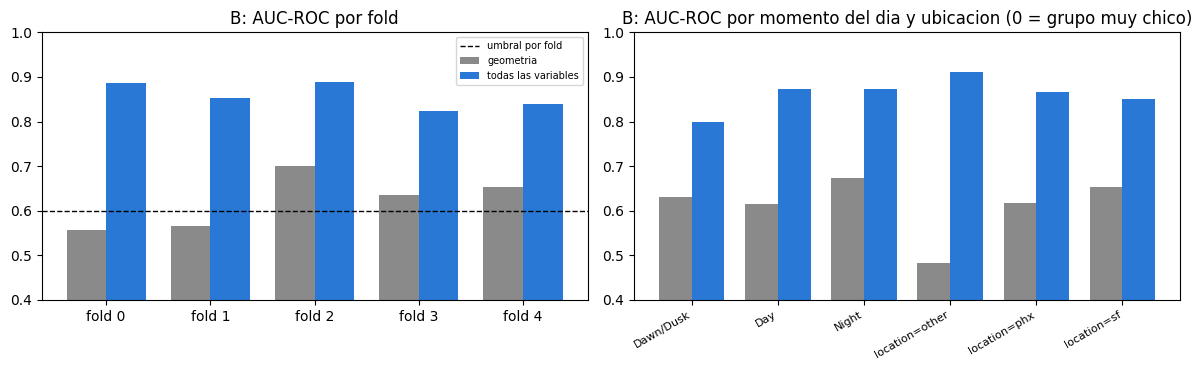

In [14]:
# IC 95% por bootstrap de segmentos (remuestrea segmentos completos)
rng = np.random.default_rng(SEMILLA)
idx_seg = {s: np.where(bz[GRUPO].values == s)[0] for s in bz[GRUPO].unique()}
segs_b = np.array(list(idx_seg))
aucs, deltas = [], []
for _ in range(300):
    ii = np.concatenate([idx_seg[s] for s in rng.choice(segs_b, len(segs_b), replace=True)])
    if len(np.unique(yB[ii])) < 2:
        continue
    a_all = roc_auc_score(yB[ii], scoreB["todas las variables"][ii])
    a_geo = roc_auc_score(yB[ii], scoreB["geometria"][ii])
    aucs.append(a_all)
    deltas.append(a_all - a_geo)
ic_auc = np.percentile(aucs, [2.5, 97.5])
ic_delta = np.percentile(deltas, [2.5, 97.5])
auc_all, auc_geo = tablaB.loc["todas las variables", "AUC"], tablaB.loc["geometria", "AUC"]
print(f"AUC todas las variables: {auc_all:.3f} (IC95% {ic_auc[0]:.3f}-{ic_auc[1]:.3f})")
print(f"AUC geometria sola:      {auc_geo:.3f}")
print(f"Aporte de las variables no geometricas: {auc_all - auc_geo:+.3f} (IC95% {ic_delta[0]:+.3f} a {ic_delta[1]:+.3f})")

def por_grupo(col):
    filas = []
    for v in sorted(bz[col].unique()):
        m = (bz[col] == v).values
        n1, n0 = int(yB[m].sum()), int((1 - yB[m]).sum())
        ok = min(n1, n0) >= CRITERIOS["B"]["min_filas_por_clase_grupo"]
        row = {"grupo": f"{col}={v}", "filas": int(m.sum()), "segmentos": bz.loc[m, GRUPO].nunique(), "prevalencia": yB[m].mean()}
        for n in ["geometria", "todas las variables"]:
            a, p = auc_pr(yB[m], scoreB[n][m]) if ok else (np.nan, np.nan)
            row[f"AUC {n}"], row[f"PR {n}"] = a, p
        filas.append(row)
    return pd.DataFrame(filas)

tabla_grupos = pd.concat([por_grupo("time_of_day"), por_grupo("location")], ignore_index=True)
print("\nPor momento del dia y ubicacion (NaN = menos de 200 filas en alguna clase):")
print(tabla_grupos.round(3).to_string(index=False))

def brecha(col, serie="AUC todas las variables"):
    v = tabla_grupos.loc[tabla_grupos["grupo"].str.startswith(col + "="), serie].dropna()
    return (v.max() - v.min()) if len(v) >= 2 else np.nan

auc_dn = tabla_grupos.set_index("grupo")["AUC todas las variables"]
brecha_dn = abs(auc_dn.get("time_of_day=Day", np.nan) - auc_dn.get("time_of_day=Night", np.nan))
brecha_loc = brecha("location")
print(f"\nBrecha de AUC Day vs Night: {brecha_dn:.3f} | brecha maxima entre ubicaciones: {brecha_loc:.3f}")
RES["B"] = {"prevalencia": prevalencia_B, "auc": auc_all, "auc_ic": ic_auc, "auc_geo": auc_geo, "aporte_nogeo": auc_all - auc_geo,
            "aporte_ic": ic_delta, "prauc": tablaB.loc["todas las variables", "PR-AUC"],
            "delta_prauc": tablaB.loc["todas las variables", "PR-AUC"] - prevalencia_B,
            "auc_min_fold": pfB["todas las variables"][:, 0].min(), "brecha_dn": brecha_dn, "brecha_loc": brecha_loc}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
w = 0.38
for i, (n, c) in enumerate([("geometria", GRIS), ("todas las variables", AZUL)]):
    axes[0].bar(np.arange(len(FOLDS)) + (i - 0.5) * w, pfB[n][:, 0], width=w, color=c, label=n)
axes[0].axhline(CRITERIOS["B"]["auc_fold_min"], color="k", ls="--", lw=1, label="umbral por fold")
axes[0].set_xticks(range(len(FOLDS)), [f"fold {k}" for k in FOLDS])
axes[0].set_ylim(0.4, 1.0); axes[0].set_title("B: AUC-ROC por fold"); axes[0].legend(fontsize=7)
g = tabla_grupos.set_index("grupo")
x = np.arange(len(g))
for i, (n, c) in enumerate([("AUC geometria", GRIS), ("AUC todas las variables", AZUL)]):
    axes[1].bar(x + (i - 0.5) * w, g[n].fillna(0), width=w, color=c)
axes[1].set_xticks(x, [s.replace("time_of_day=", "").replace("location_", "") for s in g.index], rotation=30, ha="right", fontsize=8)
axes[1].set_ylim(0.4, 1.0); axes[1].set_title("B: AUC-ROC por momento del dia y ubicacion (0 = grupo muy chico)")
fig.tight_layout()
guardar_fig(fig, "07_B_auc_folds_grupos")
plt.show()

In [15]:
auc_dd = tabla_grupos.set_index("grupo")["AUC todas las variables"]
brecha_dawn_day = abs(auc_dd.get("time_of_day=Dawn/Dusk", np.nan) - auc_dd.get("time_of_day=Day", np.nan))
RES["B"]["brecha_dawn_day"] = brecha_dawn_day
print(f"Brecha de AUC Dawn/Dusk vs Day: {brecha_dawn_day:.3f} (informativa; el criterio previo era Day vs Night)")

Brecha de AUC Dawn/Dusk vs Day: 0.075 (informativa; el criterio previo era Day vs Night)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Regresion logistica fuera de fold (log1p en variables asimetricas) y regla simple "menos puntos LiDAR primero"
XL = bz[TODAS_B].copy()
for col in ["num_lidar_points", "num_top_lidar_points", "densidad_puntos", "volumen_caja"]:
    XL[col] = np.log1p(XL[col].clip(lower=0))
s_lr = np.zeros(len(bz))
for k in FOLDS:
    tr, va = fB != k, fB == k
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(XL.values[tr], yB[tr])
    s_lr[va] = m.predict_proba(XL.values[va])[:, 1]
s_regla = -bz["num_lidar_points"].values.astype(float)
metodos_auc = {"HGB": scoreB["todas las variables"], "Regresion logistica": s_lr, "Regla: menos puntos LiDAR primero": s_regla}
tabla_metodos_auc = pd.DataFrame({n: {"AUC fuera de fold": auc_pr(yB, sc)[0], "PR-AUC": auc_pr(yB, sc)[1],
                                      "AUC min fold": por_fold(yB, sc, fB)[:, 0].min(), "AUC max fold": por_fold(yB, sc, fB)[:, 0].max()} for n, sc in metodos_auc.items()}).T
print(tabla_metodos_auc.round(3).to_string())
RES["B"]["auc_lr"], RES["B"]["auc_regla"] = tabla_metodos_auc.loc["Regresion logistica", "AUC fuera de fold"], tabla_metodos_auc.loc["Regla: menos puntos LiDAR primero", "AUC fuera de fold"]
display(Markdown(
    f"**Lectura (generada).** Fuera de fold, el HGB logra AUC {n2(tabla_metodos_auc.loc['HGB', 'AUC fuera de fold'], 3)}, la regresión logística {n2(RES['B']['auc_lr'], 3)} y la regla simple de menos puntos LiDAR primero "
    f"{n2(RES['B']['auc_regla'], 3)}, que no usa ningún modelo. La regla simple ya recoge una parte grande de la señal; el HGB agrega {n2(tabla_metodos_auc.loc['HGB', 'AUC fuera de fold'] - RES['B']['auc_regla'], 3)} de AUC sobre ella."))

                                   AUC fuera de fold  PR-AUC  AUC min fold  AUC max fold
HGB                                            0.854   0.747         0.824         0.888
Regresion logistica                            0.838   0.695         0.799         0.914
Regla: menos puntos LiDAR primero              0.797   0.661         0.760         0.830


**Lectura (generada).** Fuera de fold, el HGB logra AUC 0,854, la regresión logística 0,838 y la regla simple de menos puntos LiDAR primero 0,797, que no usa ningún modelo. La regla simple ya recoge una parte grande de la señal; el HGB agrega 0,057 de AUC sobre ella.

In [17]:
GRUPOS_B = {"puntos LiDAR": ["num_lidar_points", "num_top_lidar_points", "densidad_puntos"],
            "tamano de la caja": ["box_length", "box_width", "box_height", "volumen_caja"],
            "velocidad (speed_mps)": ["speed_mps"], "orientacion": ["heading_sin", "heading_cos"], "altura (z)": ["box_center_z"]}
auc_ref = RES["B"]["auc"]
filas = [{"variables": "todas (referencia)", "AUC": auc_ref, "cambio": 0.0}]
for g, cs in GRUPOS_B.items():
    a = roc_auc_score(yB, oof_clasificador(bz[[c for c in TODAS_B if c not in cs]].values, yB, fB))
    filas.append({"variables": f"sin {g}", "AUC": a, "cambio": a - auc_ref})
a_gp = roc_auc_score(yB, oof_clasificador(bz[GEOM_B + GRUPOS_B["puntos LiDAR"]].values, yB, fB))
filas.append({"variables": "geometria + puntos LiDAR", "AUC": a_gp, "cambio": a_gp - auc_ref})
abl_B = pd.DataFrame(filas).set_index("variables")
print(abl_B.round(3).to_string())
RES["B"]["auc_sin_puntos"], RES["B"]["auc_geom_puntos"] = abl_B.loc["sin puntos LiDAR", "AUC"], a_gp

                             AUC  cambio
variables                               
todas (referencia)         0.854   0.000
sin puntos LiDAR           0.654  -0.200
sin tamano de la caja      0.847  -0.007
sin velocidad (speed_mps)  0.850  -0.004
sin orientacion            0.858   0.004
sin altura (z)             0.851  -0.003
geometria + puntos LiDAR   0.841  -0.013


In [18]:
b = RES["B"]
display(Markdown(
    f"**Conclusión (generada).** En la población de B ({miles(len(bz))} filas, {bz[GRUPO].nunique()} segmentos, prevalencia {n2(b['prevalencia'], 3)}), "
    f"la geometría sola da AUC {n2(b['auc_geo'], 3)} y con todas las variables {n2(b['auc'], 3)} (IC 95 % {n2(b['auc_ic'][0], 3)}–{n2(b['auc_ic'][1], 3)}). "
    f"El AUC por fold va de {n2(b['auc_min_fold'], 3)} a {n2(max(pfB['todas las variables'][:, 0]), 3)}. "
    f"Las brechas son: Day vs Night {n2(b['brecha_dn'], 3)}, Dawn/Dusk vs Day {n2(b['brecha_dawn_day'], 3)} y entre ubicaciones {n2(b['brecha_loc'], 3)}. "
    f"La ablación muestra que **los puntos LiDAR son el factor dominante**: sin ellos el AUC baja a {n2(b['auc_sin_puntos'], 3)}, y geometría más puntos da {n2(b['auc_geom_puntos'], 3)}. "
    f"Son atributos del LiDAR disponibles al detectar, no algo derivado de la cámara, así que no lo leemos como fuga; sí significa que B captura sobre todo "
    f"qué tan bien observado quedó el objeto."))

**Conclusión (generada).** En la población de B (68.555 filas, 33 segmentos, prevalencia 0,232), la geometría sola da AUC 0,634 y con todas las variables 0,854 (IC 95 % 0,810–0,897). El AUC por fold va de 0,824 a 0,888. Las brechas son: Day vs Night 0,000, Dawn/Dusk vs Day 0,075 y entre ubicaciones 0,061. La ablación muestra que **los puntos LiDAR son el factor dominante**: sin ellos el AUC baja a 0,654, y geometría más puntos da 0,841. Son atributos del LiDAR disponibles al detectar, no algo derivado de la cámara, así que no lo leemos como fuga; sí significa que B captura sobre todo qué tan bien observado quedó el objeto.

<a id="seccion-6"></a>
# 6. Descarte de C, D y E

**Por qué importa.** Una candidata se descarta con evidencia, no por preferencia. Para cada una mostramos qué probamos
y qué número la deja fuera.

## 6.1 Candidata C: desplazamiento a 2 s de peatones y ciclistas

**Qué se predice.** El desplazamiento del objeto en el mundo entre *t* y *t* + 2 s, en los ejes del auto en *t*. Como el auto también se mueve, hay que
compensar su movimiento con la pose del auto. **Target:** `residuo = desplazamiento real − velocidad constante × 2 s` (velocidad de los últimos 1 s).
Las variables de entrada solo usan información hasta *t*.

### Pose del auto

Buscamos `vehicle_pose` en `data/01_raw/waymo/vehicle_pose/`; si falta y hay `gsutil`, se descarga de
`gs://waymo_open_dataset_v_2_0_1/training/vehicle_pose/`. Si no se puede, el movimiento del auto se estima con las señales de tránsito (SIGN),
que son objetos estáticos.

In [19]:
POSE_COL = "[VehiclePoseComponent].world_from_vehicle.transform"
BUCKET_POSE = "gs://waymo_open_dataset_v_2_0_1/{particion}/vehicle_pose/{seg}.parquet"
RUTA_POSE.mkdir(parents=True, exist_ok=True)


def asegurar_pose(segmentos):
    # Devuelve los segmentos con vehicle_pose local; intenta descargar los que faltan con gsutil.
    faltan = [s for s in segmentos if not (RUTA_POSE / f"{s}.parquet").exists()]
    if faltan:
        gsutil = shutil.which("gsutil")
        print(f"vehicle_pose local: {len(segmentos) - len(faltan)} de {len(segmentos)} segmentos. gsutil: {gsutil or 'NO ENCONTRADO'}")
        if gsutil:
            for s in faltan:
                for particion in ("training", "validation"):
                    r = subprocess.run([gsutil, "cp", BUCKET_POSE.format(particion=particion, seg=s), str(RUTA_POSE)],
                                       capture_output=True, text=True, timeout=300)
                    if r.returncode == 0:
                        break
                else:
                    print(f"  no se pudo descargar {s}: {r.stderr.strip()[-200:]}")
    return [s for s in segmentos if (RUTA_POSE / f"{s}.parquet").exists()]


SEGS_CON_POSE = asegurar_pose(SEGS_TRAIN)
print(f"Segmentos con vehicle_pose: {len(SEGS_CON_POSE)} de {len(SEGS_TRAIN)}")
if len(SEGS_CON_POSE) < len(SEGS_TRAIN):
    print("Para los segmentos sin vehicle_pose el movimiento del auto se ESTIMA con las senales de transito (SIGN):\n"
          "son objetos estaticos, asi que su desplazamiento aparente entre frames es el movimiento del auto.")

vehicle_pose local: 0 de 33 segmentos. gsutil: NO ENCONTRADO
Segmentos con vehicle_pose: 0 de 33
Para los segmentos sin vehicle_pose el movimiento del auto se ESTIMA con las senales de transito (SIGN):
son objetos estaticos, asi que su desplazamiento aparente entre frames es el movimiento del auto.


In [20]:
OFFS = [-10, -5, 5, 20]
completo["fi"] = completo.groupby("segment_id")["key.frame_timestamp_micros"].rank(method="dense").astype(int) - 1
frames = completo.groupby(["segment_id", "fi"])["key.frame_timestamp_micros"].first()      # indice (segmento, frame) -> timestamp
n_frames = frames.groupby(level=0).size()


def kabsch(P, Q):
    # R, t tales que P ~ R Q + t
    mp, mq = P.mean(0), Q.mean(0)
    U, _, Vt = np.linalg.svd((Q - mq).T @ (P - mp))
    R = Vt.T @ np.diag([1, np.sign(np.linalg.det(Vt.T @ U.T))]) @ U.T
    return R, mp - R @ mq


def ajustar_rigido(P, Q, tol=0.3, minimo=3):
    idx = np.arange(len(P))
    for _ in range(4):
        if len(idx) < minimo:
            return None
        R, t = kabsch(P[idx], Q[idx])
        res = np.linalg.norm(P - (Q @ R.T + t), axis=1)
        nuevo = np.where(res < tol)[0]
        if len(nuevo) == len(idx) and (nuevo == idx).all():
            break
        idx = nuevo
    if len(idx) < minimo:
        return None
    return R, t, len(idx), float(np.sqrt((res[idx] ** 2).mean()))


def transformaciones_senales(seg, fis):
    # Estima el movimiento del auto con las senales estaticas del segmento.
    s = completo[(completo["segment_id"] == seg) & (completo["object_type"] == "SIGN") & (completo["distancia_m"] < 60)]
    por_frame = {}
    for fi, g in s.groupby("fi"):
        o = np.argsort(g["key.laser_object_id"].values)
        por_frame[fi] = (g["key.laser_object_id"].values[o], g[["box_center_x", "box_center_y"]].values[o])
    out = []
    for fi in fis:
        for off in OFFS:
            j = fi + off
            if j < 0 or j >= n_frames[seg] or fi not in por_frame or j not in por_frame:
                continue
            ids_a, xy_a = por_frame[fi]
            ids_b, xy_b = por_frame[j]
            _, ia, ib = np.intersect1d(ids_a, ids_b, return_indices=True)
            r = ajustar_rigido(xy_a[ia], xy_b[ib]) if len(ia) >= 3 else None
            if r is not None:
                R, t, n, rms = r
                out.append((seg, fi, off, R[0, 0], R[1, 0], t[0], t[1], n, rms))
    return out


def transformaciones_pose(seg, fis):
    # Movimiento del auto exacto a partir de vehicle_pose (matriz 4x4 world_from_vehicle por frame).
    p = pd.read_parquet(RUTA_POSE / f"{seg}.parquet", columns=["key.frame_timestamp_micros", POSE_COL])
    ts2fi = {t: i for i, t in frames[seg].items()}
    M = {ts2fi[t]: np.asarray(m, dtype=float).reshape(4, 4) for t, m in zip(p["key.frame_timestamp_micros"], p[POSE_COL]) if t in ts2fi}
    out = []
    for fi in fis:
        for off in OFFS:
            j = fi + off
            if fi in M and j in M:
                rel = np.linalg.inv(M[fi]) @ M[j]
                out.append((seg, fi, off, rel[0, 0], rel[1, 0], rel[0, 3], rel[1, 3], np.nan, 0.0))
    return out


fis_vru = completo[completo["object_type"].isin(VRU)].groupby("segment_id")["fi"].unique()
t0 = time.time()
filas_tf = []
for seg in SEGS_TRAIN:
    fis = np.sort(fis_vru.get(seg, np.array([], dtype=int)))
    if seg in SEGS_CON_POSE:
        filas_tf += [r + ("vehicle_pose",) for r in transformaciones_pose(seg, fis)]
    else:
        filas_tf += [r + ("senales_estaticas",) for r in transformaciones_senales(seg, fis)]
tf = pd.DataFrame(filas_tf, columns=["segment_id", "fi", "off", "c", "s", "tx", "ty", "n_senales", "rms_m", "fuente"])
print(f"{len(tf):,} transformaciones en {time.time() - t0:.0f} s | fuente: {tf['fuente'].value_counts().to_dict()}")
est = tf[tf["fuente"] == "senales_estaticas"]
if len(est):
    print(f"Estimacion con senales: senales usadas por ajuste, mediana {est['n_senales'].median():.0f} (min {est['n_senales'].min():.0f}) | "
          f"error residual de las senales: mediana {est['rms_m'].median() * 100:.2f} cm, p95 {est['rms_m'].quantile(0.95) * 100:.2f} cm")

18,728 transformaciones en 3 s | fuente: {'senales_estaticas': 18728}
Estimacion con senales: senales usadas por ajuste, mediana 16 (min 3) | error residual de las senales: mediana 0.95 cm, p95 3.33 cm


In [21]:
# Si hay vehicle_pose para algun segmento, se contrasta con la estimacion por senales (control de calidad).
if SEGS_CON_POSE:
    comp = []
    for seg in SEGS_CON_POSE[:5]:
        fis = np.sort(fis_vru.get(seg, np.array([], dtype=int)))
        a = pd.DataFrame(transformaciones_pose(seg, fis), columns=tf.columns[:-1]).set_index(["fi", "off"])
        b = pd.DataFrame(transformaciones_senales(seg, fis), columns=tf.columns[:-1]).set_index(["fi", "off"])
        j = a.join(b, lsuffix="_pose", rsuffix="_est", how="inner")
        comp.append(np.hypot(j["tx_pose"] - j["tx_est"], j["ty_pose"] - j["ty_est"]))
    comp = pd.concat(comp)
    print(f"Error de traslacion estimacion vs vehicle_pose: mediana {comp.median() * 100:.1f} cm, p95 {comp.quantile(0.95) * 100:.1f} cm")
else:
    print("Sin vehicle_pose local: no hay contraste contra la pose real. La estimacion se valida solo con su error residual (arriba).")

Sin vehicle_pose local: no hay contraste contra la pose real. La estimacion se valida solo con su error residual (arriba).


### Tabla de trayectorias y target

Para cada peatón/ciclista buscamos el mismo objeto 1 s y 0,5 s antes y 0,5 s y 2 s después, y llevamos todas esas posiciones a los ejes del auto en *t*.

In [22]:
cols_vru = ["segment_id", "key.laser_object_id", "key.frame_timestamp_micros", "fi", "object_type", "box_center_x", "box_center_y",
            "box_center_z", "azimut_deg", "azimut_abs_deg", "distancia_m", "box_length", "box_width", "box_height", "num_lidar_points",
            "heading_sin", "heading_cos", "speed_mps"]
V = completo.loc[completo["object_type"].isin(VRU), cols_vru].rename(columns={"key.laser_object_id": "obj", "key.frame_timestamp_micros": "ts"}).reset_index(drop=True)
assert not V.duplicated(["segment_id", "obj", "fi"]).any()
n_vru_total = len(V)
pos = V.set_index(["segment_id", "obj", "fi"])[["box_center_x", "box_center_y"]]
tf_idx = tf.set_index(["segment_id", "fi", "off"])
frames_df = frames.rename("ts_f")

for off in OFFS:
    clave = pd.MultiIndex.from_arrays([V["segment_id"], V["obj"], V["fi"] + off])
    sh = pos.reindex(clave)
    ts_j = frames_df.reindex(pd.MultiIndex.from_arrays([V["segment_id"], V["fi"] + off])).values
    t = tf_idx.reindex(pd.MultiIndex.from_arrays([V["segment_id"], V["fi"], np.full(len(V), off)]))
    xj, yj = sh["box_center_x"].values, sh["box_center_y"].values
    V[f"qx{off}"] = t["c"].values * xj - t["s"].values * yj + t["tx"].values      # posicion en ejes del auto en t
    V[f"qy{off}"] = t["s"].values * xj + t["c"].values * yj + t["ty"].values
    V[f"dt{off}"] = (ts_j - V["ts"].values) / 1e6
    V[f"ego_tx{off}"], V[f"ego_ty{off}"] = t["tx"].values, t["ty"].values
    V[f"xraw{off}"], V[f"yraw{off}"] = xj, yj

qcols = [f"q{a}{o}" for o in OFFS for a in "xy"]
tiene_todo = V[qcols].notna().all(axis=1)
dt_ok = ((V["dt20"].between(1.9, 2.1)) & (V["dt5"].between(0.45, 0.55)) & (V["dt-5"].between(-0.55, -0.45)) & (V["dt-10"].between(-1.1, -0.9)))
valido = tiene_todo & dt_ok
print(f"Filas de peatones/ciclistas (train): {n_vru_total:,}")
print(f"  con el objeto presente en -1 s, -0.5 s, +0.5 s y +2 s: {int(tiene_todo.sum()):,}")
print(f"  ademas con transformacion del auto valida y tiempos regulares: {int(valido.sum()):,} ({valido.mean():.1%})")
cobertura_C = float(valido.mean())
T = V[valido].copy().reset_index(drop=True)

# Movimiento del objeto en los ejes del auto en t (posiciones de los otros frames ya compensadas)
T["es_ciclista"] = (T["object_type"] == "CYCLIST").astype(int)
T["fold"] = T["segment_id"].map(FOLD_SEG).astype(int)
x0, y0 = T["box_center_x"].values, T["box_center_y"].values
T["dx"], T["dy"] = T["qx20"] - x0, T["qy20"] - y0                           # desplazamiento real a 2 s
T["v10x"], T["v10y"] = (x0 - T["qx-10"]) / -T["dt-10"], (y0 - T["qy-10"]) / -T["dt-10"]
T["v5x"], T["v5y"] = (x0 - T["qx-5"]) / -T["dt-5"], (y0 - T["qy-5"]) / -T["dt-5"]
T["cv10x"], T["cv10y"] = T["v10x"] * T["dt20"], T["v10y"] * T["dt20"]       # prediccion de velocidad constante (1 s)
T["cv5x"], T["cv5y"] = T["v5x"] * T["dt20"], T["v5y"] * T["dt20"]           # idem con ventana de 0.5 s
T["rx"], T["ry"] = T["dx"] - T["cv10x"], T["dy"] - T["cv10y"]               # TARGET C
T["speed10"], T["speed5"] = np.hypot(T["v10x"], T["v10y"]), np.hypot(T["v5x"], T["v5y"])
T["acel"] = T["speed5"] - T["speed10"]
T["ego_speed"] = np.hypot(T["ego_tx-5"], T["ego_ty-5"]) / -T["dt-5"]         # velocidad del auto en la ultima ventana de 0.5 s
T["sp_back5"] = T["speed5"]
T["sp_fwd5"] = np.hypot(T["qx5"] - x0, T["qy5"] - y0) / T["dt5"]
T["desp"] = np.hypot(T["dx"], T["dy"])
print(f"Tabla C: {len(T):,} filas | {T['segment_id'].nunique()} segmentos | ciclistas {int(T['es_ciclista'].sum()):,} | filas por fold {T['fold'].value_counts().sort_index().to_dict()}")
print(f"\nDesplazamiento real a 2 s (m): mediana {T['desp'].median():.2f} | p75 {T['desp'].quantile(0.75):.2f} | p90 {T['desp'].quantile(0.9):.2f} | max {T['desp'].max():.1f}")
print(f"Residuo sobre velocidad constante (m): mediana |r| {np.hypot(T['rx'], T['ry']).median():.2f} | media {np.hypot(T['rx'], T['ry']).mean():.2f}")
print(T.groupby("object_type")["desp"].describe().round(2))

Filas de peatones/ciclistas (train): 103,660
  con el objeto presente en -1 s, -0.5 s, +0.5 s y +2 s: 76,177
  ademas con transformacion del auto valida y tiempos regulares: 74,506 (71.9%)
Tabla C: 74,506 filas | 27 segmentos | ciclistas 1,354 | filas por fold {0: 6495, 1: 9119, 2: 22926, 3: 19738, 4: 16228}

Desplazamiento real a 2 s (m): mediana 1.74 | p75 2.64 | p90 3.13 | max 16.7
Residuo sobre velocidad constante (m): mediana |r| 0.16 | media 0.30
               count  mean   std  min   25%   50%    75%    max
object_type                                                    
CYCLIST       1354.0  6.44  5.10  0.0  1.33  5.48  10.98  16.73
PEDESTRIAN   73152.0  1.56  1.32  0.0  0.09  1.72   2.62   9.94


**Por qué hay que compensar el movimiento del auto** (precursor de este análisis, antes en la última celda del 06): comparamos el desplazamiento
"ingenuo" con el compensado. El conteo de conflictos de esta celda se retoma en la candidata E.

In [23]:
d_ingenuo = np.hypot(T["xraw20"] - T["box_center_x"], T["yraw20"] - T["box_center_y"])
print(f"Desplazamiento a 2 s, mediana: ingenuo {d_ingenuo.median():.2f} m | compensado {T['desp'].median():.2f} m")
print(f"Diferencia media entre ambos: {np.abs(d_ingenuo - T['desp']).mean():.2f} m | el auto avanza en mediana {np.hypot(T['ego_tx5'], T['ego_ty5']).median() / T['dt5'].median():.2f} m/s")

# Conflictos nuevos a 2 s (corredor frente al auto): definicion del 06, calculada con la posicion relativa al auto futuro
corr_ahora = T["box_center_x"].between(0, 15) & (T["box_center_y"].abs() < 2)
corr_fut = T["xraw20"].between(0, 15) & (T["yraw20"].abs() < 2)
conf = corr_fut & ~corr_ahora
print(f"Conflictos nuevos a 2 s (corredor 0-15 m adelante, |y|<2): {int(conf.sum()):,} ({conf.mean():.2%}) en {T.loc[conf, 'segment_id'].nunique()} segmentos, "
      f"{T.loc[conf, ['segment_id', 'obj']].drop_duplicates().shape[0]} objetos distintos")

Desplazamiento a 2 s, mediana: ingenuo 7.08 m | compensado 1.74 m
Diferencia media entre ambos: 6.80 m | el auto avanza en mediana 3.45 m/s
Conflictos nuevos a 2 s (corredor 0-15 m adelante, |y|<2): 68 (0.09%) en 2 segmentos, 5 objetos distintos


### ¿`speed_mps` contiene información futura?

`speed_mps` viene de `lidar_box` y puede haberse estimado con ayuda de frames futuros. Medimos su relación con la rapidez anterior y posterior.

In [24]:
from scipy.stats import spearmanr
sg = completo[completo["object_type"] == "SIGN"]["speed_mps"]
print(f"speed_mps en senales (estaticas): mediana {sg.median():.3f} m/s -> la velocidad de lidar_box esta en el marco del MUNDO (no incluye el movimiento del auto).")
mov = T[(T["sp_back5"] > 0.3) | (T["sp_fwd5"] > 0.3)]
r_back = spearmanr(mov["speed_mps"], mov["sp_back5"])[0]
r_fwd = spearmanr(mov["speed_mps"], mov["sp_fwd5"])[0]
print(f"Spearman de speed_mps con la rapidez de los 0.5 s ANTERIORES: {r_back:.3f} | con la de los 0.5 s POSTERIORES: {r_fwd:.3f}  (n={len(mov):,})")
print(f"Error absoluto medio |speed_mps - rapidez|: anterior {np.abs(mov['speed_mps'] - mov['sp_back5']).mean():.3f} m/s | posterior {np.abs(mov['speed_mps'] - mov['sp_fwd5']).mean():.3f} m/s")
RES["speed"] = {"r_back": r_back, "r_fwd": r_fwd}

speed_mps en senales (estaticas): mediana 0.007 m/s -> la velocidad de lidar_box esta en el marco del MUNDO (no incluye el movimiento del auto).
Spearman de speed_mps con la rapidez de los 0.5 s ANTERIORES: 0.981 | con la de los 0.5 s POSTERIORES: 0.982  (n=48,913)
Error absoluto medio |speed_mps - rapidez|: anterior 0.051 m/s | posterior 0.051 m/s


In [25]:
display(Markdown(
    f"**Cómo leer esto.** La correlación de `speed_mps` con la rapidez de los 0,5 s anteriores ({n2(RES['speed']['r_back'], 3)}) y con la de los 0,5 s posteriores "
    f"({n2(RES['speed']['r_fwd'], 3)}) es prácticamente idéntica. **Eso no permite concluir si `speed_mps` contiene información futura**: un estimador suavizado "
    f"centrado en *t* correlaciona igual con ambos lados aunque use frames futuros, y uno sin futuro también. Por eso no sacamos conclusión de este chequeo y "
    f"mantenemos la **ablación sin `speed_mps`** como prueba de fondo: si el modelo solo mejora con esa variable, desconfiamos de la mejora."))

**Cómo leer esto.** La correlación de `speed_mps` con la rapidez de los 0,5 s anteriores (0,981) y con la de los 0,5 s posteriores (0,982) es prácticamente idéntica. **Eso no permite concluir si `speed_mps` contiene información futura**: un estimador suavizado centrado en *t* correlaciona igual con ambos lados aunque use frames futuros, y uno sin futuro también. Por eso no sacamos conclusión de este chequeo y mantenemos la **ablación sin `speed_mps`** como prueba de fondo: si el modelo solo mejora con esa variable, desconfiamos de la mejora.

### Modelos: quieto, velocidad constante, Ridge y HistGradientBoosting

- **Quieto** y **velocidad constante** (ventanas de 0,5 s y 1 s). La línea base es la mejor de las dos (conservador).
- **Ridge** y **HistGradientBoosting** predicen el residuo sobre velocidad constante de 1 s (especificación original, la que decide el veredicto), con y sin `speed_mps`.
- Validación: los 5 folds por segmento de `train.parquet`. IC 95 %: bootstrap que remuestrea segmentos.

In [26]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FEAT_C = ["box_center_x", "box_center_y", "distancia_m", "azimut_deg", "box_length", "box_width", "box_height", "num_lidar_points",
          "heading_sin", "heading_cos", "es_ciclista", "v10x", "v10y", "v5x", "v5y", "speed10", "speed5", "acel", "ego_speed"]
FEAT_C_SPEED = FEAT_C + ["speed_mps"]
T["r5x"], T["r5y"] = T["dx"] - T["cv5x"], T["dy"] - T["cv5y"]        # residuo sobre la ventana de 0.5 s (revision posterior)
HGB_REG = dict(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200, l2_regularization=1.0, random_state=SEMILLA)


def ajustar_predecir(tipo, Xtr, Ytr, Xva):
    if tipo == "ridge":
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=[0.1, 1, 10, 100, 1000]))
        return m.fit(Xtr, Ytr).predict(Xva)
    return np.column_stack([HistGradientBoostingRegressor(**HGB_REG).fit(Xtr, Ytr[:, j]).predict(Xva) for j in range(2)])


def oof_regresion(cols, tipo, objetivo=("rx", "ry")):
    X, Y = T[cols].values, T[list(objetivo)].values
    oof = np.zeros_like(Y)
    for k in FOLDS:
        tr, va = (T["fold"] != k).values, (T["fold"] == k).values
        oof[va] = ajustar_predecir(tipo, X[tr], Y[tr], X[va])
    return oof


t0 = time.time()
dreal = T[["dx", "dy"]].values
cv10, cv5 = T[["cv10x", "cv10y"]].values, T[["cv5x", "cv5y"]].values
pred_d = {"Quieto": np.zeros_like(dreal), "Vel. constante 0.5 s": cv5, "Vel. constante 1 s": cv10}
pred_rev = {}
for tipo, nombre in [("ridge", "Ridge"), ("hgb", "HGB")]:
    pred_d[f"{nombre} con speed_mps"] = cv10 + oof_regresion(FEAT_C_SPEED, tipo)
    pred_d[f"{nombre} sin speed_mps"] = cv10 + oof_regresion(FEAT_C, tipo)
    pred_rev[f"{nombre} con speed_mps (res. s/0.5 s)"] = cv5 + oof_regresion(FEAT_C_SPEED, tipo, ("r5x", "r5y"))
    pred_rev[f"{nombre} sin speed_mps (res. s/0.5 s)"] = cv5 + oof_regresion(FEAT_C, tipo, ("r5x", "r5y"))
print(f"Modelos entrenados en {time.time() - t0:.0f} s")

todas_pred = {**pred_d, **pred_rev}
err = {n: np.hypot(*(dreal - p).T) for n, p in todas_pred.items()}       # error de posicion a 2 s por fila (m)
segs_T = T["segment_id"].values
useg = np.unique(segs_T)
S = {n: pd.Series(e).groupby(segs_T).sum().reindex(useg).values for n, e in err.items()}
N = pd.Series(1, index=range(len(T))).groupby(segs_T).sum().reindex(useg).values

BASE = min(["Vel. constante 0.5 s", "Vel. constante 1 s"], key=lambda n: err[n].mean())
rng = np.random.default_rng(SEMILLA)
boot = rng.integers(0, len(useg), (2000, len(useg)))
Nb = N[boot].sum(1)
E_boot = {n: S[n][boot].sum(1) / Nb for n in err}


def tabla_modelos(nombres):
    filas = []
    for n in nombres:
        rel = 1 - err[n].mean() / err[BASE].mean()
        rel_b = 1 - E_boot[n] / E_boot[BASE]
        filas.append({"modelo": n, "error medio (m)": err[n].mean(), "RMSE (m)": np.sqrt((err[n] ** 2).mean()),
                      "IC95% error medio": f"{np.percentile(E_boot[n], 2.5):.3f}-{np.percentile(E_boot[n], 97.5):.3f}",
                      "mejora vs base": rel, "IC95% mejora": f"{np.percentile(rel_b, 2.5):+.3f} a {np.percentile(rel_b, 97.5):+.3f}"})
    return pd.DataFrame(filas).set_index("modelo")


print(f"Linea base de velocidad constante: {BASE}\n\nEspecificacion original (decide el veredicto):")
print(tabla_modelos(list(pred_d)).round(3).to_string())
pf_err = pd.DataFrame({n: pd.Series(e).groupby(T["fold"].values).mean() for n, e in err.items()})
print("\nError medio (m) por fold:")
print(pf_err[list(pred_d)].round(3).to_string())

Modelos entrenados en 16 s
Linea base de velocidad constante: Vel. constante 0.5 s

Especificacion original (decide el veredicto):
                      error medio (m)  RMSE (m) IC95% error medio  mejora vs base     IC95% mejora
modelo                                                                                            
Quieto                          1.649     2.308       1.329-1.994          -4.801  -6.360 a -3.292
Vel. constante 0.5 s            0.284     0.505       0.244-0.359           0.000  +0.000 a +0.000
Vel. constante 1 s              0.303     0.537       0.259-0.384          -0.064  -0.074 a -0.054
Ridge con speed_mps             0.309     0.509       0.265-0.380          -0.087  -0.182 a -0.029
Ridge sin speed_mps             0.310     0.510       0.266-0.381          -0.089  -0.185 a -0.033
HGB con speed_mps               0.291     0.490       0.245-0.365          -0.024  -0.116 a +0.040
HGB sin speed_mps               0.308     0.513       0.260-0.383          -0

Mejor modelo con speed_mps: HGB con speed_mps | mejora -2.4% (IC95% -11.6% a +4.0%) | folds donde gana: 2 de 5
Mismo modelo sin speed_mps: HGB sin speed_mps | mejora -8.3% (IC95% -18.2% a -1.6%) | folds donde gana: 1 de 5
Quieto vs mejor base: error 1.649 m vs 0.284 m

Error medio (m) por clase:
            Quieto  Vel. constante 0.5 s  HGB con speed_mps  HGB sin speed_mps
CYCLIST      6.442                 0.524              0.690              0.708
PEDESTRIAN   1.560                 0.280              0.284              0.301


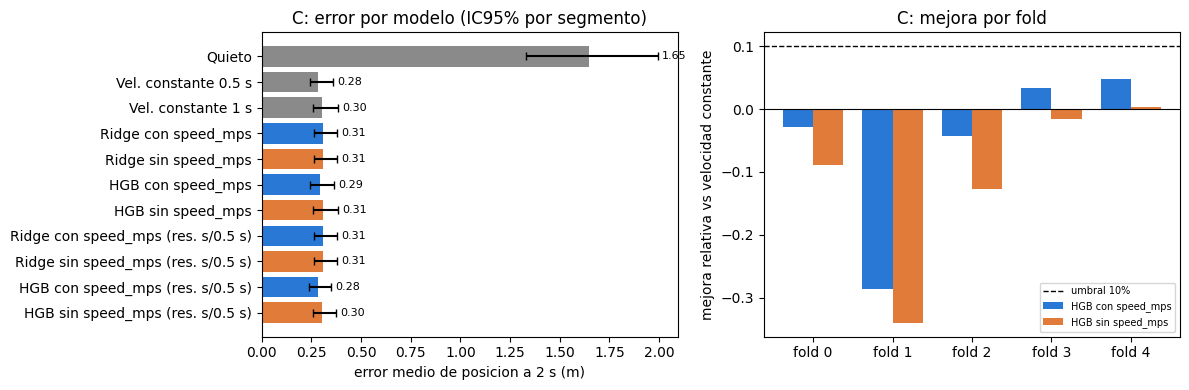

In [27]:
modelos_con = ["Ridge con speed_mps", "HGB con speed_mps"]
mejor_con = min(modelos_con, key=lambda n: err[n].mean())
mejor_sin = mejor_con.replace("con", "sin")
def mejora_y_ic(n):
    rel = 1 - err[n].mean() / err[BASE].mean()
    rel_b = 1 - E_boot[n] / E_boot[BASE]
    return rel, np.percentile(rel_b, [2.5, 97.5])
rel_con, ic_con = mejora_y_ic(mejor_con)
rel_sin, ic_sin = mejora_y_ic(mejor_sin)
folds_mejora_C = int((pf_err[mejor_con] < pf_err[BASE]).sum())
folds_mejora_C_sin = int((pf_err[mejor_sin] < pf_err[BASE]).sum())
print(f"Mejor modelo con speed_mps: {mejor_con} | mejora {rel_con:+.1%} (IC95% {ic_con[0]:+.1%} a {ic_con[1]:+.1%}) | folds donde gana: {folds_mejora_C} de {len(FOLDS)}")
print(f"Mismo modelo sin speed_mps: {mejor_sin} | mejora {rel_sin:+.1%} (IC95% {ic_sin[0]:+.1%} a {ic_sin[1]:+.1%}) | folds donde gana: {folds_mejora_C_sin} de {len(FOLDS)}")
print(f"Quieto vs mejor base: error {err['Quieto'].mean():.3f} m vs {err[BASE].mean():.3f} m")

# Por clase
print("\nError medio (m) por clase:")
print(pd.DataFrame({n: pd.Series(err[n]).groupby(T['object_type'].values).mean() for n in ["Quieto", BASE, mejor_con, mejor_sin]}).round(3).to_string())

RES["C"] = {"base": BASE, "err_base": err[BASE].mean(), "mejor_con": mejor_con, "mejor_sin": mejor_sin, "err_con": err[mejor_con].mean(), "err_sin": err[mejor_sin].mean(),
            "rel_con": rel_con, "ic_con": ic_con, "rel_sin": rel_sin, "ic_sin": ic_sin, "folds_mejora": folds_mejora_C, "folds_mejora_sin": folds_mejora_C_sin,
            "desp_mediano": T["desp"].median(), "cobertura": cobertura_C, "err_quieto": err["Quieto"].mean(), "n": len(T), "segmentos": len(useg)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
orden = list(err)
medias = [err[n].mean() for n in orden]
lo = [np.percentile(E_boot[n], 2.5) for n in orden]; hi = [np.percentile(E_boot[n], 97.5) for n in orden]
col = [GRIS if n in ("Quieto", "Vel. constante 0.5 s", "Vel. constante 1 s") else (AZUL if "con" in n else NARANJA) for n in orden]
axes[0].barh(orden, medias, xerr=[np.array(medias) - lo, np.array(hi) - medias], color=col, capsize=3)
axes[0].invert_yaxis(); axes[0].set_xlabel("error medio de posicion a 2 s (m)"); axes[0].set_title("C: error por modelo (IC95% por segmento)")
for i, m in enumerate(medias):
    axes[0].text(hi[i] + 0.02, i, f"{m:.2f}", va="center", fontsize=8)
w = 0.38
axes[1].bar(np.arange(len(FOLDS)) - w / 2, 1 - pf_err[mejor_con] / pf_err[BASE], width=w, color=AZUL, label=mejor_con)
axes[1].bar(np.arange(len(FOLDS)) + w / 2, 1 - pf_err[mejor_sin] / pf_err[BASE], width=w, color=NARANJA, label=mejor_sin)
axes[1].axhline(0, color="k", lw=0.8); axes[1].axhline(CRITERIOS["C"]["mejora_rel_min"], color="k", ls="--", lw=1, label="umbral 10%")
axes[1].set_xticks(range(len(FOLDS)), [f"fold {k}" for k in FOLDS]); axes[1].set_ylabel("mejora relativa vs velocidad constante")
axes[1].set_title("C: mejora por fold"); axes[1].legend(fontsize=7)
fig.tight_layout()
guardar_fig(fig, "07_C_error_modelos")
plt.show()

### Revisión posterior de C (no altera el veredicto)

Dos pruebas metodológicas pedidas después de ver los resultados. No cambian los criterios ni la especificación que decide el veredicto; las reportamos aparte.

**(a)** Entrenar también con el residuo sobre la **mejor línea base** (ventana de 0,5 s) además del de 1 s.
**(b)** **Curva de aprendizaje**: entrenar con 8, 16 y 24 segmentos y ver si la brecha frente a velocidad constante se cierra con más datos.

In [28]:
print("(a) Residuo sobre la ventana de 0.5 s (revision posterior):")
print(tabla_modelos(list(pred_rev)).round(3).to_string())
con_rev = [n for n in pred_rev if "con speed_mps" in n]
mejor_rev = min(con_rev, key=lambda n: err[n].mean())
sin_rev = mejor_rev.replace("con speed_mps", "sin speed_mps")
rel_r, ic_r = mejora_y_ic(mejor_rev)
rel_rs, ic_rs = mejora_y_ic(sin_rev)
folds_r = int((pf_err[mejor_rev] < pf_err[BASE]).sum())
cr_c = CRITERIOS["C"]
cumple_rev = (rel_r >= cr_c["mejora_rel_min"] and ic_r[0] > cr_c["ic_inferior_min"] and rel_rs >= cr_c["mejora_rel_sin_speed_min"]
              and ic_rs[0] > cr_c["ic_inferior_min"] and folds_r >= cr_c["folds_mejora_min"])
RES["C_rev"] = {"mejor": mejor_rev, "rel": rel_r, "ic": ic_r, "rel_sin": rel_rs, "ic_sin": ic_rs, "folds": folds_r, "cumple": cumple_rev}
print(f"\nMejor con speed_mps: {mejor_rev} | mejora {rel_r:+.1%} (IC95% {ic_r[0]:+.1%} a {ic_r[1]:+.1%}) | folds: {folds_r} de {len(FOLDS)}")
print(f"Sin speed_mps: mejora {rel_rs:+.1%} (IC95% {ic_rs[0]:+.1%} a {ic_rs[1]:+.1%})")

(a) Residuo sobre la ventana de 0.5 s (revision posterior):
                                    error medio (m)  RMSE (m) IC95% error medio  mejora vs base     IC95% mejora
modelo                                                                                                          
Ridge con speed_mps (res. s/0.5 s)            0.309     0.509       0.265-0.379          -0.087  -0.182 a -0.028
Ridge sin speed_mps (res. s/0.5 s)            0.309     0.510       0.265-0.381          -0.089  -0.185 a -0.033
HGB con speed_mps (res. s/0.5 s)              0.281     0.473       0.237-0.351           0.011  -0.082 a +0.073
HGB sin speed_mps (res. s/0.5 s)              0.304     0.501       0.257-0.376          -0.068  -0.181 a +0.006

Mejor con speed_mps: HGB con speed_mps (res. s/0.5 s) | mejora +1.1% (IC95% -8.2% a +7.3%) | folds: 3 de 5
Sin speed_mps: mejora -6.8% (IC95% -18.1% a +0.6%)


                            n efectivo medio  n efectivo minimo  error modelo (m)    min    max  error vel. constante (m)  brecha (m)
segmentos de entrenamiento                                                                                                           
8                                        8.0                  8             0.334  0.322  0.361                     0.284       0.050
16                                      16.0                 16             0.298  0.290  0.309                     0.284       0.014
24                                      21.6                 20             0.291  0.291  0.291                     0.284       0.007


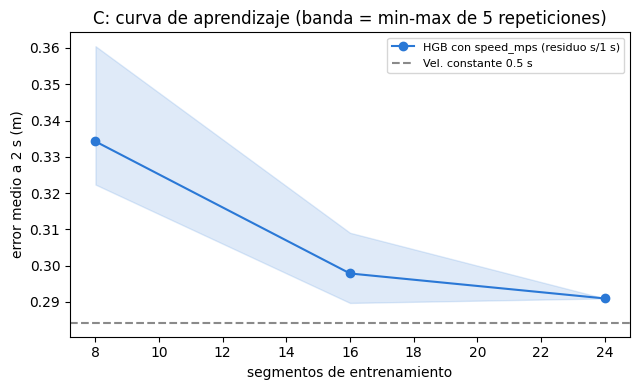

In [29]:
# (b) Curva de aprendizaje: HGB con speed_mps, residuo sobre 1 s. Se entrena con n segmentos de los folds de entrenamiento
# y se evalua en el fold retenido; el n efectivo se topa con los segmentos disponibles en cada fold.
TAMANOS, REPS = [8, 16, 24], 5
Xc, Yc = T[FEAT_C_SPEED].values, T[["rx", "ry"]].values
rng_lc = np.random.default_rng(SEMILLA)
seg_fold = T.groupby("segment_id")["fold"].first()
filas = []
for n_seg in TAMANOS:
    errores_rep, n_efectivos = [], []
    for rep in range(REPS):
        e_tot = np.zeros(len(T))
        for k in FOLDS:
            pool = seg_fold[seg_fold != k].index.values
            n_ef = min(n_seg, len(pool))
            n_efectivos.append(n_ef)
            elegidos = rng_lc.choice(pool, n_ef, replace=False)
            tr = T["segment_id"].isin(elegidos).values
            va = (T["fold"] == k).values
            p = cv10[va] + ajustar_predecir("hgb", Xc[tr], Yc[tr], Xc[va])
            e_tot[va] = np.hypot(*(dreal[va] - p).T)
        errores_rep.append(e_tot.mean())
    filas.append({"segmentos de entrenamiento": n_seg, "n efectivo medio": np.mean(n_efectivos), "n efectivo minimo": min(n_efectivos),
                  "error modelo (m)": np.mean(errores_rep), "min": np.min(errores_rep), "max": np.max(errores_rep)})
curva = pd.DataFrame(filas).set_index("segmentos de entrenamiento")
curva["error vel. constante (m)"] = err[BASE].mean()
curva["brecha (m)"] = curva["error modelo (m)"] - curva["error vel. constante (m)"]
print(curva.round(3).to_string())
RES["C_curva"] = {"brecha_primero": float(curva["brecha (m)"].iloc[0]), "brecha_ultimo": float(curva["brecha (m)"].iloc[-1]), "cierra": bool(curva["brecha (m)"].iloc[-1] <= 0)}

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curva.index, curva["error modelo (m)"], marker="o", color=AZUL, label="HGB con speed_mps (residuo s/1 s)")
ax.fill_between(curva.index, curva["min"], curva["max"], color=AZUL, alpha=0.15)
ax.axhline(err[BASE].mean(), color=GRIS, ls="--", label=f"{BASE}")
ax.set_xlabel("segmentos de entrenamiento"); ax.set_ylabel("error medio a 2 s (m)")
ax.set_title("C: curva de aprendizaje (banda = min-max de 5 repeticiones)"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "07_C_curva_aprendizaje")
plt.show()

In [30]:
c, cr_ = RES["C"], RES["C_rev"]
g, n_ef = curva["brecha (m)"].values, curva["n efectivo medio"].values
objetivo = -CRITERIOS["C"]["mejora_rel_min"] * err[BASE].mean()        # brecha necesaria para mejorar la linea base en el umbral de C
ultima_mejora, falta = g[-2] - g[-1], g[-1] - objetivo
decrece = bool(np.all(np.diff(g) < 0))
parte_b = (f"(b) Con más segmentos, la brecha del modelo frente a velocidad constante pasa de {n2(g[0], 3)} m (con {n_ef[0]:.0f} segmentos) a {n2(g[1], 3)} m (con {n_ef[1]:.0f}) y a {n2(g[2], 3)} m (con {n_ef[2]:.0f} de media). "
           + ("La brecha decrece de forma monótona y termina cerca de cero, lo que sugiere que con más segmentos el modelo alcanzaría paridad con la velocidad constante; "
              if decrece and g[-1] > 0 else "La brecha no decrece de forma monótona; ")
           + f"pero superarla en {pct(CRITERIOS['C']['mejora_rel_min'], 0)} exigiría una brecha de {n2(objetivo, 3)} m, y "
           + (f"los datos no muestran esa tendencia: la última mejora de la curva fue de {n2(ultima_mejora, 3)} m y faltarían {n2(falta, 3)} m."
              if ultima_mejora < falta else "los datos sí van en esa dirección, aunque no la alcanzan con la muestra disponible."))
display(Markdown(
    f"**Conclusión de C (generada).** Sobre {miles(c['n'])} filas de {c['segmentos']} segmentos, el error medio de posición a 2 s es {n2(c['err_quieto'])} m si el objeto se queda quieto, "
    f"{n2(c['err_base'])} m con velocidad constante ({c['base'].replace('Vel. constante', 'ventana de')}) y {n2(c['err_con'])} m con el mejor modelo ({c['mejor_con']}): "
    f"mejora de {pct(c['rel_con'])} (IC 95 % {pct(c['ic_con'][0])} a {pct(c['ic_con'][1])}); sin `speed_mps`, {pct(c['rel_sin'])}. El modelo gana en {c['folds_mejora']} de {len(FOLDS)} folds. "
    f"La velocidad constante ya resuelve casi todo el movimiento a 2 s.\n\n"
    f"**Revisión posterior (no altera el veredicto).** (a) Con el residuo sobre la mejor línea base, el mejor modelo ({cr_['mejor']}) mejora {pct(cr_['rel'])} "
    f"(IC 95 % {pct(cr_['ic'][0])} a {pct(cr_['ic'][1])}); sin `speed_mps`, {pct(cr_['rel_sin'])}. "
    + ("Esta variante **sí cumpliría** los criterios de C." if cr_["cumple"] else "Esta variante **tampoco cumple** los criterios de C, así que la conclusión no cambia.")
    + " " + parte_b))

**Conclusión de C (generada).** Sobre 74.506 filas de 27 segmentos, el error medio de posición a 2 s es 1,65 m si el objeto se queda quieto, 0,28 m con velocidad constante (ventana de 0.5 s) y 0,29 m con el mejor modelo (HGB con speed_mps): mejora de -2,4 % (IC 95 % -11,6 % a 4,0 %); sin `speed_mps`, -8,3 %. El modelo gana en 2 de 5 folds. La velocidad constante ya resuelve casi todo el movimiento a 2 s.

**Revisión posterior (no altera el veredicto).** (a) Con el residuo sobre la mejor línea base, el mejor modelo (HGB con speed_mps (res. s/0.5 s)) mejora 1,1 % (IC 95 % -8,2 % a 7,3 %); sin `speed_mps`, -6,8 %. Esta variante **tampoco cumple** los criterios de C, así que la conclusión no cambia. (b) Con más segmentos, la brecha del modelo frente a velocidad constante pasa de 0,050 m (con 8 segmentos) a 0,014 m (con 16) y a 0,007 m (con 22 de media). La brecha decrece de forma monótona y termina cerca de cero, lo que sugiere que con más segmentos el modelo alcanzaría paridad con la velocidad constante; pero superarla en 10 % exigiría una brecha de -0,028 m, y los datos no muestran esa tendencia: la última mejora de la curva fue de 0,007 m y faltarían 0,035 m.

## 6.2 Candidata E: conflicto con el corredor del auto a 2 s

Definición del notebook 06: el objeto no está en el corredor (0–15 m adelante, |y| < 2 m) ahora y sí lo está 2 s después, medido respecto del auto en ese momento.

In [31]:
n_elegibles = len(T)
n_conf, obj_conf, seg_conf = int(conf.sum()), T.loc[conf, ["segment_id", "obj"]].drop_duplicates().shape[0], T.loc[conf, "segment_id"].nunique()
folds_conf = sorted(int(f) for f in T.loc[conf, "fold"].unique())
print(f"Filas elegibles: {n_elegibles:,} | conflictos nuevos a 2 s: {n_conf} ({n_conf / n_elegibles:.3%}) | objetos distintos: {obj_conf} | segmentos: {seg_conf} | folds con eventos: {folds_conf}")
RES["E"] = {"casos": n_conf, "objetos": obj_conf, "segmentos": seg_conf, "folds": len(folds_conf), "tasa": n_conf / n_elegibles}
display(Markdown(
    f"**Conclusión (generada).** Encontramos {n_conf} casos ({pct(n_conf / n_elegibles, 2)} de las filas elegibles), que corresponden a solo {obj_conf} objetos distintos en {seg_conf} segmentos "
    f"y caen en {len(folds_conf)} de {len(FOLDS)} folds. Con tan pocos objetos independientes no se puede validar un clasificador agrupado por segmento "
    f"(la mayoría de los folds de validación no tendría ningún evento), así que **no hay eventos suficientes para modelar E**."))

Filas elegibles: 74,506 | conflictos nuevos a 2 s: 68 (0.091%) | objetos distintos: 5 | segmentos: 2 | folds con eventos: [1, 4]


**Conclusión (generada).** Encontramos 68 casos (0,09 % de las filas elegibles), que corresponden a solo 5 objetos distintos en 2 segmentos y caen en 2 de 5 folds. Con tan pocos objetos independientes no se puede validar un clasificador agrupado por segmento (la mayoría de los folds de validación no tendría ningún evento), así que **no hay eventos suficientes para modelar E**.

## 6.3 Candidata D: peatón vs ciclista

Clasificación de clase con HistGradientBoosting (pesos de clase balanceados) en los folds de train, comparada con un baseline simple que solo usa `speed_mps` y `volumen_caja`.

In [32]:
from sklearn.metrics import precision_recall_curve

vru_t = train[train["object_type"].isin(VRU)].reset_index(drop=True)
yD = (vru_t["object_type"] == "CYCLIST").astype(int).values
fD = vru_t["fold"].values


def oof_D(cols):
    oof = np.zeros(len(vru_t))
    for k in FOLDS:
        tr, va = fD != k, fD == k
        peso = np.where(yD[tr] == 1, (1 - yD[tr].mean()) / max(yD[tr].mean(), 1e-9), 1.0)
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA)
        m.fit(vru_t.loc[tr, cols], yD[tr], sample_weight=peso)
        oof[va] = m.predict_proba(vru_t.loc[va, cols])[:, 1]
    return oof


oofD_all, oofD_simple = oof_D(FEATURES_NUM), oof_D(["speed_mps", "volumen_caja"])
ciclistas_fold = pd.Series(yD).groupby(fD).sum()
folds_sin_cic = int((ciclistas_fold == 0).sum())
filas = []
for n, s in [("todas las variables", oofD_all), ("solo speed_mps + volumen_caja", oofD_simple)]:
    prec, rec, _ = precision_recall_curve(yD, s)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    filas.append({"modelo": n, "AUC": roc_auc_score(yD, s), "PR-AUC": average_precision_score(yD, s), "mejor F1": f1[:-1].max()})
tablaD = pd.DataFrame(filas).set_index("modelo")
print(f"Ciclistas: {yD.sum():,} ({yD.mean():.2%}) en {vru_t.loc[yD == 1, GRUPO].nunique()} segmentos | ciclistas por fold: {ciclistas_fold.to_dict()} | folds sin ciclistas: {folds_sin_cic}")
print(f"PR-AUC de azar: {yD.mean():.3f}")
print(tablaD.round(3).to_string())
aporte_D = tablaD.loc["todas las variables", "AUC"] - tablaD.loc["solo speed_mps + volumen_caja", "AUC"]
RES["D"] = {"prev": yD.mean(), "ciclistas": int(yD.sum()), "segmentos": int(vru_t.loc[yD == 1, GRUPO].nunique()), "folds_sin": folds_sin_cic,
            "auc": tablaD.iloc[0]["AUC"], "pr": tablaD.iloc[0]["PR-AUC"], "auc_simple": tablaD.iloc[1]["AUC"], "pr_simple": tablaD.iloc[1]["PR-AUC"], "f1": tablaD.iloc[0]["mejor F1"]}
d_ = RES["D"]
display(Markdown(
    f"**Conclusión (generada).** Los ciclistas son {pct(d_['prev'], 2)} de peatones+ciclistas ({miles(d_['ciclistas'])} filas en {d_['segmentos']} segmentos) y {d_['folds_sin']} de {len(FOLDS)} folds no tienen ningún ciclista "
    f"(ciclistas por fold: {ciclistas_fold.to_dict()}). El modelo con todas las variables logra AUC {n2(d_['auc'], 3)} y PR-AUC {n2(d_['pr'], 3)} (azar {n2(d_['prev'], 3)}), "
    f"contra AUC {n2(d_['auc_simple'], 3)} y PR-AUC {n2(d_['pr_simple'], 3)} del baseline de solo velocidad y volumen: el modelo aporta {n2(aporte_D, 3)} de AUC sobre el baseline. "
    f"**Descartamos D por dos motivos**: hay muy pocos ciclistas para validar por segmento, y distinguir peatón de ciclista tiene un valor de negocio débil (no ayuda a decidir qué revisar ni qué anticipar). "
    f"No decimos que sea un problema trivial: el modelo funciona, pero no responde una pregunta que nos importe."))

Ciclistas: 2,105 (2.09%) en 12 segmentos | ciclistas por fold: {0: 522, 1: 482, 2: 0, 3: 827, 4: 274} | folds sin ciclistas: 1
PR-AUC de azar: 0.021
                                 AUC  PR-AUC  mejor F1
modelo                                                
todas las variables            0.988    0.66     0.725
solo speed_mps + volumen_caja  0.703    0.39     0.489


**Conclusión (generada).** Los ciclistas son 2,09 % de peatones+ciclistas (2.105 filas en 12 segmentos) y 1 de 5 folds no tienen ningún ciclista (ciclistas por fold: {0: 522, 1: 482, 2: 0, 3: 827, 4: 274}). El modelo con todas las variables logra AUC 0,988 y PR-AUC 0,660 (azar 0,021), contra AUC 0,703 y PR-AUC 0,390 del baseline de solo velocidad y volumen: el modelo aporta 0,285 de AUC sobre el baseline. **Descartamos D por dos motivos**: hay muy pocos ciclistas para validar por segmento, y distinguir peatón de ciclista tiene un valor de negocio débil (no ayuda a decidir qué revisar ni qué anticipar). No decimos que sea un problema trivial: el modelo funciona, pero no responde una pregunta que nos importe.

## 6.4 Resumen de descartes

In [33]:
a, c, d_, e_ = RES["A"], RES["C"], RES["D"], RES["E"]
descartes = pd.DataFrame([
    ("A: tiene_camara en todos los objetos", "dominado por clase y zona de cámaras",
     f"regla R2 AUC {n2(a['auc_regla'], 3)}; modelo {n2(a['auc_modelo'], 3)} (+{n2(a['delta_auc'], 3)}, techo {n2(a['techo_auc'], 3)}); PR-AUC +{n2(a['delta_prauc'], 3)}; 0 positivos en {miles(len(no_vru))} filas de vehículos y señales"),
    ("C: desplazamiento a 2 s", "la velocidad constante ya lo resuelve; el modelo no la mejora",
     f"error {n2(c['err_base'])} m (velocidad constante) vs {n2(c['err_con'])} m (modelo); mejora {pct(c['rel_con'])}, IC 95 % inferior {pct(c['ic_con'][0])}; gana en {c['folds_mejora']} de {len(FOLDS)} folds"),
    ("D: peatón vs ciclista", "pocos ciclistas y bajo valor de negocio",
     f"{pct(d_['prev'], 2)} ciclistas en {d_['segmentos']} segmentos; folds sin ciclistas: {d_['folds_sin']} de {len(FOLDS)}; AUC {n2(d_['auc'], 3)} vs {n2(d_['auc_simple'], 3)} del baseline simple"),
    ("E: conflicto con el corredor a 2 s", "eventos insuficientes",
     f"{e_['casos']} casos, {e_['objetos']} objetos distintos, {e_['segmentos']} segmentos, {e_['folds']} de {len(FOLDS)} folds"),
], columns=["candidata", "motivo", "evidencia"])
display(Markdown(md_tabla(descartes, indice=False)))

| candidata | motivo | evidencia |
|---|---|---|
| A: tiene_camara en todos los objetos | dominado por clase y zona de cámaras | regla R2 AUC 0,975; modelo 0,992 (+0,018, techo 0,025); PR-AUC +0,163; 0 positivos en 265.377 filas de vehículos y señales |
| C: desplazamiento a 2 s | la velocidad constante ya lo resuelve; el modelo no la mejora | error 0,28 m (velocidad constante) vs 0,29 m (modelo); mejora -2,4 %, IC 95 % inferior -11,6 %; gana en 2 de 5 folds |
| D: peatón vs ciclista | pocos ciclistas y bajo valor de negocio | 2,09 % ciclistas en 12 segmentos; folds sin ciclistas: 1 de 5; AUC 0,988 vs 0,703 del baseline simple |
| E: conflicto con el corredor a 2 s | eventos insuficientes | 68 casos, 5 objetos distintos, 2 segmentos, 2 de 5 folds |

<a id="seccion-7"></a>
# 7. Tabla de decisión y veredicto

**Por qué importa.** Es el único lugar donde los umbrales de la Sección 3 se aplican a los números. No hay juicio manual:
la tabla evalúa cada criterio y el veredicto sale de la regla de desempate escrita de antemano.

## 7.1 Insumo de la tabla: apoyo no supervisado (especificación original)

La tabla incluye tres criterios de apoyo, así que calculamos antes el agrupamiento original (KMeans sobre el comportamiento **previo** de cada peatón/ciclista: rapidez en 1 s, aceleración,
giro y componentes radial y tangencial de la velocidad; variables estandarizadas; k de 2 a 6). La Sección 10 lo discute y lo amplía.

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

ang10 = np.arctan2(T["v10y"], T["v10x"]); ang5 = np.arctan2(T["v5y"], T["v5x"])
giro = np.abs(np.degrees(np.angle(np.exp(1j * (ang5 - ang10)))))
T["giro"] = np.where((T["speed10"] > 0.3) & (T["speed5"] > 0.3), giro, 0.0)
rr = np.hypot(T["box_center_x"], T["box_center_y"]).values
T["v_rad"] = (T["v10x"] * T["box_center_x"] + T["v10y"] * T["box_center_y"]) / rr       # >0 se aleja del auto
T["v_tan"] = (-T["v10x"] * T["box_center_y"] + T["v10y"] * T["box_center_x"]) / rr
FEAT_CL = ["speed10", "acel", "giro", "v_rad", "v_tan"]
Z = T[FEAT_CL].values
Zs = (Z - Z.mean(0)) / Z.std(0)

rng = np.random.default_rng(SEMILLA)
muestra_sil = rng.choice(len(Zs), 10000, replace=False)
sil = {}
for k in range(2, 7):
    lab = KMeans(k, n_init=5, random_state=SEMILLA).fit_predict(Zs)
    sil[k] = silhouette_score(Zs[muestra_sil], lab[muestra_sil])
print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(K, n_init=10, random_state=SEMILLA).fit(Zs)
T["cluster"] = km.labels_
print(f"k elegido (maximo silhouette): {K} | silhouette {sil[K]:.3f}")

# Estabilidad por segmento: se reajusta con segmentos remuestreados y se compara con el agrupamiento de referencia
idx_seg_T = {s: np.where(segs_T == s)[0] for s in useg}
aris = []
for b in range(30):
    ii = np.concatenate([idx_seg_T[s] for s in rng.choice(useg, len(useg), replace=True)])
    ii = rng.choice(ii, min(len(ii), 30000), replace=False)
    m = KMeans(K, n_init=3, random_state=b).fit(Zs[ii])
    aris.append(adjusted_rand_score(km.labels_, m.predict(Zs)))
ari_medio, ari_min = float(np.mean(aris)), float(np.min(aris))
print(f"Estabilidad por segmento (30 remuestreos): ARI medio {ari_medio:.3f} | minimo {ari_min:.3f}")

perfil = T.groupby("cluster").agg(filas=("cluster", "size"), pct_ciclistas=("es_ciclista", lambda s: s.mean() * 100),
                                  **{c: (c, "mean") for c in FEAT_CL}, desp_real_m=("desp", "mean"))
perfil["pct_filas"] = perfil["filas"] / len(T) * 100
print("\nPerfil de cada cluster (medias):")
print(perfil.round(2).to_string())

Silhouette por k: {2: 0.319, 3: 0.32, 4: 0.348, 5: 0.387, 6: 0.394}


k elegido (maximo silhouette): 6 | silhouette 0.394


Estabilidad por segmento (30 remuestreos): ARI medio 0.798 | minimo 0.646

Perfil de cada cluster (medias):
         filas  pct_ciclistas  speed10  acel   giro  v_rad  v_tan  desp_real_m  pct_filas
cluster                                                                                  
0        16481           1.38     1.27 -0.00   1.12   1.14   0.03         2.48      22.12
1        30468           0.87     0.11  0.01   0.19  -0.01   0.01         0.26      40.89
2        11416           1.21     1.41  0.00   1.29  -0.84  -0.81         2.74      15.32
3         1466           1.64     0.75 -0.01  16.29   0.02   0.06         1.35       1.97
4          510          81.18     5.35  0.01   0.26   3.26   2.58        10.76       0.68
5        14165           2.01     1.30 -0.00   1.31  -0.85   0.66         2.49      19.01


Error del modelo C (HGB con speed_mps) por cluster:
   filas  desp_real_m  error_quieto  error_base  error_modelo  error_modelo_sin_speed  mejora_modelo_vs_base  segmentos
0  16481        2.479         2.479       0.300         0.314                   0.337                 -0.046         23
1  30468        0.264         0.264       0.183         0.186                   0.191                 -0.014         25
2  11416        2.736         2.736       0.373         0.400                   0.427                 -0.071         21
3   1466        1.355         1.355       0.785         0.776                   0.818                  0.011         26
4    510       10.756        10.756       0.300         0.402                   0.424                 -0.338          7
5  14165        2.488         2.488       0.359         0.349                   0.372                  0.029         25

Cociente error maximo / minimo entre clusters (modelo): 4.18


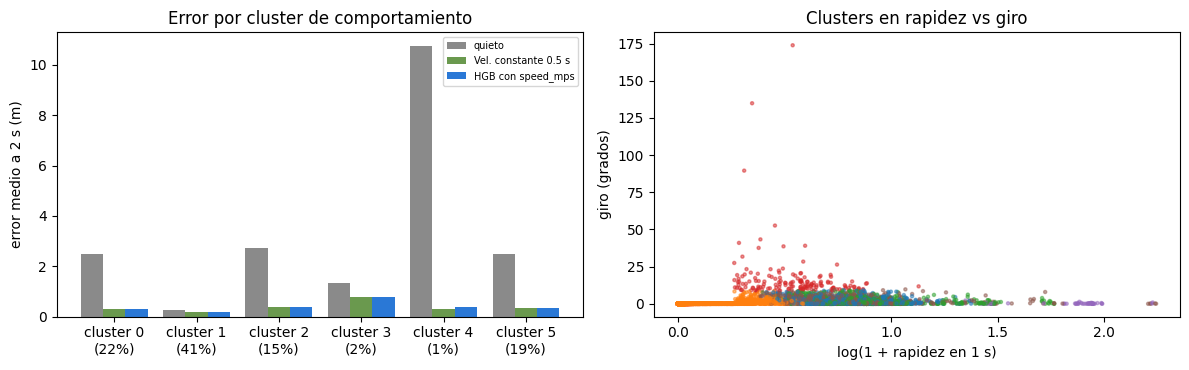

In [35]:
cl = T["cluster"].values
tabla_cl = pd.DataFrame({
    "filas": pd.Series(cl).value_counts().sort_index(),
    "desp_real_m": pd.Series(T["desp"].values).groupby(cl).mean(),
    "error_quieto": pd.Series(err["Quieto"]).groupby(cl).mean(),
    "error_base": pd.Series(err[BASE]).groupby(cl).mean(),
    "error_modelo": pd.Series(err[mejor_con]).groupby(cl).mean(),
    "error_modelo_sin_speed": pd.Series(err[mejor_sin]).groupby(cl).mean(),
})
tabla_cl["mejora_modelo_vs_base"] = 1 - tabla_cl["error_modelo"] / tabla_cl["error_base"]
tabla_cl["segmentos"] = [len(set(segs_T[cl == c])) for c in tabla_cl.index]
print(f"Error del modelo C ({mejor_con}) por cluster:")
print(tabla_cl.round(3).to_string())
razon_err = tabla_cl["error_modelo"].max() / tabla_cl["error_modelo"].min()
print(f"\nCociente error maximo / minimo entre clusters (modelo): {razon_err:.2f}")
RES["cluster"] = {"k": K, "silhouette": sil[K], "ari_medio": ari_medio, "razon_error": razon_err}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(K)
axes[0].bar(x - 0.27, tabla_cl["error_quieto"], 0.27, color=GRIS, label="quieto")
axes[0].bar(x, tabla_cl["error_base"], 0.27, color=VERDE, label=BASE)
axes[0].bar(x + 0.27, tabla_cl["error_modelo"], 0.27, color=AZUL, label=mejor_con)
axes[0].set_xticks(x, [f"cluster {c}\n({tabla_cl.loc[c, 'filas'] / len(T):.0%})" for c in tabla_cl.index])
axes[0].set_ylabel("error medio a 2 s (m)"); axes[0].set_title("Error por cluster de comportamiento"); axes[0].legend(fontsize=7)
mm = T.sample(8000, random_state=SEMILLA)
sc = axes[1].scatter(np.log1p(mm["speed10"]), mm["giro"], c=mm["cluster"], cmap="tab10", s=5, alpha=0.5, vmin=0, vmax=9)
axes[1].set_xlabel("log(1 + rapidez en 1 s)"); axes[1].set_ylabel("giro (grados)"); axes[1].set_title("Clusters en rapidez vs giro")
fig.tight_layout()
guardar_fig(fig, "07_clusters_comportamiento")
plt.show()

## 7.2 Tabla de decisión

In [36]:
cr = CRITERIOS
filas = []
def fila(t, criterio, umbral, valor, cumple, cuenta=True):
    filas.append({"target": t, "criterio": criterio, "umbral": umbral, "valor": valor, "cumple": bool(cumple), "decide": cuenta})

a, b, c = RES["A"], RES["B"], RES["C"]
fila("A", "AUC modelo - mejor regla", f">= {cr['A']['delta_auc_min']}", f"{a['delta_auc']:+.3f}", a["delta_auc"] >= cr["A"]["delta_auc_min"])
fila("A", "PR-AUC modelo - mejor regla", f">= {cr['A']['delta_prauc_min']}", f"{a['delta_prauc']:+.3f}", a["delta_prauc"] >= cr["A"]["delta_prauc_min"])
fila("A", "folds donde el modelo gana", f">= {cr['A']['folds_mejora_min']}", f"{a['folds_mejora']}", a["folds_mejora"] >= cr["A"]["folds_mejora_min"])

fila("B", "AUC (todas las variables)", f">= {cr['B']['auc_min']}", f"{b['auc']:.3f}", b["auc"] >= cr["B"]["auc_min"])
fila("B", "AUC minimo por fold", f">= {cr['B']['auc_fold_min']}", f"{b['auc_min_fold']:.3f}", b["auc_min_fold"] >= cr["B"]["auc_fold_min"])
fila("B", "PR-AUC - prevalencia", f">= {cr['B']['delta_prauc_min']}", f"{b['delta_prauc']:+.3f}", b["delta_prauc"] >= cr["B"]["delta_prauc_min"])
fila("B", "brecha AUC Day vs Night", f"<= {cr['B']['brecha_dia_noche_max']}", f"{b['brecha_dn']:.3f}", b["brecha_dn"] <= cr["B"]["brecha_dia_noche_max"])
fila("B", "brecha AUC entre ubicaciones", f"<= {cr['B']['brecha_ubicacion_max']}", f"{b['brecha_loc']:.3f}", b["brecha_loc"] <= cr["B"]["brecha_ubicacion_max"])
lo_p, hi_p = cr["B"]["prevalencia_rango"]
fila("B", "prevalencia de sin_camara", f"{lo_p}-{hi_p}", f"{b['prevalencia']:.3f}", lo_p <= b["prevalencia"] <= hi_p)
fila("B", "aporte no geometrico (info)", f">= {cr['B']['aporte_no_geometrico_info']}", f"{b['aporte_nogeo']:+.3f}", b["aporte_nogeo"] >= cr["B"]["aporte_no_geometrico_info"], cuenta=False)

fila("C", "mejora vs mejor vel. constante (con speed)", f">= {cr['C']['mejora_rel_min']:.0%}", f"{c['rel_con']:+.1%}", c["rel_con"] >= cr["C"]["mejora_rel_min"])
fila("C", "IC95% inferior de esa mejora", f"> {cr['C']['ic_inferior_min']}", f"{c['ic_con'][0]:+.1%}", c["ic_con"][0] > cr["C"]["ic_inferior_min"])
fila("C", "mejora sin speed_mps", f">= {cr['C']['mejora_rel_sin_speed_min']:.0%}", f"{c['rel_sin']:+.1%}", c["rel_sin"] >= cr["C"]["mejora_rel_sin_speed_min"])
fila("C", "IC95% inferior sin speed_mps", f"> {cr['C']['ic_inferior_min']}", f"{c['ic_sin'][0]:+.1%}", c["ic_sin"][0] > cr["C"]["ic_inferior_min"])
fila("C", "folds donde el modelo gana", f">= {cr['C']['folds_mejora_min']}", f"{c['folds_mejora']}", c["folds_mejora"] >= cr["C"]["folds_mejora_min"])
fila("C", "desplazamiento mediano a 2 s (m)", f">= {cr['C']['desplazamiento_mediano_min_m']}", f"{c['desp_mediano']:.2f}", c["desp_mediano"] >= cr["C"]["desplazamiento_mediano_min_m"])
fila("C", "cobertura de filas utilizables", f">= {cr['C']['cobertura_min']:.0%}", f"{c['cobertura']:.1%}", c["cobertura"] >= cr["C"]["cobertura_min"])

fila("B", "brecha AUC Dawn/Dusk vs Day (informativa)", "sin umbral previo", f"{b['brecha_dawn_day']:.3f}", b["brecha_dawn_day"] <= cr["B"]["brecha_dia_noche_max"], cuenta=False)

k = RES["cluster"]
fila("apoyo", "silhouette KMeans", f">= {cr['apoyo']['silhouette_min']}", f"{k['silhouette']:.3f}", k["silhouette"] >= cr["apoyo"]["silhouette_min"], cuenta=False)
fila("apoyo", "estabilidad por segmento (ARI)", f">= {cr['apoyo']['ari_min']}", f"{k['ari_medio']:.3f}", k["ari_medio"] >= cr["apoyo"]["ari_min"], cuenta=False)
fila("apoyo", "cociente de error entre clusters", f">= {cr['apoyo']['razon_error_clusters_min']}", f"{k['razon_error']:.2f}", k["razon_error"] >= cr["apoyo"]["razon_error_clusters_min"], cuenta=False)

decision = pd.DataFrame(filas)
decision["resultado"] = np.where(decision["cumple"], "CUMPLE", "no cumple"); decision.loc[decision["umbral"] == "sin umbral previo", "resultado"] = "informativa"
print(decision[["target", "criterio", "umbral", "valor", "resultado", "decide"]].to_string(index=False))

pasa = {t: bool(decision[(decision["target"] == t) & decision["decide"]]["cumple"].all()) for t in ["A", "B", "C"]}
elegido = next((t for t in cr["desempate"] if pasa[t]), None)
print("\nTargets que cumplen todos los criterios:", {t: ("SI" if v else "NO") for t, v in pasa.items()})
if elegido is None:
    veredicto = "Ningun candidato cumple todos los criterios: se mantiene A (tiene_camara), declarando que es en gran parte la clase del objeto."
    elegido = "A"
else:
    veredicto = f"Target elegido para EP2: {elegido}."
print("VEREDICTO:", veredicto)
decision.drop(columns="resultado").to_csv(RUTA_REPORTING / "decision_target_ep2.csv", index=False)

target                                   criterio            umbral  valor   resultado  decide
     A                   AUC modelo - mejor regla           >= 0.05 +0.018   no cumple    True
     A                PR-AUC modelo - mejor regla           >= 0.05 +0.163      CUMPLE    True
     A                 folds donde el modelo gana              >= 4      5      CUMPLE    True
     B                  AUC (todas las variables)            >= 0.7  0.854      CUMPLE    True
     B                        AUC minimo por fold            >= 0.6  0.824      CUMPLE    True
     B                       PR-AUC - prevalencia            >= 0.1 +0.516      CUMPLE    True
     B                    brecha AUC Day vs Night            <= 0.1  0.000      CUMPLE    True
     B               brecha AUC entre ubicaciones            <= 0.1  0.061      CUMPLE    True
     B                  prevalencia de sin_camara          0.05-0.5  0.232      CUMPLE    True
     B                aporte no geometrico (info) 

In [37]:
c_, cr_ = RES["C"], RES["C_rev"]
display(Markdown(
    f"**Veredicto (generado).** {veredicto} Cumplen todos los criterios: " + ", ".join(f"{t}: {'sí' if v else 'no'}" for t, v in pasa.items()) + ". "
    f"La revisión posterior de C ({cr_['mejor']}) " + ("**cambiaría** el resultado de C" if cr_["cumple"] else "**no cambia** el resultado de C") + f" (mejora {pct(cr_['rel'])}, IC 95 % inferior {pct(cr_['ic'][0])})."))

**Veredicto (generado).** Target elegido para EP2: B. Cumplen todos los criterios: A: no, B: sí, C: no. La revisión posterior de C (HGB con speed_mps (res. s/0.5 s)) **no cambia** el resultado de C (mejora 1,1 %, IC 95 % inferior -8,2 %).

## 7.3 Cálculo previo para las Secciones 8 y 9

La Sección 8 cita cifras del valor práctico de B, así que los cálculos de la Sección 9 (estabilidad por objeto, curvas de captura y bootstrap)
se hacen en esta celda y la Sección 9 los muestra. No se evalúa nada nuevo sobre el test.

In [38]:
from sklearn.linear_model import LogisticRegression

# ---- Estabilidad por objeto: fraccion de frames sin camara de cada (segmento, objeto)
bz["sin"] = yB
obj = bz.groupby([GRUPO, "key.laser_object_id"]).agg(frames=("sin", "size"), sin=("sin", "sum"))
obj["frac_sin"] = obj["sin"] / obj["frames"]
obj["tipo"] = np.select([obj["frac_sin"] == 0, obj["frac_sin"] == 1], ["siempre con camara", "siempre sin camara"], "mixto")
estab_todos = obj["tipo"].value_counts()
estab_10 = obj.loc[obj["frames"] >= 10, "tipo"].value_counts()
share_const = (estab_todos.get("siempre con camara", 0) + estab_todos.get("siempre sin camara", 0)) / len(obj)
UNIDAD = "objeto" if share_const >= 0.5 else "frame"      # regla: unidad de revision = objeto si la mayoria de los objetos es constante
print(f"Objetos: {len(obj):,} | frames por objeto, mediana {obj['frames'].median():.0f}")
print("Todos los objetos:", estab_todos.to_dict())
print("Objetos con >= 10 frames:", estab_10.to_dict())
print(f"Fraccion de objetos con estado constante: {share_const:.1%} -> unidad de revision sugerida: {UNIDAD}")

METODOS = {"HGB": scoreB["todas las variables"], "Regresion logistica": s_lr, "Regla: menos puntos LiDAR primero": -bz["num_lidar_points"].values.astype(float)}
print("AUC fuera de fold:", {n: round(roc_auc_score(yB, s), 3) for n, s in METODOS.items()})

# ---- Curvas de captura. Nivel frame: cada frame es una unidad. Nivel objeto: la unidad es el objeto (se ordena por la
# probabilidad media de sus frames) y se "captura" el numero de frames sin camara que tiene (revisar un objeto cubre todos sus frames).
codes = bz.groupby([GRUPO, "key.laser_object_id"]).ngroup().values
n_obj = codes.max() + 1
n_fr_obj = np.bincount(codes)
w_obj = np.bincount(codes, weights=yB)
seg_obj = pd.Series(bz[GRUPO].values).groupby(codes).first().values
S_OBJ = {n: np.bincount(codes, weights=s) / n_fr_obj for n, s in METODOS.items()}
rng_g = np.random.default_rng(SEMILLA)
tb_f, tb_o = rng_g.random(len(bz)), rng_g.random(n_obj)


def curva_cap(peso, score, tb):
    o = np.lexsort((tb, -score))
    return np.cumsum(peso[o]) / peso.sum()


def metr(cum):
    n = len(cum)
    en = lambda f: cum[max(int(np.ceil(f * n)) - 1, 0)]
    return {"Captura@10%": en(0.1), "Captura@20%": en(0.2), "Captura@30%": en(0.3), "Lift@20%": en(0.2) / 0.2, "Fraccion para 80%": (np.searchsorted(cum, 0.8) + 1) / n}


NIVELES = {"frame": (yB.astype(float), METODOS, tb_f), "objeto": (w_obj, S_OBJ, tb_o)}
CURVAS = {nv: {**{n: curva_cap(p, s, tb) for n, s in ms.items()}, "Orden ideal": curva_cap(p, p.astype(float), tb)} for nv, (p, ms, tb) in NIVELES.items()}
punto = {nv: {n: metr(c) for n, c in cs.items()} for nv, cs in CURVAS.items()}

# ---- IC 95% por bootstrap de segmentos
idx_f = {s: np.where(bz[GRUPO].values == s)[0] for s in segs_b}
idx_o = {s: np.where(seg_obj == s)[0] for s in segs_b}
boot_m = {nv: {n: [] for n in METODOS} for nv in NIVELES}
for _ in range(300):
    ss = rng_g.choice(segs_b, len(segs_b), replace=True)
    for nv, (p, ms, tb) in NIVELES.items():
        ii = np.concatenate([(idx_f if nv == "frame" else idx_o)[s] for s in ss])
        if p[ii].sum() == 0:
            continue
        for n, sc in ms.items():
            boot_m[nv][n].append(metr(curva_cap(p[ii], sc[ii], tb[ii])))
GAN = {}
for nv in NIVELES:
    filas = []
    for n in METODOS:
        for met, v in punto[nv][n].items():
            vals = [r[met] for r in boot_m[nv][n]]
            filas.append({"nivel": nv, "metodo": n, "metrica": met, "valor": v, "ic_lo": np.percentile(vals, 2.5), "ic_hi": np.percentile(vals, 97.5)})
    GAN[nv] = pd.DataFrame(filas)
REGLA = "Regla: menos puntos LiDAR primero"
DIF = {}
for nv in NIVELES:
    for met in ["Captura@20%", "Fraccion para 80%"]:
        d = np.array([a[met] - b_[met] for a, b_ in zip(boot_m[nv]["HGB"], boot_m[nv][REGLA])])
        DIF[(nv, met)] = (punto[nv]["HGB"][met] - punto[nv][REGLA][met], *np.percentile(d, [2.5, 97.5]))
print("Diferencia HGB - regla simple (valor, IC95% pareado por segmentos):", {k: tuple(round(float(x), 3) for x in v) for k, v in DIF.items()})
print("Calculo previo listo (curvas de captura y bootstrap).")

Objetos: 705 | frames por objeto, mediana 87
Todos los objetos: {'mixto': 585, 'siempre con camara': 73, 'siempre sin camara': 47}
Objetos con >= 10 frames: {'mixto': 578, 'siempre con camara': 71, 'siempre sin camara': 33}
Fraccion de objetos con estado constante: 17.0% -> unidad de revision sugerida: frame
AUC fuera de fold: {'HGB': 0.854, 'Regresion logistica': 0.838, 'Regla: menos puntos LiDAR primero': 0.797}


Diferencia HGB - regla simple (valor, IC95% pareado por segmentos): {('frame', 'Captura@20%'): (0.035, 0.002, 0.074), ('frame', 'Fraccion para 80%'): (-0.114, -0.19, -0.061), ('objeto', 'Captura@20%'): (-0.003, -0.09, 0.068), ('objeto', 'Fraccion para 80%'): (0.0, -0.046, 0.049)}
Calculo previo listo (curvas de captura y bootstrap).


<a id="seccion-8"></a>
# 8. Qué problema de negocio resuelve el target elegido

*Esta sección se puede leer sola. Las cifras las genera el código a partir de los resultados de las secciones 4 a 9.*

## 8.1 El problema

Los modelos de percepción de un vehículo autónomo se entrenan con datos etiquetados en LiDAR (cajas 3D) y en cámara (cajas 2D). Peatones y ciclistas son los
usuarios más vulnerables de la vía. En Waymo Open Dataset v2 los `lidar_box` son **cajas 3D etiquetadas** (anotadas), no la salida de un detector; según nuestra lectura
de la documentación, la asociación cámara-LiDAR enlaza cada caja 3D con su par 2D de cámara cuando existe (la [página oficial del dataset](https://waymo.com/open/about/)
describe etiquetas 3D para LiDAR y etiquetas 2D para cámara). **El problema es auditar qué cajas 3D etiquetadas no tienen su par 2D de cámara.**

Contexto externo: la NHTSA reportó
[7.314 peatones fallecidos en EE. UU. en 2023, el 18 % de las muertes de tránsito](https://crashstats.nhtsa.dot.gov/Api/Public/ViewPublication/813727)
(cifra del primer informe; el [archivo final de 2023 la revisó a 7.367](https://crashstats.nhtsa.dot.gov/Api/Public/ViewPublication/813818)).
Es contexto de por qué importan estos usuarios; **no** decimos que nuestro modelo evite accidentes.

In [39]:
b = RES["B"]
n_b, n_sin_b = len(bz), int(yB.sum())
display(Markdown(
    f"En nuestra muestra, de las {miles(n_b)} cajas 3D etiquetadas de peatones y ciclistas dentro de la zona de cámaras (train), "
    f"**{pct(b['prevalencia'])} ({miles(n_sin_b)}) no tiene su par 2D de cámara**, y hoy no se sabe cuáles son hasta revisarlas una por una."))

En nuestra muestra, de las 68.555 cajas 3D etiquetadas de peatones y ciclistas dentro de la zona de cámaras (train), **23,2 % (15.884) no tiene su par 2D de cámara**, y hoy no se sabe cuáles son hasta revisarlas una por una.

## 8.2 Quién tiene el problema y cómo lo resuelve hoy

Lo tienen los equipos que preparan y auditan datos de percepción: etiquetado, control de calidad y fusión de sensores. Hoy lo resuelven con
**revisión manual amplia o muestreo aleatorio**, con un costo que crece en proporción al volumen de cajas etiquetadas.

## 8.3 La solución

Un modelo supervisado que, usando **solo atributos de la caja 3D etiquetada** (posición, tamaño, número de puntos LiDAR, velocidad y orientación), estima la probabilidad de que una
caja **no** tenga su par 2D de cámara y entrega una **lista ordenada** para revisar primero las más sospechosas.

**Sobre `speed_mps`.** Esta variable proviene de la etiqueta (`lidar_box`), no de un sensor en tiempo real. Su ablación casi no mueve el AUC (sin ella el AUC cambia -0.004, de 0,854 a 0,850), así que el resultado no depende de ella.

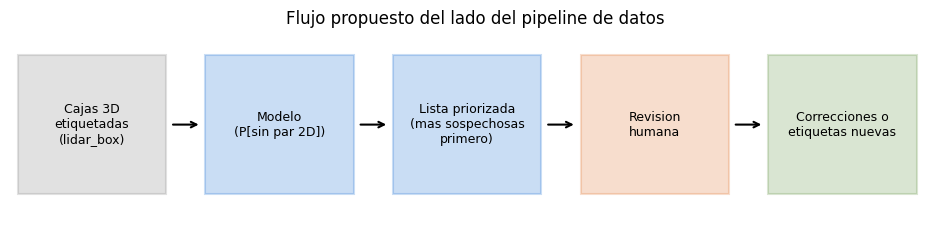

In [40]:
abl_vel = abl_B.loc["sin velocidad (speed_mps)", "cambio"]
display(Markdown(
    f"**Sobre `speed_mps`.** Esta variable proviene de la etiqueta (`lidar_box`), no de un sensor en tiempo real. Su ablación " +
    ("casi no mueve el AUC" if abs(abl_vel) < 0.01 else "mueve el AUC") + f" (sin ella el AUC cambia {abl_vel:+.3f}, de {n2(RES['B']['auc'], 3)} a {n2(abl_B.loc['sin velocidad (speed_mps)', 'AUC'], 3)}), "
    f"así que el resultado no depende de ella."))
fig, ax = plt.subplots(figsize=(12, 2.4))
ax.axis("off")
pasos = ["Cajas 3D\netiquetadas\n(lidar_box)", "Modelo\n(P[sin par 2D])", "Lista priorizada\n(mas sospechosas\nprimero)", "Revision\nhumana", "Correcciones o\netiquetas nuevas"]
colores = [GRIS, AZUL, AZUL, NARANJA, VERDE]
for i, (t, c) in enumerate(zip(pasos, colores)):
    x = i * 2.4
    ax.add_patch(plt.Rectangle((x, 0.2), 1.9, 1.2, facecolor=c, alpha=0.25, edgecolor=c, lw=1.5))
    ax.text(x + 0.95, 0.8, t, ha="center", va="center", fontsize=9)
    if i < len(pasos) - 1:
        ax.annotate("", xy=(x + 2.35, 0.8), xytext=(x + 1.95, 0.8), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-0.1, 11.8); ax.set_ylim(0, 1.6)
ax.set_title("Flujo propuesto del lado del pipeline de datos")
guardar_fig(fig, "07_flujo_revision")
plt.show()

## 8.4 El valor, con cifras

**Reducción del esfuerzo de revisión.** Si en vez de revisar al azar se revisa en el orden del modelo, ¿cuántas cajas sin par 2D se encuentran con el mismo esfuerzo? Usamos las curvas de
captura fuera de fold de la Sección 9. La unidad es el **frame** (una caja 3D etiquetada en un frame concreto). Mostramos juntas dos lecturas: qué se captura en el tope de la lista (**Captura@20 %**) y
cuánto hay que revisar para cubrir casi todo (**Fracción para 80 %**).

In [41]:
def fila_g(nv, metodo, met):
    r = GAN[nv][(GAN[nv]["metodo"] == metodo) & (GAN[nv]["metrica"] == met)].iloc[0]
    return r["valor"], r["ic_lo"], r["ic_hi"]

filas = []
for nombre in ["HGB", "Regresion logistica", "Regla: menos puntos LiDAR primero"]:
    c20, c20l, c20h = fila_g("frame", nombre, "Captura@20%")
    f80, f80l, f80h = fila_g("frame", nombre, "Fraccion para 80%")
    filas.append({"metodo": nombre, "Captura@20 % (IC 95 %)": f"{pct(c20)} ({pct(c20l)} a {pct(c20h)})", "Fraccion para 80 % (IC 95 %)": f"{pct(f80)} ({pct(f80l)} a {pct(f80h)})"})
filas.append({"metodo": "Azar", "Captura@20 % (IC 95 %)": pct(0.2), "Fraccion para 80 % (IC 95 %)": pct(0.8)})
display(Markdown(md_tabla(pd.DataFrame(filas), indice=False)))

hf, hf_l, hf_h = fila_g("frame", "HGB", "Fraccion para 80%")
rf, _, _ = fila_g("frame", REGLA, "Fraccion para 80%")
cf, _, _ = fila_g("frame", "HGB", "Captura@20%")
rc, _, _ = fila_g("frame", REGLA, "Captura@20%")
lf, _, _ = fila_g("frame", "HGB", "Lift@20%")
d80, d80l, d80h = DIF[("frame", "Fraccion para 80%")]
d20, d20l, d20h = DIF[("frame", "Captura@20%")]
co, _, _ = fila_g("objeto", "HGB", "Captura@20%")
ho, _, _ = fila_g("objeto", "HGB", "Fraccion para 80%")
RES["valor"] = {"cap20_f": cf, "cap20_o": co, "lift20_f": lf, "frac80_f": hf, "frac80_o": ho, "cap20_regla_f": rc, "frac80_regla_f": rf,
                "d80": d80, "d80_ic": (d80l, d80h), "d20": d20, "d20_ic": (d20l, d20h)}
display(Markdown(
    f"**Resultado más fuerte (generado).** Para encontrar el 80 % de las lagunas, el HGB necesita revisar el {pct(hf)} de los frames, la regla simple de \"menos puntos LiDAR primero\" el {pct(rf)} "
    f"y el azar el 80,0 % (diferencia HGB menos regla: {d80 * 100:+.1f} puntos, IC 95 % {d80l * 100:+.1f} a {d80h * 100:+.1f}). "
    f"**En el tope de la lista** (Captura@20 %) la ventaja sobre la regla es " + ("pequeña" if abs(d20) < 0.05 else "apreciable") +
    f" ({d20 * 100:+.1f} puntos, IC 95 % {d20l * 100:+.1f} a {d20h * 100:+.1f}): el HGB captura el {pct(cf)} (lift {n2(lf)}x) y la regla el {pct(rc)}. "
    f"El modelo aporta más en alta cobertura que en el tope de la lista."))

| metodo | Captura@20 % (IC 95 %) | Fraccion para 80 % (IC 95 %) |
|---|---|---|
| HGB | 61,3 % (53,2 % a 69,3 %) | 39,1 % (29,2 % a 50,9 %) |
| Regresion logistica | 58,5 % (48,5 % a 68,4 %) | 41,1 % (29,2 % a 53,8 %) |
| Regla: menos puntos LiDAR primero | 57,9 % (50,1 % a 65,3 %) | 50,5 % (43,2 % a 61,3 %) |
| Azar | 20,0 % | 80,0 % |

**Resultado más fuerte (generado).** Para encontrar el 80 % de las lagunas, el HGB necesita revisar el 39,1 % de los frames, la regla simple de "menos puntos LiDAR primero" el 50,5 % y el azar el 80,0 % (diferencia HGB menos regla: -11.4 puntos, IC 95 % -19.0 a -6.1). **En el tope de la lista** (Captura@20 %) la ventaja sobre la regla es pequeña (+3.5 puntos, IC 95 % +0.2 a +7.4): el HGB captura el 61,3 % (lift 3,07x) y la regla el 57,9 %. El modelo aporta más en alta cobertura que en el tope de la lista.

In [42]:
RUTA_C09 = RUTA_REPORTING / "09_resumen_cifras.json"
if RUTA_C09.exists():
    C09 = json.loads(RUTA_C09.read_text(encoding="utf-8"))
    hp, hg = C09["dif_f80_120_vs_regla_puntos"]["HGB"], C09["dif_f80_120_vs_regla_geometrica"]["HGB"]
    bp = C09["mejor_baseline_principal"]
    pb = C09["principal"][bp]
    sost = "se mantiene" if hg[2] < 0 else "no se sostiene"
    ACT_TXT = (f"**Actualización posterior al 08 y 09 (las cifras de arriba son de la versión previa, población de {ZONA_CAMARAS_DEG}°).** La población principal pasó de {ZONA_CAMARAS_DEG}° a |azimut| ≤ {AZ_MAX}° porque en {AZ_MAX}–{ZONA_CAMARAS_DEG}° "
               f"la ausencia de par 2D es en buena parte geométrica (08). En la población principal ({miles(C09['filas_principal'])} filas) el mejor baseline simple es {bp} (AUC {n2(pb['AUC'], 3)}, Fracción para 80 % {pct(pb['Fraccion para 80%'])}) "
               f"y la recomendación del 09 es **{C09['recomendacion']}**. En la población de {ZONA_CAMARAS_DEG}°, con los modelos reentrenados en el 09, el HGB menos la regla de puntos da {hp[0] * 100:+.1f} puntos en Fracción para 80 % (IC {hp[1] * 100:+.1f} a {hp[2] * 100:+.1f}) "
               f"y menos la regla geométrica {hg[0] * 100:+.1f} puntos (IC {hg[1] * 100:+.1f} a {hg[2] * 100:+.1f}): la ventaja de {RES['valor']['d80'] * 100:+.1f} puntos frente a la regla de puntos de la versión previa **{sost}** al compararla con un baseline geométrico.")
    ACT_CORTO = (f"**Actualización:** la población principal pasa a |azimut| ≤ {AZ_MAX}° y, frente a la regla geométrica, la diferencia del HGB en la población de {ZONA_CAMARAS_DEG}° es {hg[0] * 100:+.1f} puntos en Fracción para 80 % (IC {hg[1] * 100:+.1f} a {hg[2] * 100:+.1f}); "
                 f"la ventaja de la versión previa {sost}. Recomendación del 09: {C09['recomendacion']}.")
else:
    ACT_TXT = ACT_CORTO = "**Actualización posterior al 08 y 09:** las cifras del 09 no estaban disponibles al ejecutar este notebook."
display(Markdown(ACT_TXT))

**Actualización posterior al 08 y 09 (las cifras de arriba son de la versión previa, población de 120°).** La población principal pasó de 120° a |azimut| ≤ 100° porque en 100–120° la ausencia de par 2D es en buena parte geométrica (08). En la población principal (64.509 filas) el mejor baseline simple es Regla: menos puntos top (AUC 0,862, Fracción para 80 % 37,8 %) y la recomendación del 09 es **Regla: menos puntos top**. En la población de 120°, con los modelos reentrenados en el 09, el HGB menos la regla de puntos da -9.0 puntos en Fracción para 80 % (IC -20.0 a -2.0) y menos la regla geométrica +4.8 puntos (IC -1.3 a +9.1): la ventaja de -11.4 puntos frente a la regla de puntos de la versión previa **no se sostiene** al compararla con un baseline geométrico.

**Nivel de objeto.** Si la unidad fuera el objeto (revisar un objeto cubre todos sus frames), el resultado es otro:

In [43]:
ideal_o = metr(CURVAS["objeto"]["Orden ideal"])
lift_o, rule_o = fila_g("objeto", "HGB", "Lift@20%")[0], fila_g("objeto", REGLA, "Captura@20%")[0]
share_mixto = estab_todos.get("mixto", 0) / len(obj)
RES["objeto"] = {"cap20": co, "cap20_ideal": ideal_o["Captura@20%"], "lift": lift_o, "lift_ideal": ideal_o["Lift@20%"], "share_mixto": share_mixto}
display(Markdown(
    f"**A nivel de objeto el modelo casi no prioriza**: el HGB captura el {pct(co)} de los frames sin par 2D con el 20 % de los objetos (lift {n2(lift_o)}x), frente al {pct(ideal_o['Captura@20%'])} del orden ideal "
    f"(lift {n2(ideal_o['Lift@20%'])}x) y el {pct(rule_o)} de la regla simple. La razón es que el {pct(share_mixto)} de los objetos es mixto (tiene frames con y sin par 2D): "
    f"el modelo distingue **en qué frames falta la cámara**, no **qué objetos la pierden**. Elegimos el frame como unidad por un razonamiento, no por un dato: el etiquetado 2D se hace por imagen, "
    f"así que la falta de par aparece frame a frame."))

**A nivel de objeto el modelo casi no prioriza**: el HGB captura el 28,5 % de los frames sin par 2D con el 20 % de los objetos (lift 1,43x), frente al 62,4 % del orden ideal (lift 3,12x) y el 28,8 % de la regla simple. La razón es que el 83,0 % de los objetos es mixto (tiene frames con y sin par 2D): el modelo distingue **en qué frames falta la cámara**, no **qué objetos la pierden**. Elegimos el frame como unidad por un razonamiento, no por un dato: el etiquetado 2D se hace por imagen, así que la falta de par aparece frame a frame.

**Valor secundario.** (1) *Control de calidad:* una caja que el modelo espera con par 2D y que no lo tiene es candidata a etiqueta faltante o a asociación errónea.
(2) *Perfiles de riesgo por cluster* de comportamiento (Sección 10): permiten ver en qué tipo de peatón/ciclista se concentran las lagunas.

**Traducción a tiempo y costo.** Los parámetros siguientes son **supuestos editables, no datos**: no tenemos una medición propia del tiempo de revisión ni citamos una fuente de costo de etiquetado.

In [44]:
# SUPUESTOS EDITABLES (no son datos medidos)
SEGUNDOS_POR_REVISION = 20          # supuesto: segundos para revisar un frame (caja 3D etiquetada) o un objeto
N_UNIDADES = n_b if UNIDAD == "frame" else int(n_obj)     # por defecto, las de B en train; editar para otro volumen

fr_modelo, fr_regla = (hf, rf) if UNIDAD == "frame" else (ho, fila_g("objeto", REGLA, "Fraccion para 80%")[0])
h_total = N_UNIDADES * SEGUNDOS_POR_REVISION / 3600
h_modelo, h_regla, h_azar = h_total * fr_modelo, h_total * fr_regla, h_total * 0.8
print(f"Supuesto: {SEGUNDOS_POR_REVISION} s por revision; unidad = {UNIDAD}; {N_UNIDADES:,} unidades.")
print(f"Revisar todo: {h_total:,.0f} h | para encontrar el 80% de las lagunas: modelo {h_modelo:,.0f} h, regla simple {h_regla:,.0f} h, azar {h_azar:,.0f} h")
RES["horas"] = {"seg": SEGUNDOS_POR_REVISION, "total": h_total, "modelo": h_modelo, "regla": h_regla, "azar": h_azar}
display(Markdown(
    f"**Ilustración con el supuesto de {SEGUNDOS_POR_REVISION} s por revisión** (unidad: {UNIDAD}; no es una cifra medida): revisar todo costaría {miles(h_total)} h. Encontrar el 80 % de las lagunas costaría "
    f"{miles(h_modelo)} h con el modelo, {miles(h_regla)} h con la regla simple y {miles(h_azar)} h al azar. El ahorro del modelo es de {miles(h_azar - h_modelo)} h frente al azar "
    f"y de {miles(h_regla - h_modelo)} h frente a la regla simple, que es la alternativa realista."))

Supuesto: 20 s por revision; unidad = frame; 68,555 unidades.
Revisar todo: 381 h | para encontrar el 80% de las lagunas: modelo 149 h, regla simple 192 h, azar 305 h


**Ilustración con el supuesto de 20 s por revisión** (unidad: frame; no es una cifra medida): revisar todo costaría 380 h. Encontrar el 80 % de las lagunas costaría 149 h con el modelo, 192 h con la regla simple y 304 h al azar. El ahorro del modelo es de 155 h frente al azar y de 43 h frente a la regla simple, que es la alternativa realista.

## 8.5 Por qué este target y no los otros

In [45]:
a, c, d_, e_, v = RES["A"], RES["C"], RES["D"], RES["E"], RES["vistas"]
display(Markdown(
    f"- **Frente a A** ([Sección 4](#seccion-4)): `tiene_camara` en todos los objetos mezclaba la clase con la cobertura; una regla de una línea ya da AUC {n2(a['auc_regla'], 3)}. B aísla la parte no trivial.\n"
    f"- **Frente a C** ([Sección 6](#seccion-6)): la velocidad constante ya resuelve el movimiento a 2 s con {n2(c['err_base'])} m de error y el modelo no la mejora ({pct(c['rel_con'])}).\n"
    f"- **Frente a D y E** ([Sección 6](#seccion-6)): D tiene {miles(d_['ciclistas'])} ciclistas en {d_['segmentos']} segmentos y poco valor; E tiene {e_['casos']} casos en {e_['objetos']} objetos.\n"
    f"- **Frente a predecir `tiene_camara` dentro de B** ([Sección 5](#seccion-5)): es el mismo problema, pero con `sin_camara` la clase positiva es la rara ({pct(v['prev_sin'])} contra {pct(v['prev_tie'])}) "
    f"y el baseline \"todo positivo\" deja de ser competitivo (F1 {n2(v['f1_todo_sin'], 3)} contra {n2(v['f1_todo_tie'], 3)})."))

- **Frente a A** ([Sección 4](#seccion-4)): `tiene_camara` en todos los objetos mezclaba la clase con la cobertura; una regla de una línea ya da AUC 0,975. B aísla la parte no trivial.
- **Frente a C** ([Sección 6](#seccion-6)): la velocidad constante ya resuelve el movimiento a 2 s con 0,28 m de error y el modelo no la mejora (-2,4 %).
- **Frente a D y E** ([Sección 6](#seccion-6)): D tiene 2.105 ciclistas en 12 segmentos y poco valor; E tiene 68 casos en 5 objetos.
- **Frente a predecir `tiene_camara` dentro de B** ([Sección 5](#seccion-5)): es el mismo problema, pero con `sin_camara` la clase positiva es la rara (23,2 % contra 76,8 %) y el baseline "todo positivo" deja de ser competitivo (F1 0,376 contra 0,869).

## 8.6 Lo que este target NO resuelve

In [46]:
b = RES["B"]
display(Markdown(
    f"- **Modela cobertura de etiquetado, no visibilidad física de la cámara. El factor que más pesa son los puntos LiDAR: sin ellos el AUC baja de {n2(b['auc'], 3)} a {n2(b['auc_sin_puntos'], 3)}.**\n"
    f"- **No sirve como alerta dentro del auto. Un auto real corre el detector de cámara directamente; el valor está del lado del pipeline de datos.**\n"
    f"- **Aplica solo a frames que ya tienen etiquetas de cámara y a segmentos con etiquetado denso (la muestra se seleccionó así).**\n"
    f"- **La seguridad vial es contexto, no un resultado que midamos.**"))

- **Modela cobertura de etiquetado, no visibilidad física de la cámara. El factor que más pesa son los puntos LiDAR: sin ellos el AUC baja de 0,854 a 0,654.**
- **No sirve como alerta dentro del auto. Un auto real corre el detector de cámara directamente; el valor está del lado del pipeline de datos.**
- **Aplica solo a frames que ya tienen etiquetas de cámara y a segmentos con etiquetado denso (la muestra se seleccionó así).**
- **La seguridad vial es contexto, no un resultado que midamos.**

## 8.7 KPIs de negocio propuestos para el notebook 09

Los umbrales quedan **por definir en el 09 con base en la curva de captura**; no prometemos cifras acá.

| KPI | Definición | Cómo se mide | Umbral propuesto |
|---|---|---|---|
| AUC-ROC | Capacidad de ordenar cajas sin par 2D por encima de las que sí lo tienen | Fuera de fold, folds por segmento | por definir en el 09 |
| PR-AUC | Precisión promedio sobre la clase `sin_camara` | Fuera de fold; se compara con la prevalencia | por definir en el 09 |
| Captura@20 % | Fracción de frames sin par 2D halladas al revisar el 20 % mejor ordenado | Curva de captura, IC 95 % por bootstrap de segmentos | por definir en el 09 |
| Fracción para 80 % | Fracción de frames a revisar para cubrir el 80 % de las lagunas | Curva de captura, IC 95 % por bootstrap de segmentos | por definir en el 09 |
| Lift@20 % | Captura@20 % dividido por 0,20 | Igual que arriba | por definir en el 09 |
| Recall y precisión | En el punto de operación elegido sobre la curva de captura | Fuera de fold | por definir en el 09 |
| Brecha Day/Night y por ubicación | Diferencia de AUC entre grupos | Por grupo, con mínimo de filas por clase | por definir en el 09 |
| Estabilidad entre folds | Dispersión de AUC y Captura@20 % entre los 5 folds | Desvío y rango por fold | por definir en el 09 |

## 8.8 Riesgos y mitigaciones

In [47]:
riesgos = pd.DataFrame([
    ("Sesgo de selección de segmentos", f"Se eligieron segmentos con etiquetado denso ({n_sel} de {len(reg)} evaluados); el modelo puede no transferir a segmentos con etiquetado ralo", "Limitación declarada; probar en segmentos rechazados si se consiguen etiquetas"),
    ("Pocos ciclistas", f"{miles(d_['ciclistas'])} filas de ciclistas en {d_['segmentos']} segmentos de train", "Reportar métricas por clase con cautela; no tomar decisiones solo sobre ciclistas"),
    ("Dependencia de la calidad de las etiquetas", "`sin_camara` es ausencia de etiqueta 2D, que puede ser un objeto no visible o una etiqueta faltante", "La revisión humana distingue ambos casos; el modelo solo prioriza"),
    ("Cambio de dominio (otras ciudades)", f"Brecha de AUC entre ubicaciones {n2(RES['B']['brecha_loc'], 3)} con solo tres ubicaciones", "No usar `location` como variable; reportar por ubicación"),
], columns=["riesgo", "evidencia", "mitigación o limitación"])
display(Markdown(md_tabla(riesgos, indice=False)))

| riesgo | evidencia | mitigación o limitación |
|---|---|---|
| Sesgo de selección de segmentos | Se eligieron segmentos con etiquetado denso (41 de 91 evaluados); el modelo puede no transferir a segmentos con etiquetado ralo | Limitación declarada; probar en segmentos rechazados si se consiguen etiquetas |
| Pocos ciclistas | 2.105 filas de ciclistas en 12 segmentos de train | Reportar métricas por clase con cautela; no tomar decisiones solo sobre ciclistas |
| Dependencia de la calidad de las etiquetas | `sin_camara` es ausencia de etiqueta 2D, que puede ser un objeto no visible o una etiqueta faltante | La revisión humana distingue ambos casos; el modelo solo prioriza |
| Cambio de dominio (otras ciudades) | Brecha de AUC entre ubicaciones 0,061 con solo tres ubicaciones | No usar `location` como variable; reportar por ubicación |

In [48]:
v = RES["valor"]
declaracion = (
    f"> **Declaración del problema para el informe**\n>\n"
    f"> **Problema.** El {pct(RES['B']['prevalencia'])} de las cajas 3D etiquetadas (`lidar_box`) de peatones y ciclistas dentro de la zona de cámaras no tiene su par 2D de cámara y hoy no se sabe cuáles son sin revisarlas. "
    f"**Objetivo.** Estimar, con solo atributos de la caja 3D etiquetada, la probabilidad de que no tenga su par 2D y entregar una lista priorizada para revisión humana. "
    f"**Métrica de éxito.** AUC-ROC y PR-AUC fuera de fold (versión previa, población de {ZONA_CAMARAS_DEG}°: {n2(RES['B']['auc'], 3)} y {n2(RES['B']['prauc'], 3)}), y la fracción de frames que hay que revisar para cubrir el 80 % de las lagunas "
    f"(versión previa, {ZONA_CAMARAS_DEG}°: {pct(v['frac80_f'])} con el modelo, {pct(v['frac80_regla_f'])} con la regla simple y 80,0 % al azar), con brecha entre grupos de día, noche y ubicación. "
    f"**Alcance.** Peatones y ciclistas con |azimut| ≤ {AZ_MAX}° (población principal; la versión previa usaba {ZONA_CAMARAS_DEG}°) en frames con etiquetas de cámara, en {len(SEGS_TRAIN)} segmentos de train de Waymo Open Dataset v2. "
    f"**Limitación principal.** El modelo captura cobertura de etiquetado y, sobre todo, la calidad de observación del LiDAR (sin puntos LiDAR el AUC cae a {n2(RES['B']['auc_sin_puntos'], 3)}); "
    f"`speed_mps` proviene de la etiqueta y su ablación " + ("casi no mueve" if abs(abl_vel) < 0.01 else "mueve") + f" el AUC ({abl_vel:+.3f}); el modelo no mide visibilidad física de la cámara ni sirve como alerta dentro del auto.")
display(Markdown(declaracion))

> **Declaración del problema para el informe**
>
> **Problema.** El 23,2 % de las cajas 3D etiquetadas (`lidar_box`) de peatones y ciclistas dentro de la zona de cámaras no tiene su par 2D de cámara y hoy no se sabe cuáles son sin revisarlas. **Objetivo.** Estimar, con solo atributos de la caja 3D etiquetada, la probabilidad de que no tenga su par 2D y entregar una lista priorizada para revisión humana. **Métrica de éxito.** AUC-ROC y PR-AUC fuera de fold (versión previa, población de 120°: 0,854 y 0,747), y la fracción de frames que hay que revisar para cubrir el 80 % de las lagunas (versión previa, 120°: 39,1 % con el modelo, 50,5 % con la regla simple y 80,0 % al azar), con brecha entre grupos de día, noche y ubicación. **Alcance.** Peatones y ciclistas con |azimut| ≤ 100° (población principal; la versión previa usaba 120°) en frames con etiquetas de cámara, en 33 segmentos de train de Waymo Open Dataset v2. **Limitación principal.** El modelo captura cobertura de etiquetado y, sobre todo, la calidad de observación del LiDAR (sin puntos LiDAR el AUC cae a 0,654); `speed_mps` proviene de la etiqueta y su ablación casi no mueve el AUC (-0.004); el modelo no mide visibilidad física de la cámara ni sirve como alerta dentro del auto.

<a id="seccion-9"></a>
# 9. Valor práctico de B (cálculo)

**Por qué importa.** Un AUC alto no dice cuánto trabajo se ahorra. Acá medimos el valor en términos de revisión: qué unidad conviene revisar
(objeto o frame) y cuántas lagunas se encuentran con cierto esfuerzo. Los cálculos están en la celda 7.3; acá se muestran.

## 9.1 Estabilidad por objeto

Para cada objeto (`segment_id`, `laser_object_id`), la fracción de sus frames que es `sin_camara`. Esto decide si la unidad de revisión es el objeto o el frame.

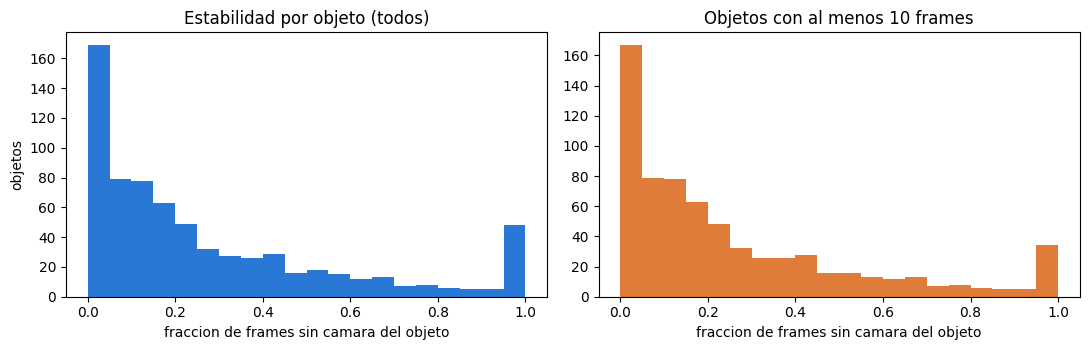

                    todos  con >= 10 frames
tipo                                       
mixto                 585               578
siempre con camara     73                71
siempre sin camara     47                33


**Lectura (generada).** Hay 705 objetos con una mediana de 87 frames. 10,4 % son siempre con cámara, 6,7 % siempre sin cámara y 83,0 % mixtos (entre los objetos con al menos 10 frames, mixtos: 84,8 %). Como 17,0 % de los objetos tiene el mismo estado en todos sus frames, la unidad de revisión sugerida es el **frame** (regla: objeto si la mayoría es constante). Mostramos las dos vistas.

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(obj["frac_sin"], bins=20, color=AZUL)
axes[0].set_xlabel("fraccion de frames sin camara del objeto"); axes[0].set_ylabel("objetos"); axes[0].set_title("Estabilidad por objeto (todos)")
o10 = obj[obj["frames"] >= 10]
axes[1].hist(o10["frac_sin"], bins=20, color=NARANJA)
axes[1].set_xlabel("fraccion de frames sin camara del objeto"); axes[1].set_title("Objetos con al menos 10 frames")
fig.tight_layout()
guardar_fig(fig, "07_estabilidad_por_objeto")
plt.show()
print(pd.DataFrame({"todos": estab_todos, "con >= 10 frames": estab_10}).fillna(0).astype(int).to_string())
display(Markdown(
    f"**Lectura (generada).** Hay {miles(len(obj))} objetos con una mediana de {obj['frames'].median():.0f} frames. {pct(estab_todos.get('siempre con camara', 0) / len(obj))} son siempre con cámara, "
    f"{pct(estab_todos.get('siempre sin camara', 0) / len(obj))} siempre sin cámara y {pct(estab_todos.get('mixto', 0) / len(obj))} mixtos"
    f" (entre los objetos con al menos 10 frames, mixtos: {pct(estab_10.get('mixto', 0) / max(estab_10.sum(), 1))}). "
    f"Como {pct(share_const)} de los objetos tiene el mismo estado en todos sus frames, la unidad de revisión sugerida es el **{UNIDAD}** (regla: objeto si la mayoría es constante). "
    f"Mostramos las dos vistas."))

## 9.2 Curvas de captura

Orden de revisión fuera de fold. Referencias: **azar** (diagonal), **orden ideal** (conociendo la etiqueta), **regla simple** (menos puntos LiDAR primero), **regresión logística** y **HGB**.

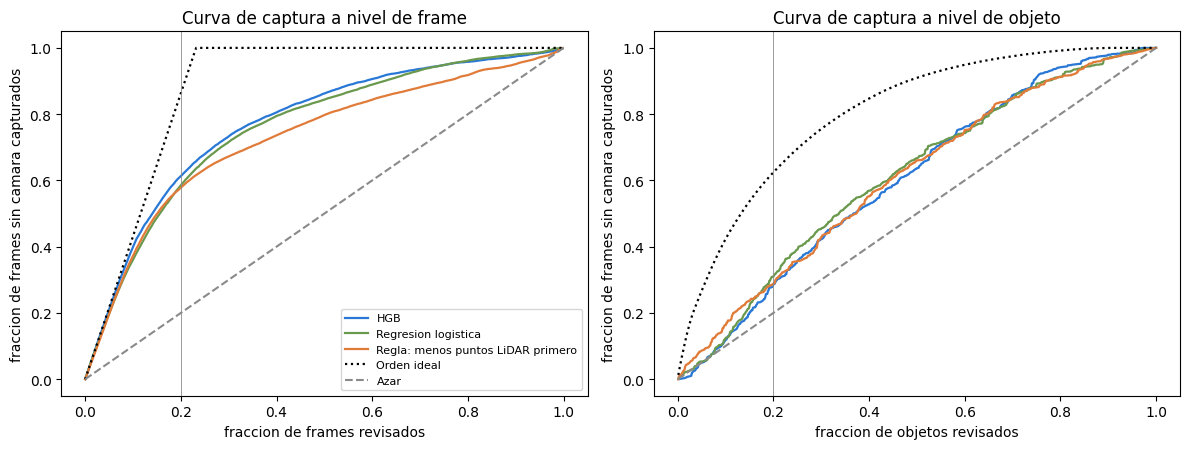

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
estilos = {"HGB": (AZUL, "-"), "Regresion logistica": (VERDE, "-"), "Regla: menos puntos LiDAR primero": (NARANJA, "-"), "Orden ideal": ("k", ":")}
for ax, nv in zip(axes, ["frame", "objeto"]):
    for n, (col, ls) in estilos.items():
        cum = CURVAS[nv][n]
        x = np.arange(1, len(cum) + 1) / len(cum)
        paso = max(len(cum) // 400, 1)
        ax.plot(x[::paso], cum[::paso], color=col, ls=ls, lw=1.6, label=n)
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", label="Azar")
    ax.axvline(0.2, color=GRIS, lw=0.6)
    ax.set_xlabel(f"fraccion de {nv}s revisados"); ax.set_ylabel("fraccion de frames sin camara capturados")
    ax.set_title(f"Curva de captura a nivel de {nv}")
axes[0].legend(fontsize=8, loc="lower right")
fig.tight_layout()
guardar_fig(fig, "07_curva_captura")
plt.show()

## 9.3 Métricas de captura con IC 95 % (bootstrap de segmentos)

In [51]:
for nv in ["frame", "objeto"]:
    t = GAN[nv].copy()
    t["valor (IC 95%)"] = [f"{v:.3f} ({lo:.3f} a {hi:.3f})" for v, lo, hi in zip(t["valor"], t["ic_lo"], t["ic_hi"])]
    print(f"\nNivel {nv}:")
    print(t.pivot(index="metodo", columns="metrica", values="valor (IC 95%)")[["Captura@10%", "Captura@20%", "Captura@30%", "Lift@20%", "Fraccion para 80%"]].to_string())
    ideal = metr(CURVAS[nv]["Orden ideal"])
    print("Orden ideal:", {k: round(float(v), 3) for k, v in ideal.items()})


Nivel frame:
metrica                                      Captura@10%            Captura@20%            Captura@30%               Lift@20%      Fraccion para 80%
metodo                                                                                                                                              
HGB                                0.399 (0.333 a 0.463)  0.613 (0.532 a 0.693)  0.733 (0.648 a 0.807)  3.066 (2.659 a 3.464)  0.391 (0.292 a 0.509)
Regla: menos puntos LiDAR primero  0.373 (0.312 a 0.437)  0.579 (0.501 a 0.653)  0.672 (0.609 a 0.725)  2.893 (2.504 a 3.267)  0.505 (0.432 a 0.613)
Regresion logistica                0.361 (0.288 a 0.434)  0.585 (0.485 a 0.684)  0.716 (0.629 a 0.807)  2.927 (2.427 a 3.419)  0.411 (0.292 a 0.538)
Orden ideal: {'Captura@10%': 0.432, 'Captura@20%': 0.863, 'Captura@30%': 1.0, 'Lift@20%': 4.316, 'Fraccion para 80%': 0.185}

Nivel objeto:
metrica                                      Captura@10%            Captura@20%            Captura@30

<a id="seccion-10"></a>
# 10. Apoyo no supervisado

**Por qué importa.** Si los peatones y ciclistas se agrupan en comportamientos distintos, podemos ver dónde se concentran las lagunas y dónde falla el modelo.
Estas pruebas **no deciden el target**; apoyan la lectura.

## 10.1 Especificación original (la que alimenta la tabla de decisión)

El agrupamiento original se calculó en la Sección 7.1 porque la tabla de decisión lo necesita. Acá lo leemos.

In [52]:
print("Perfil de cada cluster (especificacion original, calculado en la Seccion 7.1):")
print(perfil.round(2).to_string())
print()
print(tabla_cl.round(3).to_string())

Perfil de cada cluster (especificacion original, calculado en la Seccion 7.1):
         filas  pct_ciclistas  speed10  acel   giro  v_rad  v_tan  desp_real_m  pct_filas
cluster                                                                                  
0        16481           1.38     1.27 -0.00   1.12   1.14   0.03         2.48      22.12
1        30468           0.87     0.11  0.01   0.19  -0.01   0.01         0.26      40.89
2        11416           1.21     1.41  0.00   1.29  -0.84  -0.81         2.74      15.32
3         1466           1.64     0.75 -0.01  16.29   0.02   0.06         1.35       1.97
4          510          81.18     5.35  0.01   0.26   3.26   2.58        10.76       0.68
5        14165           2.01     1.30 -0.00   1.31  -0.85   0.66         2.49      19.01

   filas  desp_real_m  error_quieto  error_base  error_modelo  error_modelo_sin_speed  mejora_modelo_vs_base  segmentos
0  16481        2.479         2.479       0.300         0.314                   

In [53]:
k_ = RES["cluster"]
pc_ = perfil.sort_values("filas")
chico = pc_.index[0]
display(Markdown(
    f"**Lectura (generada).** Con k = {k_['k']} el silhouette es {n2(k_['silhouette'], 3)} y la estabilidad por segmento da ARI medio {n2(k_['ari_medio'], 3)} "
    f"(umbral {CRITERIOS['apoyo']['ari_min']}): " + ("cumple." if k_["ari_medio"] >= CRITERIOS["apoyo"]["ari_min"] else "queda **borderline, por debajo del umbral**.") +
    f" El cluster más pequeño ({miles(pc_.loc[chico, 'filas'])} filas, {pct(pc_.loc[chico, 'pct_filas'] / 100)} del total) tiene {pct(pc_.loc[chico, 'pct_ciclistas'] / 100, 0)} de ciclistas y una rapidez media de {n2(pc_.loc[chico, 'speed10'])} m/s: "
    f"son ciclistas rápidos. El error del modelo C varía {n2(k_['razon_error'])} veces entre clusters."))

**Lectura (generada).** Con k = 6 el silhouette es 0,394 y la estabilidad por segmento da ARI medio 0,798 (umbral 0.8): queda **borderline, por debajo del umbral**. El cluster más pequeño (510 filas, 0,7 % del total) tiene 81 % de ciclistas y una rapidez media de 5,35 m/s: son ciclistas rápidos. El error del modelo C varía 4,18 veces entre clusters.

## 10.2 Revisión posterior: k de 2 a 10, escalado robusto, KMeans vs GMM, PCA y cruce con `sin_camara`

No altera el criterio de apoyo de la tabla de decisión.

    silhouette KMeans  silhouette GMM     BIC GMM
2               0.735           0.024  593366.877
3               0.705           0.077  454800.307
4               0.545           0.085  401571.967
5               0.535           0.104  348007.561
6               0.554           0.115  295805.735
7               0.471           0.114  282062.650
8               0.295           0.103  249281.756
9               0.310           0.106  212983.575
10              0.314           0.100  206202.178



k elegido (max silhouette KMeans, escalado robusto): 2 | ARI KMeans vs GMM: -0.026 | estabilidad por segmento (ARI medio, 20 remuestreos): 0.719

Cruce con la tasa de sin_camara (KMeans original, k = 6 ):
           filas  filas en B  % ciclistas  rapidez media (m/s)  tasa sin_camara en B (%)
cluster                                                                                 
0        16481.0     10408.0         1.38                 1.27                     23.79
1        30468.0     21991.0         0.87                 0.11                     21.20
2        11416.0      8710.0         1.21                 1.41                     24.40
3         1466.0      1049.0         1.64                 0.75                     22.88
4          510.0       329.0        81.18                 5.35                     12.77
5        14165.0      9285.0         2.01                 1.30                     21.68

Cruce con la tasa de sin_camara (KMeans escalado robusto, k = 2 ):
              

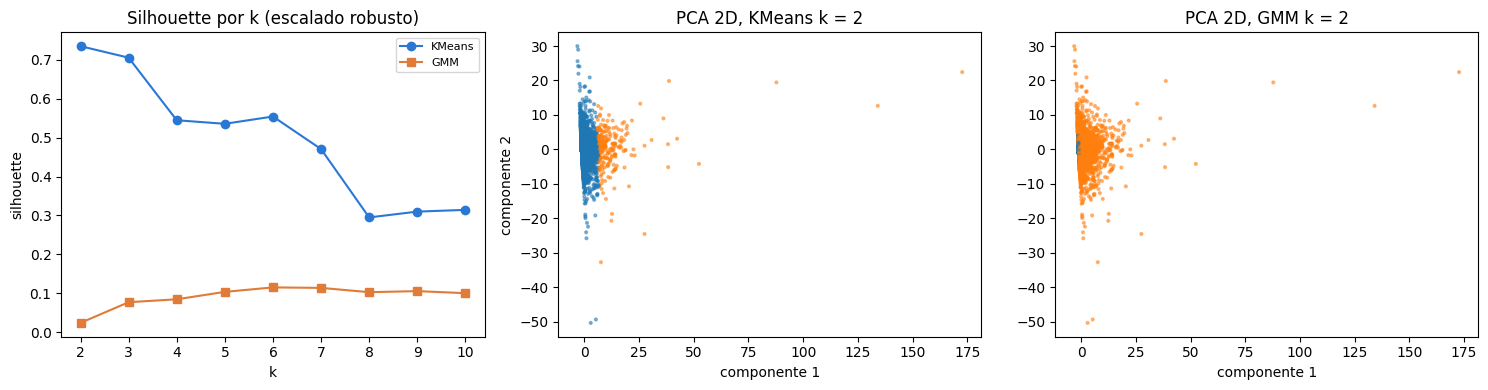

In [54]:
from sklearn.preprocessing import RobustScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

Zr = RobustScaler().fit_transform(Z)
sil_km, sil_gm, bic = {}, {}, {}
for k in range(2, 11):
    lab_k = KMeans(k, n_init=5, random_state=SEMILLA).fit_predict(Zr)
    sil_km[k] = silhouette_score(Zr[muestra_sil], lab_k[muestra_sil])
    gm = GaussianMixture(k, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(Zr)
    lg = gm.predict(Zr)
    sil_gm[k] = silhouette_score(Zr[muestra_sil], lg[muestra_sil]) if len(np.unique(lg[muestra_sil])) > 1 else np.nan
    bic[k] = gm.bic(Zr)
sel = pd.DataFrame({"silhouette KMeans": sil_km, "silhouette GMM": sil_gm, "BIC GMM": bic}).round(3)
print(sel.to_string())
k_ext = max(sil_km, key=sil_km.get)
km2 = KMeans(k_ext, n_init=10, random_state=SEMILLA).fit(Zr)
gm2 = GaussianMixture(k_ext, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(Zr)
T["cluster_ext"], T["cluster_gmm"] = km2.labels_, gm2.predict(Zr)
ari_km_gmm = adjusted_rand_score(T["cluster_ext"], T["cluster_gmm"])
aris2 = []
for b_ in range(20):
    ii = np.concatenate([idx_seg_T[s] for s in rng.choice(useg, len(useg), replace=True)])
    ii = rng.choice(ii, min(len(ii), 30000), replace=False)
    aris2.append(adjusted_rand_score(km2.labels_, KMeans(k_ext, n_init=3, random_state=b_).fit(Zr[ii]).predict(Zr)))
print(f"\nk elegido (max silhouette KMeans, escalado robusto): {k_ext} | ARI KMeans vs GMM: {ari_km_gmm:.3f} | estabilidad por segmento (ARI medio, 20 remuestreos): {np.mean(aris2):.3f}")
RES["cluster_ext"] = {"k": k_ext, "sil": sil_km[k_ext], "ari_km_gmm": ari_km_gmm, "ari_estab": float(np.mean(aris2))}

# Cruce con sin_camara (peatones/ciclistas en zona de camaras con etiqueta de camara)
lab = train[[GRUPO, "key.frame_timestamp_micros", "key.laser_object_id", TARGET]].rename(columns={"key.frame_timestamp_micros": "ts", "key.laser_object_id": "obj"})
Tl = T[["segment_id", "ts", "obj", "azimut_abs_deg", "cluster", "cluster_ext", "es_ciclista", "speed10", "desp"]].merge(lab, on=["segment_id", "ts", "obj"], how="left")
Tl["en_B"] = Tl[TARGET].notna() & (Tl["azimut_abs_deg"] <= ZONA_CAMARAS_DEG)
Tl["sin"] = 1 - Tl[TARGET]


def cruce(col):
    g = Tl.groupby(col).apply(lambda d: pd.Series({"filas": len(d), "filas en B": int(d["en_B"].sum()), "% ciclistas": d["es_ciclista"].mean() * 100,
                                                   "rapidez media (m/s)": d["speed10"].mean(), "tasa sin_camara en B (%)": d.loc[d["en_B"], "sin"].mean() * 100}), include_groups=False)
    return g.round(2)


print("\nCruce con la tasa de sin_camara (KMeans original, k =", K, "):")
print(cruce("cluster").to_string())
print("\nCruce con la tasa de sin_camara (KMeans escalado robusto, k =", k_ext, "):")
print(cruce("cluster_ext").to_string())

# PCA 2D
pca = PCA(2, random_state=SEMILLA).fit(Zr)
mm = T.sample(8000, random_state=SEMILLA)
P2 = pca.transform(Zr[mm.index])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(list(sil_km), list(sil_km.values()), marker="o", color=AZUL, label="KMeans")
axes[0].plot(list(sil_gm), list(sil_gm.values()), marker="s", color=NARANJA, label="GMM")
axes[0].set_xlabel("k"); axes[0].set_ylabel("silhouette"); axes[0].set_title("Silhouette por k (escalado robusto)"); axes[0].legend(fontsize=8)
axes[1].scatter(P2[:, 0], P2[:, 1], c=mm["cluster_ext"], cmap="tab10", s=4, alpha=0.5, vmin=0, vmax=9)
axes[1].set_title(f"PCA 2D, KMeans k = {k_ext}"); axes[1].set_xlabel("componente 1"); axes[1].set_ylabel("componente 2")
axes[2].scatter(P2[:, 0], P2[:, 1], c=mm["cluster_gmm"], cmap="tab10", s=4, alpha=0.5, vmin=0, vmax=9)
axes[2].set_title(f"PCA 2D, GMM k = {k_ext}"); axes[2].set_xlabel("componente 1")
fig.tight_layout()
guardar_fig(fig, "07_clusters_pca")
plt.show()

In [55]:
ce, k_ = RES["cluster_ext"], RES["cluster"]
ce_tab, or_tab = cruce("cluster_ext"), cruce("cluster")
tasa_e, tasa_o = ce_tab["tasa sin_camara en B (%)"], or_tab["tasa sin_camara en B (%)"]
tam = T["cluster_ext"].value_counts(normalize=True).sort_values()
ch = tasa_o.idxmin()
display(Markdown(
    f"**Lectura de la revisión posterior (generada).** Con escalado robusto y k de 2 a 10, el máximo silhouette de KMeans es {n2(ce['sil'], 3)} con k = {ce['k']}, "
    f"pero el cluster más pequeño reúne solo {pct(tam.iloc[0])} de las filas: separa un grupo atípico y no comportamientos distintos. "
    f"KMeans y GMM {'concuerdan' if ce['ari_km_gmm'] >= 0.5 else 'no concuerdan'} (ARI {n2(ce['ari_km_gmm'], 3)}) y la estabilidad por segmento es ARI {n2(ce['ari_estab'], 3)}. "
    f"La tasa de `sin_camara` en B va de {n2(tasa_e.min(), 1)} % a {n2(tasa_e.max(), 1)} % entre los clusters ampliados (diferencia de {n2(tasa_e.max() - tasa_e.min(), 1)} puntos) "
    f"y de {n2(tasa_o.min(), 1)} % a {n2(tasa_o.max(), 1)} % entre los originales ({n2(tasa_o.max() - tasa_o.min(), 1)} puntos). "
    f"El contraste marcado es el del cluster original {ch}: {int(or_tab.loc[ch, 'filas'])} filas, {n2(or_tab.loc[ch, '% ciclistas'], 0)} % de ciclistas y rapidez media de {n2(or_tab.loc[ch, 'rapidez media (m/s)'])} m/s, "
    f"con {n2(tasa_o.min(), 1)} % de `sin_camara`. Estas pruebas **no alteran el criterio de apoyo** de la Sección 7 (especificación original, ARI {n2(k_['ari_medio'], 3)}) ni deciden el target."))

**Lectura de la revisión posterior (generada).** Con escalado robusto y k de 2 a 10, el máximo silhouette de KMeans es 0,735 con k = 2, pero el cluster más pequeño reúne solo 2,8 % de las filas: separa un grupo atípico y no comportamientos distintos. KMeans y GMM no concuerdan (ARI -0,026) y la estabilidad por segmento es ARI 0,719. La tasa de `sin_camara` en B va de 22,3 % a 22,9 % entre los clusters ampliados (diferencia de 0,5 puntos) y de 12,8 % a 24,4 % entre los originales (11,6 puntos). El contraste marcado es el del cluster original 4: 510 filas, 81 % de ciclistas y rapidez media de 5,35 m/s, con 12,8 % de `sin_camara`. Estas pruebas **no alteran el criterio de apoyo** de la Sección 7 (especificación original, ARI 0,798) ni deciden el target.

In [56]:
or_tab = cruce("cluster")
tasa_o = or_tab["tasa sin_camara en B (%)"]
ch = tasa_o.idxmin()
resto = tasa_o.drop(ch)
rango_resto = resto.max() - resto.min()
display(Markdown(
    f"**Hallazgo (generado).** En {len(resto)} de los {len(tasa_o)} clusters de comportamiento la tasa de `sin_camara` va de {n2(resto.min(), 1)} % a {n2(resto.max(), 1)} % (rango de {n2(rango_resto, 1)} puntos)" +
    (", es decir, casi igual" if rango_resto <= 5 else "") +
    f"; el modo de moverse " + ("no explica la cobertura" if rango_resto <= 5 else "explica parte de la cobertura") +
    f". El cluster más pequeño (cluster {ch}: {int(or_tab.loc[ch, 'filas'])} filas, {n2(or_tab.loc[ch, '% ciclistas'], 0)} % de ciclistas, rapidez media de {n2(or_tab.loc[ch, 'rapidez media (m/s)'])} m/s) tiene una tasa menor, {n2(tasa_o.loc[ch], 1)} %. "
    f"El análisis no supervisado orientado a B (observabilidad: distancia, puntos, densidad y oclusión) está en el notebook `08_analisis_observabilidad_sin_camara.ipynb`."))

**Hallazgo (generado).** En 5 de los 6 clusters de comportamiento la tasa de `sin_camara` va de 21,2 % a 24,4 % (rango de 3,2 puntos), es decir, casi igual; el modo de moverse no explica la cobertura. El cluster más pequeño (cluster 4: 510 filas, 81 % de ciclistas, rapidez media de 5,35 m/s) tiene una tasa menor, 12,8 %. El análisis no supervisado orientado a B (observabilidad: distancia, puntos, densidad y oclusión) está en el notebook `08_analisis_observabilidad_sin_camara.ipynb`.

<a id="seccion-11"></a>
# 11. Limitaciones

- **B solo aplica a frames que ya tienen etiquetas de cámara.** En frames sin etiquetas de cámara no hay forma de saber si falta confirmación.
- **Pocos ciclistas** y concentrados en pocos segmentos.
- **Muestra seleccionada por etiquetado denso**: los segmentos con etiquetado ralo o asociación vacía quedaron fuera.
- **Los folds se estratificaron por `tiene_camara`**, no por `sin_camara` en la zona de cámaras ni por el target de C; la prevalencia varía entre folds.
- **El valor es del lado de los datos, no del auto.**
- **El factor dominante son los puntos LiDAR**: el modelo captura sobre todo qué tan bien observado quedó el objeto.

## 11.1 Verificación de conteos en el test (solo conteos, sin evaluar modelos)

El split no se rehace. Solo comprobamos que los segmentos de test tengan suficientes peatones/ciclistas en la zona de cámaras y positivos de `sin_camara`.

In [57]:
sup = cargar("waymo_supervisado", "data/02_intermediate/waymo_supervisado.parquet")
sup = sup[sup["segment_id"].isin(SEGS_TEST)][["segment_id", "location", "time_of_day", "object_type", "tiene_camara", "box_center_x", "box_center_y"]].copy()
sup["azimut_abs"] = np.degrees(np.arctan2(sup["box_center_y"], sup["box_center_x"])).abs()
sb = sup[sup["object_type"].isin(VRU) & (sup["azimut_abs"] <= ZONA_CAMARAS_DEG)]
conteo_test = sb.groupby(["segment_id", "location", "time_of_day"]).agg(filas_B=("tiene_camara", "size"), sin_camara=("tiene_camara", lambda s: int((s == 0).sum())),
                                                                        con_camara=("tiene_camara", "sum")).reset_index()
conteo_test["pct_sin"] = (conteo_test["sin_camara"] / conteo_test["filas_B"] * 100).round(1)
conteo_test["segment_id"] = conteo_test["segment_id"].str[:12]
print(conteo_test.to_string(index=False))
tot = sb["tiene_camara"].agg(["size", "sum"])
n_test_B, n_test_sin = int(tot["size"]), int(tot["size"] - tot["sum"])
sb100 = sb[sb["azimut_abs"] <= AZ_MAX]
sb_franja = sb[sb["azimut_abs"] > AZ_MAX]
c100 = sb100.groupby("segment_id").agg(filas_B_principal=("tiene_camara", "size"), sin_camara_principal=("tiene_camara", lambda s_: int((s_ == 0).sum()))).reset_index()
c100 = c100.merge(sb_franja.groupby("segment_id").agg(filas_en_franja=("tiene_camara", "size"), sin_en_franja=("tiene_camara", lambda s_: int((s_ == 0).sum()))).reset_index(), on="segment_id", how="left")
c100[["filas_en_franja", "sin_en_franja"]] = c100[["filas_en_franja", "sin_en_franja"]].fillna(0).astype(int)
c100["pct_sin_principal"] = (c100["sin_camara_principal"] / c100["filas_B_principal"] * 100).round(1)
c100["segment_id"] = c100["segment_id"].str[:12]
# archivo de conteos del test (solo conteos por segmento, sin variables ni etiquetas por fila); lo lee el plan de evaluacion del notebook 09
conteos_csv = conteo_test.rename(columns={"filas_B": "filas_B_120", "sin_camara": "sin_camara_120"})[["segment_id", "location", "time_of_day", "filas_B_120", "sin_camara_120"]].merge(
    c100[["segment_id", "filas_B_principal", "sin_camara_principal", "filas_en_franja", "sin_en_franja"]], on="segment_id", how="left")
conteos_csv.to_csv(RUTA_REPORTING / "07_conteos_test.csv", index=False)
print(f"Poblacion principal (|azimut| <= {AZ_MAX}), solo conteos en test:")
print(c100.to_string(index=False))
RES["test_cnt_principal"] = {"filas": int(len(sb100)), "sin": int((sb100["tiene_camara"] == 0).sum()), "franja": int(len(sb_franja)), "franja_sin": int((sb_franja["tiene_camara"] == 0).sum()),
                             "min_filas": int(c100["filas_B_principal"].min()), "min_sin": int(c100["sin_camara_principal"].min()), "tabla": c100}
del sup, sb, sb100, sb_franja
RES["test_cnt"] = {"seg": len(conteo_test), "filas_B": n_test_B, "sin": n_test_sin, "min_filas": int(conteo_test["filas_B"].min()), "min_sin": int(conteo_test["sin_camara"].min()),
                   "prev": n_test_sin / n_test_B}
display(Markdown(
    f"**Conteos (generados).** Los {len(SEGS_TEST)} segmentos de test aportan {miles(n_test_B)} filas de peatones/ciclistas en la zona de cámaras y {miles(n_test_sin)} positivos de `sin_camara` "
    f"(prevalencia {pct(n_test_sin / n_test_B)}, contra {pct(RES['B']['prevalencia'])} en train). El segmento con menos filas tiene {RES['test_cnt']['min_filas']} y el que menos positivos, {RES['test_cnt']['min_sin']}. "
    f"No se evaluó ningún modelo sobre estos datos."))

[10/18/26 13:13:10] INFO     Loading data from waymo_supervisado (ParquetDataset)...           ]8;id=15257337;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=15257338;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

  segment_id       location time_of_day  filas_B  sin_camara  con_camara  pct_sin
102124064984    location_sf   Dawn/Dusk      882          65         817      7.4
141430544948 location_other         Day     1695         280        1415     16.5
167359384489 location_other         Day      203           3         200      1.5
221704303323    location_sf       Night     4932        1062        3870     21.5
257766998801    location_sf         Day     6837        2298        4539     33.6
497181704156   location_phx         Day      384          29         355      7.6
645616575015   location_phx         Day     2170         631        1539     29.1
703836276130   location_phx         Day      194          10         184      5.2
Poblacion principal (|azimut| <= 100), solo conteos en test:
  segment_id  filas_B_principal  sin_camara_principal  filas_en_franja  sin_en_franja  pct_sin_principal
102124064984                851                    48               31             17           

**Conteos (generados).** Los 8 segmentos de test aportan 17.297 filas de peatones/ciclistas en la zona de cámaras y 4.378 positivos de `sin_camara` (prevalencia 25,3 %, contra 23,2 % en train). El segmento con menos filas tiene 194 y el que menos positivos, 3. No se evaluó ningún modelo sobre estos datos.

In [58]:
ct_ = conteo_test.copy()
tot_ = ct_["filas_B"].sum()
top2 = ct_.nlargest(2, "filas_B")["filas_B"].sum() / tot_
por_momento = ct_.groupby("time_of_day").size()
un_solo = [k for k, n in por_momento.items() if n == 1]
rango_test = (float(ct_["pct_sin"].min()), float(ct_["pct_sin"].max()))
sin_seg_train = bz.groupby(GRUPO)["sin"].mean() * 100
rango_train = (float(sin_seg_train.min()), float(sin_seg_train.max()))
RES["test_comp"] = {"segmentos": len(ct_), "top2": top2, "por_momento": por_momento.to_dict(), "un_solo_segmento": " y ".join(un_solo) if un_solo else "ningún momento del día", "verbo": ("tienen" if len(un_solo) > 1 else "tiene"),
                    "rango_test": rango_test, "rango_train": rango_train, "mediana_train": float(sin_seg_train.median())}
print("Segmentos de test por momento del dia:", por_momento.to_dict())
display(Markdown(
    f"**Composición del test y variabilidad del etiquetado (generado).** El test tiene {len(ct_)} segmentos; los dos más grandes aportan el {pct(top2)} de las filas de B. "
    f"Segmentos por momento del día: {', '.join(f'{k} {n}' for k, n in por_momento.items())}; " +
    (f"{' y '.join(un_solo)} {'tienen' if len(un_solo) > 1 else 'tiene'} un solo segmento cada uno, por lo que **la equidad por momento del día se mide con los folds de train y no con el test**. " if un_solo else "") +
    f"La tasa de `sin_camara` por segmento va de {n2(rango_test[0], 1)} % a {n2(rango_test[1], 1)} % en el test y de {n2(rango_train[0], 1)} % a {n2(rango_train[1], 1)} % en train (mediana {n2(float(sin_seg_train.median()), 1)} %): "
    f"el etiquetado de cámara es muy desigual entre segmentos."))

Segmentos de test por momento del dia: {'Dawn/Dusk': 1, 'Day': 6, 'Night': 1}


**Composición del test y variabilidad del etiquetado (generado).** El test tiene 8 segmentos; los dos más grandes aportan el 68,0 % de las filas de B. Segmentos por momento del día: Dawn/Dusk 1, Day 6, Night 1; Dawn/Dusk y Night tienen un solo segmento cada uno, por lo que **la equidad por momento del día se mide con los folds de train y no con el test**. La tasa de `sin_camara` por segmento va de 1,5 % a 33,6 % en el test y de 0,6 % a 39,5 % en train (mediana 18,3 %): el etiquetado de cámara es muy desigual entre segmentos.

In [59]:
tp = RES["test_cnt_principal"]
display(Markdown(
    f"**Conteos para la población principal (|azimut| ≤ {AZ_MAX}°, generados; solo conteos, sin evaluar ningún modelo).** Los {len(SEGS_TEST)} segmentos de test aportan {miles(tp['filas'])} filas de peatones/ciclistas y {miles(tp['sin'])} positivos de `sin_camara` "
    f"(prevalencia {pct(tp['sin'] / tp['filas'])}); el segmento con menos filas tiene {tp['min_filas']} y el que menos positivos, {tp['min_sin']}. "
    f"Otras {miles(tp['franja'])} filas del test caen en la franja {AZ_MAX}–{ZONA_CAMARAS_DEG}° ({miles(tp['franja_sin'])} de ellas `sin_camara`, el {pct(tp['franja_sin'] / max(tp['franja'], 1))}) y quedan fuera de la población principal."))

**Conteos para la población principal (|azimut| ≤ 100°, generados; solo conteos, sin evaluar ningún modelo).** Los 8 segmentos de test aportan 16.062 filas de peatones/ciclistas y 3.734 positivos de `sin_camara` (prevalencia 23,2 %); el segmento con menos filas tiene 155 y el que menos positivos, 2. Otras 1.235 filas del test caen en la franja 100–120° (644 de ellas `sin_camara`, el 52,1 %) y quedan fuera de la población principal.

<a id="seccion-12"></a>
# 12. Texto para el README y resumen ejecutivo

Genera `docs/decision_target_ep2.md` con la decisión, la tabla de descartes, las cifras, la declaración del problema, las limitaciones y los KPIs a medir en el notebook 09.

In [60]:
a, b, c, d_, e_, k_ = RES["A"], RES["B"], RES["C"], RES["D"], RES["E"], RES["cluster"]
v, tc = RES["valor"], RES["test_comp"]
fallos = {t: decision[(decision["target"] == t) & decision["decide"] & ~decision["cumple"]]["criterio"].tolist() for t in "ABC"}

limitaciones = [
    "B solo aplica a frames que ya tienen etiquetas de cámara.",
    f"Pocos ciclistas ({miles(d_['ciclistas'])} filas en train, en {d_['segmentos']} segmentos).",
    f"Muestra seleccionada por etiquetado denso ({n_sel} de {len(reg)} segmentos evaluados).",
    "Los folds se estratificaron por `tiene_camara`, no por `sin_camara` en la zona de cámaras.",
    f"El valor es del lado de los datos, no del auto; el factor dominante son los puntos LiDAR (sin ellos AUC {n2(b['auc_sin_puntos'], 3)}).",
    f"Composición del test: {tc['segmentos']} segmentos; los dos más grandes aportan el {pct(tc['top2'])} de las filas de B; {tc['un_solo_segmento']} {tc['verbo']} un solo segmento, por lo que la equidad por momento del día se mide con los folds de train y no con el test.",
    f"El etiquetado varía mucho entre segmentos: la tasa de `sin_camara` va de {n2(tc['rango_test'][0], 1)} % a {n2(tc['rango_test'][1], 1)} % por segmento en el test y de {n2(tc['rango_train'][0], 1)} % a {n2(tc['rango_train'][1], 1)} % en train.",
]
kpis = ["AUC-ROC y PR-AUC fuera de fold", "Captura@20 %, Fracción para 80 % y Lift@20 % (curva de captura, IC 95 % por segmentos)", "Recall y precisión en el punto de operación elegido",
        "Brecha Day/Night y por ubicación", "Estabilidad entre folds"]

texto = f'''### Cambio de target para EP2: de `tiene_camara` a `sin_camara`

**Decisión.** {veredicto}

**Por qué.** En train, vehículos y señales no tienen ningún positivo ({miles(len(no_vru))} filas), así que `tiene_camara` en todos los objetos mezcla la clase del objeto con la cobertura de cámaras. \
Una regla de una línea alcanza AUC {n2(a['auc_regla'], 3)} y el modelo {n2(a['auc_modelo'], 3)}. Dentro de peatones y ciclistas en la zona de cámaras, `sin_camara` es la clase rara \
({pct(b['prevalencia'])}) y se predice con AUC {n2(b['auc'], 3)} (IC 95 % {n2(b['auc_ic'][0], 3)}–{n2(b['auc_ic'][1], 3)}), PR-AUC {n2(b['prauc'], 3)}, AUC mínimo por fold {n2(b['auc_min_fold'], 3)}.

**El problema.** En Waymo Open Dataset v2 los `lidar_box` son cajas 3D etiquetadas, no la salida de un detector; según nuestra lectura de la documentación, la asociación cámara-LiDAR los enlaza con su par 2D de cámara cuando existe. \
El problema es auditar qué cajas 3D etiquetadas no tienen su par 2D de cámara.

**Candidatas descartadas**

{md_tabla(descartes, indice=False)}

**Valor práctico de B (versión previa, población de {ZONA_CAMARAS_DEG}°).** Para encontrar el 80 % de las lagunas hay que revisar el {pct(v['frac80_f'])} de los frames con el modelo, el {pct(v['frac80_regla_f'])} con la regla simple de menos puntos LiDAR primero y el 80,0 % al azar \
(diferencia modelo menos regla: {v['d80'] * 100:+.1f} puntos, IC 95 % {v['d80_ic'][0] * 100:+.1f} a {v['d80_ic'][1] * 100:+.1f}). En el tope de la lista (Captura@20 %) la ventaja sobre la regla es pequeña \
({v['d20'] * 100:+.1f} puntos, IC {v['d20_ic'][0] * 100:+.1f} a {v['d20_ic'][1] * 100:+.1f}): el modelo aporta más en alta cobertura. A nivel de objeto casi no prioriza (el {pct(RES['objeto']['share_mixto'])} de los objetos es mixto), \
y la unidad sugerida es el frame. Las horas ahorradas dependen de un supuesto de {SEGUNDOS_POR_REVISION} s por revisión que no es un dato medido.

{ACT_TXT}

**Población principal.** La población de EP2 es |azimut| ≤ {AZ_MAX}° (peatones y ciclistas); la franja {AZ_MAX}–{ZONA_CAMARAS_DEG}° queda fuera porque la ausencia de par 2D ahí es en buena parte geométrica (notebook 08). El target (`sin_camara`) y el split no cambian.

{declaracion}

**Criterios fijados antes de calcular** (Sección 3 del notebook `07_decision_target_ep2.ipynb`), después de la exploración del notebook 06; los umbrales no se cambiaron al ver resultados.

**Limitaciones**

''' + "\n".join(f"- {l}" for l in limitaciones) + f'''

**KPIs a medir en el notebook 09** (sin cifras prometidas): ''' + "; ".join(kpis) + ".\n"
(RUTA_DOCS / "decision_target_ep2.md").write_text(texto, encoding="utf-8")
print(f"Escrito {RUTA_DOCS / 'decision_target_ep2.md'} ({len(texto)} caracteres)")
display(Markdown(texto))

Escrito C:\Users\maico\waymo-evaluacion\docs\decision_target_ep2.md (5833 caracteres)


### Cambio de target para EP2: de `tiene_camara` a `sin_camara`

**Decisión.** Target elegido para EP2: B.

**Por qué.** En train, vehículos y señales no tienen ningún positivo (265.377 filas), así que `tiene_camara` en todos los objetos mezcla la clase del objeto con la cobertura de cámaras. Una regla de una línea alcanza AUC 0,975 y el modelo 0,992. Dentro de peatones y ciclistas en la zona de cámaras, `sin_camara` es la clase rara (23,2 %) y se predice con AUC 0,854 (IC 95 % 0,810–0,897), PR-AUC 0,747, AUC mínimo por fold 0,824.

**El problema.** En Waymo Open Dataset v2 los `lidar_box` son cajas 3D etiquetadas, no la salida de un detector; según nuestra lectura de la documentación, la asociación cámara-LiDAR los enlaza con su par 2D de cámara cuando existe. El problema es auditar qué cajas 3D etiquetadas no tienen su par 2D de cámara.

**Candidatas descartadas**

| candidata | motivo | evidencia |
|---|---|---|
| A: tiene_camara en todos los objetos | dominado por clase y zona de cámaras | regla R2 AUC 0,975; modelo 0,992 (+0,018, techo 0,025); PR-AUC +0,163; 0 positivos en 265.377 filas de vehículos y señales |
| C: desplazamiento a 2 s | la velocidad constante ya lo resuelve; el modelo no la mejora | error 0,28 m (velocidad constante) vs 0,29 m (modelo); mejora -2,4 %, IC 95 % inferior -11,6 %; gana en 2 de 5 folds |
| D: peatón vs ciclista | pocos ciclistas y bajo valor de negocio | 2,09 % ciclistas en 12 segmentos; folds sin ciclistas: 1 de 5; AUC 0,988 vs 0,703 del baseline simple |
| E: conflicto con el corredor a 2 s | eventos insuficientes | 68 casos, 5 objetos distintos, 2 segmentos, 2 de 5 folds |

**Valor práctico de B (versión previa, población de 120°).** Para encontrar el 80 % de las lagunas hay que revisar el 39,1 % de los frames con el modelo, el 50,5 % con la regla simple de menos puntos LiDAR primero y el 80,0 % al azar (diferencia modelo menos regla: -11.4 puntos, IC 95 % -19.0 a -6.1). En el tope de la lista (Captura@20 %) la ventaja sobre la regla es pequeña (+3.5 puntos, IC +0.2 a +7.4): el modelo aporta más en alta cobertura. A nivel de objeto casi no prioriza (el 83,0 % de los objetos es mixto), y la unidad sugerida es el frame. Las horas ahorradas dependen de un supuesto de 20 s por revisión que no es un dato medido.

**Actualización posterior al 08 y 09 (las cifras de arriba son de la versión previa, población de 120°).** La población principal pasó de 120° a |azimut| ≤ 100° porque en 100–120° la ausencia de par 2D es en buena parte geométrica (08). En la población principal (64.509 filas) el mejor baseline simple es Regla: menos puntos top (AUC 0,862, Fracción para 80 % 37,8 %) y la recomendación del 09 es **Regla: menos puntos top**. En la población de 120°, con los modelos reentrenados en el 09, el HGB menos la regla de puntos da -9.0 puntos en Fracción para 80 % (IC -20.0 a -2.0) y menos la regla geométrica +4.8 puntos (IC -1.3 a +9.1): la ventaja de -11.4 puntos frente a la regla de puntos de la versión previa **no se sostiene** al compararla con un baseline geométrico.

**Población principal.** La población de EP2 es |azimut| ≤ 100° (peatones y ciclistas); la franja 100–120° queda fuera porque la ausencia de par 2D ahí es en buena parte geométrica (notebook 08). El target (`sin_camara`) y el split no cambian.

> **Declaración del problema para el informe**
>
> **Problema.** El 23,2 % de las cajas 3D etiquetadas (`lidar_box`) de peatones y ciclistas dentro de la zona de cámaras no tiene su par 2D de cámara y hoy no se sabe cuáles son sin revisarlas. **Objetivo.** Estimar, con solo atributos de la caja 3D etiquetada, la probabilidad de que no tenga su par 2D y entregar una lista priorizada para revisión humana. **Métrica de éxito.** AUC-ROC y PR-AUC fuera de fold (versión previa, población de 120°: 0,854 y 0,747), y la fracción de frames que hay que revisar para cubrir el 80 % de las lagunas (versión previa, 120°: 39,1 % con el modelo, 50,5 % con la regla simple y 80,0 % al azar), con brecha entre grupos de día, noche y ubicación. **Alcance.** Peatones y ciclistas con |azimut| ≤ 100° (población principal; la versión previa usaba 120°) en frames con etiquetas de cámara, en 33 segmentos de train de Waymo Open Dataset v2. **Limitación principal.** El modelo captura cobertura de etiquetado y, sobre todo, la calidad de observación del LiDAR (sin puntos LiDAR el AUC cae a 0,654); `speed_mps` proviene de la etiqueta y su ablación casi no mueve el AUC (-0.004); el modelo no mide visibilidad física de la cámara ni sirve como alerta dentro del auto.

**Criterios fijados antes de calcular** (Sección 3 del notebook `07_decision_target_ep2.ipynb`), después de la exploración del notebook 06; los umbrales no se cambiaron al ver resultados.

**Limitaciones**

- B solo aplica a frames que ya tienen etiquetas de cámara.
- Pocos ciclistas (2.105 filas en train, en 12 segmentos).
- Muestra seleccionada por etiquetado denso (41 de 91 segmentos evaluados).
- Los folds se estratificaron por `tiene_camara`, no por `sin_camara` en la zona de cámaras.
- El valor es del lado de los datos, no del auto; el factor dominante son los puntos LiDAR (sin ellos AUC 0,654).
- Composición del test: 8 segmentos; los dos más grandes aportan el 68,0 % de las filas de B; Dawn/Dusk y Night tienen un solo segmento, por lo que la equidad por momento del día se mide con los folds de train y no con el test.
- El etiquetado varía mucho entre segmentos: la tasa de `sin_camara` va de 1,5 % a 33,6 % por segmento en el test y de 0,6 % a 39,5 % en train.

**KPIs a medir en el notebook 09** (sin cifras prometidas): AUC-ROC y PR-AUC fuera de fold; Captura@20 %, Fracción para 80 % y Lift@20 % (curva de captura, IC 95 % por segmentos); Recall y precisión en el punto de operación elegido; Brecha Day/Night y por ubicación; Estabilidad entre folds.


In [61]:
# Resumen ejecutivo generado (el mismo texto se copia a la Seccion 0 despues de ejecutar)
resumen = f'''**Decisión.** {veredicto}

**Razones**

1. `tiene_camara` en todos los objetos queda dominado por la clase: vehículos y señales tienen 0 positivos en {miles(len(no_vru))} filas, y una regla de una línea da AUC {n2(a['auc_regla'], 3)} (el modelo, {n2(a['auc_modelo'], 3)}).
2. `sin_camara` en peatones y ciclistas dentro de la zona de cámaras es la clase rara ({pct(b['prevalencia'])}) y se predice con AUC {n2(b['auc'], 3)} (IC 95 % {n2(b['auc_ic'][0], 3)}–{n2(b['auc_ic'][1], 3)}), con AUC mínimo por fold {n2(b['auc_min_fold'], 3)} y brechas Day/Night de {n2(b['brecha_dn'], 3)}.
3. El desplazamiento a 2 s (C) no mejora la velocidad constante: error {n2(c['err_base'])} m contra {n2(c['err_con'])} m del modelo ({pct(c['rel_con'])}); peatón vs ciclista (D) y conflicto (E) también se descartan (D: {miles(d_['ciclistas'])} filas de ciclistas en {d_['segmentos']} segmentos y bajo valor de negocio; E: {e_['casos']} casos de conflicto en {e_['objetos']} objetos).
4. Valor práctico (versión previa, población de {ZONA_CAMARAS_DEG}°): para encontrar el 80 % de las cajas 3D etiquetadas sin par 2D hay que revisar el {pct(v['frac80_f'])} de los frames con el modelo, el {pct(v['frac80_regla_f'])} con la regla simple de menos puntos LiDAR primero y el 80,0 % al azar (modelo menos regla: {v['d80'] * 100:+.1f} puntos, IC 95 % {v['d80_ic'][0] * 100:+.1f} a {v['d80_ic'][1] * 100:+.1f}). En el tope de la lista (Captura@20 %) la ventaja sobre la regla es pequeña ({v['d20'] * 100:+.1f} puntos): el modelo aporta más en alta cobertura. {ACT_CORTO}

**Limitaciones**

- Los puntos LiDAR sostienen el modelo (sin ellos AUC {n2(b['auc_sin_puntos'], 3)}): modela cobertura de etiquetado y calidad de observación, no visibilidad física de la cámara, y no sirve como alerta dentro del auto.
- Pocos ciclistas, muestra con etiquetado denso, folds estratificados por `tiene_camara`, y un test de {tc['segmentos']} segmentos con etiquetado muy desigual (`sin_camara` de {n2(tc['rango_test'][0], 1)} % a {n2(tc['rango_test'][1], 1)} % por segmento).
- {"El movimiento del auto para C se estimó con señales de tránsito porque no había vehicle_pose." if len(SEGS_CON_POSE) < len(SEGS_TRAIN) else "El movimiento del auto para C usó vehicle_pose."}

Detalle del problema de negocio en la [Sección 8](#seccion-8).'''
(RUTA_REPORTING / "resumen_ejecutivo_ep2.md").write_text(resumen, encoding="utf-8")
display(Markdown("## Resumen ejecutivo generado\n\n" + resumen))

## Resumen ejecutivo generado

**Decisión.** Target elegido para EP2: B.

**Razones**

1. `tiene_camara` en todos los objetos queda dominado por la clase: vehículos y señales tienen 0 positivos en 265.377 filas, y una regla de una línea da AUC 0,975 (el modelo, 0,992).
2. `sin_camara` en peatones y ciclistas dentro de la zona de cámaras es la clase rara (23,2 %) y se predice con AUC 0,854 (IC 95 % 0,810–0,897), con AUC mínimo por fold 0,824 y brechas Day/Night de 0,000.
3. El desplazamiento a 2 s (C) no mejora la velocidad constante: error 0,28 m contra 0,29 m del modelo (-2,4 %); peatón vs ciclista (D) y conflicto (E) también se descartan (D: 2.105 filas de ciclistas en 12 segmentos y bajo valor de negocio; E: 68 casos de conflicto en 5 objetos).
4. Valor práctico (versión previa, población de 120°): para encontrar el 80 % de las cajas 3D etiquetadas sin par 2D hay que revisar el 39,1 % de los frames con el modelo, el 50,5 % con la regla simple de menos puntos LiDAR primero y el 80,0 % al azar (modelo menos regla: -11.4 puntos, IC 95 % -19.0 a -6.1). En el tope de la lista (Captura@20 %) la ventaja sobre la regla es pequeña (+3.5 puntos): el modelo aporta más en alta cobertura. **Actualización:** la población principal pasa a |azimut| ≤ 100° y, frente a la regla geométrica, la diferencia del HGB en la población de 120° es +4.8 puntos en Fracción para 80 % (IC -1.3 a +9.1); la ventaja de la versión previa no se sostiene. Recomendación del 09: Regla: menos puntos top.

**Limitaciones**

- Los puntos LiDAR sostienen el modelo (sin ellos AUC 0,654): modela cobertura de etiquetado y calidad de observación, no visibilidad física de la cámara, y no sirve como alerta dentro del auto.
- Pocos ciclistas, muestra con etiquetado denso, folds estratificados por `tiene_camara`, y un test de 8 segmentos con etiquetado muy desigual (`sin_camara` de 1,5 % a 33,6 % por segmento).
- El movimiento del auto para C se estimó con señales de tránsito porque no había vehicle_pose.

Detalle del problema de negocio en la [Sección 8](#seccion-8).

## Actualización posterior al 08 y 09 (recuadro generado)

Este recuadro se genera al final, con todas las cifras disponibles, y se copia a la cabecera del notebook bajo el resumen ejecutivo.

In [62]:
afectadas = [f"Sección 5 (B): AUC {n2(RES['B']['auc'], 3)}, PR-AUC {n2(RES['B']['prauc'], 3)}, AUC mínimo por fold {n2(RES['B']['auc_min_fold'], 3)}, brecha Day/Night {n2(RES['B']['brecha_dn'], 3)}",
             f"Sección 7: los criterios de B de la tabla de decisión se evaluaron en la población de {ZONA_CAMARAS_DEG}°",
             f"Sección 8.4 y 9: Fracción para 80 % de {pct(RES['valor']['frac80_f'])} (modelo) y {pct(RES['valor']['frac80_regla_f'])} (regla de puntos), diferencia de {RES['valor']['d80'] * 100:+.1f} puntos",
             f"Sección 11.1: los conteos del test de {miles(RES['test_cnt']['filas_B'])} filas de B y {miles(RES['test_cnt']['sin'])} positivos son de la población de {ZONA_CAMARAS_DEG}° (para la principal, ver el párrafo de conteos de esa sección)"]
no_afectadas = "Las secciones 4 (A), 6 (C, D, E) y 10 no dependen del límite de azimut de B (usan todos los objetos o todos los peatones y ciclistas) y no cambian."
actualizacion = (f"**La población principal pasa de {ZONA_CAMARAS_DEG}° a |azimut| ≤ {AZ_MAX}° por el hallazgo de la franja** (notebook 08, A.6 y A.7: la tasa de `sin_camara` sube a {pct(float(yB[(bz['azimut_abs_deg'] > AZ_MAX).values].mean()))} en {AZ_MAX}–{ZONA_CAMARAS_DEG}°). "
                 f"El target (`sin_camara`), el split y el veredicto no cambian.\n\n**Cifras de este notebook que eran para la población de {ZONA_CAMARAS_DEG}° y quedan como versión previa:**\n\n" + "\n".join(f"- {t}" for t in afectadas) + f"\n\n{no_afectadas}\n\n{ACT_TXT}")
(RUTA_REPORTING / "actualizacion_07.md").write_text(actualizacion, encoding="utf-8")
display(Markdown("### Actualización posterior al 08 y 09\n\n" + actualizacion))

### Actualización posterior al 08 y 09

**La población principal pasa de 120° a |azimut| ≤ 100° por el hallazgo de la franja** (notebook 08, A.6 y A.7: la tasa de `sin_camara` sube a 62,2 % en 100–120°). El target (`sin_camara`), el split y el veredicto no cambian.

**Cifras de este notebook que eran para la población de 120° y quedan como versión previa:**

- Sección 5 (B): AUC 0,854, PR-AUC 0,747, AUC mínimo por fold 0,824, brecha Day/Night 0,000
- Sección 7: los criterios de B de la tabla de decisión se evaluaron en la población de 120°
- Sección 8.4 y 9: Fracción para 80 % de 39,1 % (modelo) y 50,5 % (regla de puntos), diferencia de -11.4 puntos
- Sección 11.1: los conteos del test de 17.297 filas de B y 4.378 positivos son de la población de 120° (para la principal, ver el párrafo de conteos de esa sección)

Las secciones 4 (A), 6 (C, D, E) y 10 no dependen del límite de azimut de B (usan todos los objetos o todos los peatones y ciclistas) y no cambian.

**Actualización posterior al 08 y 09 (las cifras de arriba son de la versión previa, población de 120°).** La población principal pasó de 120° a |azimut| ≤ 100° porque en 100–120° la ausencia de par 2D es en buena parte geométrica (08). En la población principal (64.509 filas) el mejor baseline simple es Regla: menos puntos top (AUC 0,862, Fracción para 80 % 37,8 %) y la recomendación del 09 es **Regla: menos puntos top**. En la población de 120°, con los modelos reentrenados en el 09, el HGB menos la regla de puntos da -9.0 puntos en Fracción para 80 % (IC -20.0 a -2.0) y menos la regla geométrica +4.8 puntos (IC -1.3 a +9.1): la ventaja de -11.4 puntos frente a la regla de puntos de la versión previa **no se sostiene** al compararla con un baseline geométrico.